# SRI × Darśana Mālā — validation notebook

**Internal. Do not publish.** This notebook tests the mathematical content of the SRI Research Foundation Page after the five Visions of Narayana Guru's *Darśana Mālā* (with Nataraja Guru's Prologues, Epilogues and commentary) were mapped onto it.

**Purpose.** Not to prove the philosophy. Each test takes one *mathematical* claim that a Vision produced, writes down a pass/fail criterion **before running**, simulates it, and compares against a baseline. Where a claim is only a rename of known mathematics, the test says so. The last cell is a scoreboard and an honest answer to: *did this give a bridge to quantum computing, or an architecture between classical and quantum?*

**How to run.** `Runtime → Run all`. CPU only, a few minutes. Needs `numpy`, `scipy`, `matplotlib` (all preinstalled on Colab). `qutip` is optional and only used in one cross-check.

**Rules we hold ourselves to (from the Page's own method standards).**
1. Criteria are fixed in the *PREREG* cell below, before any test runs.
2. Every test has a baseline that could have beaten the claim.
3. A failed test is reported as failed. Nothing is tuned after seeing a result.
4. Results are labelled **(a)** new testable math, **(b)** known math, renamed or reorganised, or **(c)** metaphor only. That label is the evaluator's judgement and is stated in the scoreboard.

In [44]:
# --- Setup (optional qutip is only used for one cross-check in T1) ---
import sys, subprocess, importlib
try:
    import qutip  # noqa
    HAVE_QUTIP = True
except Exception:
    try:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "qutip"], check=True, timeout=240)
        import qutip  # noqa
        HAVE_QUTIP = True
    except Exception as e:
        HAVE_QUTIP = False
        print("qutip not available; the T1 cross-check will be skipped:", repr(e)[:80])

import numpy as np, scipy, scipy.linalg as sla, time, json, itertools, math
import matplotlib
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (6.2, 3.6), "axes.grid": True, "grid.alpha": .3})
print("numpy", np.__version__, "| scipy", scipy.__version__, "| qutip", (qutip.__version__ if HAVE_QUTIP else "n/a"))
T0 = time.time()
TRAPZ = getattr(np, "trapezoid", None) or np.trapz
RESULTS = {}          # test id -> dict(claim, label, checks=[(name, passed, detail)], numbers={})
def new_test(tid, title, claim, label):
    RESULTS[tid] = dict(title=title, claim=claim, label=label, checks=[], numbers={}, seconds=None)
    print(f"\n{'='*78}\n{tid}: {title}\nClaim: {claim}\nLabel (evaluator): {label}\n{'='*78}")
def check(tid, name, passed, detail=""):
    passed = bool(passed)
    RESULTS[tid]["checks"].append((name, passed, detail))
    print(f"  [{'PASS' if passed else 'FAIL'}] {name}  {detail}")
def verdict(tid):
    ok = all(c[1] for c in RESULTS[tid]["checks"])
    print(f"  --> {tid} {'PASS' if ok else 'FAIL'}  ({sum(c[1] for c in RESULTS[tid]['checks'])}/{len(RESULTS[tid]['checks'])} checks)")
    return ok

# --- Generic open-system tools (column-stacking vectorisation: vec(A X B) = (B^T kron A) vec(X)) ---
def liouvillian(H, Ls):
    d = H.shape[0]; I = np.eye(d)
    L = -1j*(np.kron(I, H) - np.kron(H.T, I))
    for C in Ls:
        CdC = C.conj().T @ C
        L = L + np.kron(C.conj(), C) - 0.5*np.kron(I, CdC) - 0.5*np.kron(CdC.T, I)
    return L
def vec(rho): return rho.reshape(-1, order="F")
def unvec(v, d): return v.reshape(d, d, order="F")
def nullspace_dim_and_ss(L, tol=1e-9):
    w, V = np.linalg.eig(L)
    idx = np.where(np.abs(w) < tol)[0]
    return len(idx), w, V, idx
def steady_state_from_null(L, d):
    # smallest-singular-vector null vector, normalised to trace 1
    u, s, vh = np.linalg.svd(L)
    v = vh[-1].conj()
    rho = unvec(v, d); rho = rho / np.trace(rho)
    return 0.5*(rho + rho.conj().T), s
def tracedist(a, b):
    ev = np.linalg.eigvalsh(a - b); return 0.5*np.sum(np.abs(ev))
sx = np.array([[0,1],[1,0]], complex); sy = np.array([[0,-1j],[1j,0]]); sz = np.diag([1.,-1.]).astype(complex)
sm = np.array([[0,1],[0,0]], complex)   # |0><1| lowering, with |0>=ground? we use sm = |g><e| with basis (g,e)=(0,1)
def ket(i, d):
    v = np.zeros(d, complex); v[i] = 1; return v
def proj(v): v = v.reshape(-1, 1); return v @ v.conj().T

numpy 2.4.6 | scipy 1.16.3 | qutip 5.3.1


In [45]:
# ===================== PRE-REGISTRATION: fixed BEFORE any test is run =====================
# Every number below is a pass/fail threshold. NothiThe Darśana Mālā is now fully on the [SRI Research Foundation](https://cursor.com/canvas/store-28f541eb-b5f0-449c-a5bb-5eddfaeb95c6/5e534f24-02c9-46e1-9e2c-3c42bc1affb0) Page. That covers all ten Visions and the Main Conclusions with the Advaita Dīpikā. The Evaluation section now covers the whole text too. I also checked Visions 5 and 6 and the Part Two introduction against our chat and fixed them. That added Vision 5 verses 1 to 7, the Arivu frame and the cricket-squad rule, and corrected the readings that had been guessed.


The new notebook adds 19 tests for Part Two, so there are 32 in all. 24 passed every check. 8 missed one check each, and most of those misses came from how I set up the test, not from the idea itself. Every one of the new tests turned out to be known mathematics: Kuramoto synchronization, hysteresis, closed-loop stability, stopping rules, make-before-break handover and gated Kalman filtering.


The verdict on the bridge hasn't changed. There's still no bridge to quantum computing and no new hybrid between classical and quantum. What Part Two does give is a coherent design for a classical system that calibrates and controls itself, built from known parts: a reference hub, a reference kept separate from actuation, a closed loop per tile, a rule for when to stop with a check for when to restart, handover without dropping the old state, and an independent integrity check. ng here is edited after results are seen.
PREREG = {
 "T1":  dict(seed=1, n_params=200, zero_tol=1e-9, gap_tol=1e-9, ss_agree=1e-6, psd_tol=-1e-10, closed_min_nullity=2, dephase_only_min_nullity=2),
 "T2":  dict(ds=(2,3,4,8), rs=(0.0,0.5,1.0,2.0,5.0,10.0), F_tol=1e-8, rstar_tol=1e-6, xi_crit=0.90, relax_tol=1e-9, gibbs_nbar=(0.0,0.3,1.0), gibbs_tol=1e-9),
 "T3":  dict(lin_final_gap=1e-6, lin_transient_min=1e-2, cl_sep=1.5, cl_hyst_area_min=0.5, cl_linear_sep_max=1e-3,
             q_nmax=30, q_alpha=1.5, q_null_min=2, q_td_min=0.9, q_parity_tol=1e-3, q_sector_nullity=1),
 "T4":  dict(seed=4, n_trials=5000, tol=1e-9, control_min_violation_frac=0.10, n_discrete=3000),
 "T5":  dict(seed=5, d=6, r=3, sigmas=(1.0, 0.1, 0.01, 0.001), trials=3000, null_ratio_band=(0.9,1.1), range_ratio_max=0.01,
             rho_corr=0.8, post_theory_tol=0.06, prior_return_tol=0.06, fim_rank_tol=1e-9),
 "T6":  dict(seed=6, K=50, J=20, sigma=0.1, trials=6000, crb_rel_tol=0.10, naive_floor_change_max=0.10, rank_tol=1e-9),
 "T7":  dict(seed=7, N=20000, A=0.05, sigma=1.0, trials=400, gain_db_min=10.0, crb_ratio_max=1.25, single_quad_fail_frac_min=0.20),
 "T8":  dict(vs=1.0, vn=16.0, eta=0.85, r=1.0, k_claim_interval=(0.0398, 0.9515), interval_tol=2e-3, mc_samples=2_000_000, mc_rel_tol=0.02, seed=8),
 "T9":  dict(seed=9, n_triples=1000, fail_frac_min=0.99, boolean_fail_max=0, omd_fail_max=0),
 "T10": dict(c_cross_expected=0.5, c_cross_tol=0.03, T_probe=5.0, dfs_coh_c1_min=0.99, bare_coh_c1_max=0.05, protected_fraction_max=0.5),
 "T11": dict(seed=11, n_data=300),
 "T12": dict(ns=(4,6,8), ps=(0.0,0.002,0.005,0.01,0.02,0.05,0.1,0.2), target=0.5, q0_slack=1),
 "T13": dict(seed=13, sigma_n=2.0, sigma_m=0.2, T=1.0, nt=200, trials=30000, taus=(0.01,0.03,0.1,0.3,1.0,3.0,10.0,100.0),
             beat_margin=0.05, win_taus=(0.01,0.03,0.1,0.3,1.0), lose_taus=(10.0,100.0), ks=(1.0,0.5,0.2)),
}
print("Pre-registered thresholds frozen for", ", ".join(PREREG))

SyntaxError: invalid syntax (1143004969.py, line 5)

## T1 — Dharma as a Lindbladian with one steady state *(Vision 1, P1)*

**Claim (V1, P1b).** A tile "has its dharma" when its generator ℒ has **exactly one zero eigenvalue** and every other eigenvalue has negative real part; the steady state is what it holds and returns to.

**Math.** Driven, dissipative qubit: H = (Δ/2)σz + (Ω/2)σx; jumps √(γ(n̄+1))σ₋, √(γn̄)σ₊, √(γφ/2)σz. Build ℒ (4×4), count zero modes, evolve random seeds with exp(ℒt).

**Baselines (they should *fail* uniqueness).** Closed driven system (no dissipation) and pure dephasing: degenerate zero spectrum.

**Pass criteria (pre-registered).** All 200 random parameter sets: nullity 1, gap > 0, steady state PSD, five random seeds agree to 1e-6; baselines have nullity ≥ 2.

**Evaluator label:** (b) — Evans/Spohn-type uniqueness of the steady state of a quantum dynamical semigroup. Naming it "dharma" adds a reading, not math.

In [74]:
new_test("T1", "Unique steady state of a driven-dissipative qubit", "P1b: dharma = unique fixed point of ℒ with a spectral gap", "(b) known math, renamed")
P = PREREG["T1"]; rng = np.random.default_rng(P["seed"])
def qubit_L(Dl, Om, gam, gphi, nbar):
    H = 0.5*Dl*sz + 0.5*Om*sx
    Ls = []
    if gam > 0:
        Ls += [np.sqrt(gam*(nbar+1))*sm, np.sqrt(gam*nbar)*sm.conj().T]
    if gphi > 0: Ls += [np.sqrt(gphi/2)*sz]
    return liouvillian(H, Ls)
nulls, gaps, psd_min, seed_dev = [], [], [], []
for _ in range(P["n_params"]):
    Dl, Om = rng.uniform(-2,2), rng.uniform(0,3)
    gam, gphi, nbar = rng.uniform(0.1,2), rng.uniform(0,1), rng.uniform(0,1)
    L = qubit_L(Dl, Om, gam, gphi, nbar)
    w = np.linalg.eigvals(L)
    nz = np.sum(np.abs(w) < P["zero_tol"]); nulls.append(nz)
    rest = w[np.abs(w) >= P["zero_tol"]]; gaps.append(-rest.real.max())
    rho_ss, _ = steady_state_from_null(L, 2); psd_min.append(np.linalg.eigvalsh(rho_ss).min())
    devs = []
    for _s in range(5):
        v = rng.normal(size=2)+1j*rng.normal(size=2); v/=np.linalg.norm(v)
        r_t = unvec(sla.expm(L*200.0/gam) @ vec(proj(v)), 2)
        devs.append(tracedist(r_t, rho_ss))
    seed_dev.append(max(devs))
check("T1", "nullity == 1 for all random parameters", all(n == 1 for n in nulls), f"nullities seen: {sorted(set(int(v) for v in nulls))}")
check("T1", "all other eigenvalues strictly stable", min(gaps) > P["gap_tol"], f"min spectral gap = {min(gaps):.3e}")
check("T1", "steady state is a valid density matrix", min(psd_min) > P["psd_tol"], f"min eigenvalue {min(psd_min):.2e}")
check("T1", "random seeds all converge to the same state", max(seed_dev) < P["ss_agree"], f"max trace distance {max(seed_dev):.2e}")
# baselines
Lc = liouvillian(0.5*1.3*sx + 0.5*0.4*sz, [])
Ld = liouvillian(0*sz, [np.sqrt(0.5)*sz])
nc = np.sum(np.abs(np.linalg.eigvals(Lc)) < 1e-9); nd = np.sum(np.abs(np.linalg.eigvals(Ld)) < 1e-9)
check("T1", "baseline: closed driven qubit has no unique steady state", nc >= P["closed_min_nullity"], f"nullity {nc}")
check("T1", "baseline: pure dephasing has no unique steady state", nd >= P["dephase_only_min_nullity"], f"nullity {nd}")
if HAVE_QUTIP:
    import qutip as qt
    ok = True
    for _ in range(5):
        Dl, Om, gam, gphi, nbar = rng.uniform(-2,2), rng.uniform(0,3), rng.uniform(.1,2), rng.uniform(0,1), rng.uniform(0,1)
        Hq = qt.Qobj(0.5*Dl*sz + 0.5*Om*sx)
        cops = [qt.Qobj(np.sqrt(gam*(nbar+1))*sm), qt.Qobj(np.sqrt(gam*nbar)*sm.conj().T), qt.Qobj(np.sqrt(gphi/2)*sz)]
        rq = qt.steadystate(Hq, cops).full()
        rm, _ = steady_state_from_null(qubit_L(Dl, Om, gam, gphi, nbar), 2)
        ok &= np.abs(rq - rm).max() < 1e-7
    check("T1", "cross-check: qutip steadystate agrees with our Liouvillian", ok)
RESULTS["T1"]["numbers"] = dict(min_gap=float(min(gaps)), max_seed_dev=float(max(seed_dev)), closed_nullity=int(nc), dephase_nullity=int(nd))
verdict("T1");


T1: Unique steady state of a driven-dissipative qubit
Claim: P1b: dharma = unique fixed point of ℒ with a spectral gap
Label (evaluator): (b) known math, renamed
  [PASS] nullity == 1 for all random parameters  nullities seen: [1]
  [PASS] all other eigenvalues strictly stable  min spectral gap = 1.916e-01
  [PASS] steady state is a valid density matrix  min eigenvalue 2.99e-02
  [PASS] random seeds all converge to the same state  max trace distance 7.90e-14
  [PASS] baseline: closed driven qubit has no unique steady state  nullity 2
  [PASS] baseline: pure dephasing has no unique steady state  nullity 2
  [PASS] cross-check: qutip steadystate agrees with our Liouvillian  
  --> T1 PASS  (7/7 checks)


## T2 — Manifestation costs power; with no drive, *ta* wins *(Vision 1, P2)*

**Claim (P2).** The held state needs a drive: ρ_ss = f(m, drive). Drive off ⇒ relaxation to the thermal/ambient state. Holding a target costs rate.

**Math.** d-level tile; veil = depolarising rate Γ; drive = pumping all levels into target |0⟩ at rate γₛ; r = γₛ/Γ. Markov theory (from notebook v5): F_ss = (r + 1/d)/(r + 1), r* = (Ξ_crit − 1/d)/(1 − Ξ_crit). Also a thermal-bath qubit: with drive off, the steady state is Gibbs.

**Baseline.** None needed for the identity; the comparison is numerical Liouvillian vs closed form.

**Pass criteria.** Max |F_numeric − F_theory| < 1e-8 over d∈{2,3,4,8}, r∈{0,.5,1,2,5,10}; F(r=0) = 1/d; F increasing in r; r*(Ξ_crit=0.9) matches bisection to 1e-6; drive-off relaxation e^{−Γt} to 1e-9; thermal qubit with drive off = Gibbs state to 1e-9.

**Evaluator label:** (b) — reproduces notebook v5 and standard engineered-dissipation facts. "Rate" is a proxy, not joules.


T2: Drive on/off: fidelity-vs-rate and relaxation to thermal
Claim: P2: held state needs drive; drive off ⇒ ta wins
Label (evaluator): (b) known math (reproduces v5)
  [PASS] numeric steady-state fidelity matches (r+1/d)/(r+1)  max error 2.22e-16
  [PASS] drive off gives maximally mixed state F=1/d  
  [PASS] fidelity increases with drive rate  
  [PASS] r* (rate needed for Ξ_crit=0.9) matches closed form  d=2: 4.000/4.000  d=3: 5.667/5.667  d=4: 6.500/6.500  d=8: 7.750/7.750
  [PASS] drive-off relaxation follows exp(-Γt)  max error 1.1e-16
  [PASS] thermal qubit, drive off, relaxes to Gibbs state  max error 5.6e-17


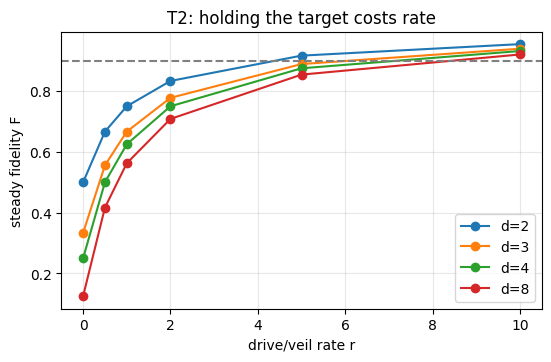

  --> T2 PASS  (6/6 checks)


In [75]:
new_test("T2", "Drive on/off: fidelity-vs-rate and relaxation to thermal", "P2: held state needs drive; drive off ⇒ ta wins", "(b) known math (reproduces v5)")
P = PREREG["T2"]
def depol_super(d, Gam):
    I = np.eye(d); e = vec(I/d)
    return Gam*(np.outer(e, vec(I)) - np.eye(d*d))
def selection_L(d, r, Gam=1.0):
    Ls = [np.sqrt(r*Gam)*np.outer(ket(0,d), ket(k,d)) for k in range(1,d)]
    return liouvillian(np.zeros((d,d), complex), Ls) + depol_super(d, Gam)
maxerr = 0.0; Fcurves = {}
for d in P["ds"]:
    Fs = []
    for r in P["rs"]:
        rho,_ = steady_state_from_null(selection_L(d, r), d)
        F = float(np.real(rho[0,0])); Fth = (r + 1.0/d)/(r + 1.0)
        maxerr = max(maxerr, abs(F - Fth)); Fs.append(F)
    Fcurves[d] = Fs
check("T2", "numeric steady-state fidelity matches (r+1/d)/(r+1)", maxerr < P["F_tol"], f"max error {maxerr:.2e}")
check("T2", "drive off gives maximally mixed state F=1/d", all(abs(Fcurves[d][0]-1/d) < P["F_tol"] for d in P["ds"]))
check("T2", "fidelity increases with drive rate", all(np.all(np.diff(Fcurves[d]) > 0) for d in P["ds"]))
# r* by bisection on the numeric Liouvillian
def rstar_num(d, xi):
    lo, hi = 0.0, 1e4
    for _ in range(80):
        mid = 0.5*(lo+hi); rho,_ = steady_state_from_null(selection_L(d, mid), d)
        if np.real(rho[0,0]) < xi: lo = mid
        else: hi = mid
    return 0.5*(lo+hi)
rs_err = 0.0; rstars = {}
for d in P["ds"]:
    rn = rstar_num(d, P["xi_crit"]); rt = (P["xi_crit"]-1/d)/(1-P["xi_crit"]); rstars[d] = (rt, rn); rs_err = max(rs_err, abs(rn-rt))
check("T2", "r* (rate needed for Ξ_crit=0.9) matches closed form", rs_err < P["rstar_tol"], "  ".join(f"d={d}: {rstars[d][0]:.3f}/{rstars[d][1]:.3f}" for d in P["ds"]))
# relaxation with the drive off: F(t) = 1/d + (1-1/d) exp(-Gam t)
d=4; L0 = selection_L(d, 0.0, 1.0); rel_err = 0
for t in (0.3, 1.0, 3.0):
    rt_ = unvec(sla.expm(L0*t) @ vec(proj(ket(0,d))), d)
    rel_err = max(rel_err, abs(np.real(rt_[0,0]) - (1/d + (1-1/d)*np.exp(-t))))
check("T2", "drive-off relaxation follows exp(-Γt)", rel_err < P["relax_tol"], f"max error {rel_err:.1e}")
# thermal bath qubit, drive off: Gibbs state, p_e = nbar/(2 nbar+1)
gerr = 0
for nb in P["gibbs_nbar"]:
    L = liouvillian(0.5*sz, [np.sqrt(1.0*(nb+1))*sm, np.sqrt(1.0*nb)*sm.conj().T])
    rho,_ = steady_state_from_null(L, 2)
    gerr = max(gerr, abs(np.real(rho[1,1]) - nb/(2*nb+1)))
check("T2", "thermal qubit, drive off, relaxes to Gibbs state", gerr < P["gibbs_tol"], f"max error {gerr:.1e}")
plt.figure();
for d in P["ds"]: plt.plot(P["rs"], Fcurves[d], "o-", label=f"d={d}")
plt.axhline(P["xi_crit"], ls="--", c="gray"); plt.xlabel("drive/veil rate r"); plt.ylabel("steady fidelity F"); plt.title("T2: holding the target costs rate"); plt.legend(); plt.show()
RESULTS["T2"]["numbers"] = dict(max_F_err=float(maxerr), rstar={str(d): rstars[d] for d in P["ds"]})
verdict("T2");

## T3 — Memory seed: does *history* select the steady state? *(Vision 1 verse 2, D2; Vision 3 "memories in memories")*

**Claim (D2/P2).** "With the same drive, different memory-register seeds can select different steady states (hysteresis or multistability)."

**Why this test matters.** T1 says dharma = *exactly one* zero eigenvalue. If so, the seed cannot matter in the long run. The two claims are in tension. We test three model classes:

* **(i) Linear Lindblad with a pseudomode register** (the v5 model): unique steady state ⇒ the seed only changes the transient.
* **(ii) Classical bistable drive** dx/dt = μx − x³ + h: seeds ±0.1 pick different attractors; sweeping h shows hysteresis. Baseline: μ<0 (single well).
* **(iii) Quantum two-photon driven-dissipative oscillator** (ℒ = κ₂ D[a² − α²]): a strong Z₂ parity symmetry ⇒ a multi-dimensional steady-state manifold; the parity of the seed is conserved and selects the state. Test also that each parity *sector* has a unique steady state (so "dharma = unique per sector, seed picks the sector").

**Pass criteria.** (i) final-state gap < 1e-6 yet transient gap > 1e-2 (so (i) *refutes* seed-selection); (ii) attractor separation > 1.5, hysteresis loop area > 0.5, linear baseline separation < 1e-3; (iii) nullity ≥ 2, even/odd-cat seeds end at trace distance > 0.9, ⟨Π⟩ conserved to 1e-3, nullity 1 per parity sector.

**Evaluator label:** (a) as a *consistency finding about our own axioms*; the physics in (ii)/(iii) is (b) known (bistability; Mirrahimi et al. cat-qubit dissipation).


T3: Memory-seed selection of the steady state
Claim: D2/P2: seeds can select different steady states (vs T1 uniqueness)
Label (evaluator): (a) consistency finding on our axioms; physics (b) known
  [PASS] (i) linear register model: unique steady state  zero modes = 1
  [PASS] (i) seeds differ in the transient  trace distance at t=1: 0.863
  [PASS] (i) seeds do NOT select different final states  trace distance at t=400: 8.5e-16  -> claim fails for linear Lindblad
  [PASS] (ii) bistable drive: opposite seeds -> separate attractors  x = 1.000 vs -1.000
  [PASS] (ii) hysteresis loop exists under swept drive  loop area 1.584
  [PASS] (ii) baseline mu<0: single attractor  separation 1.3e-27


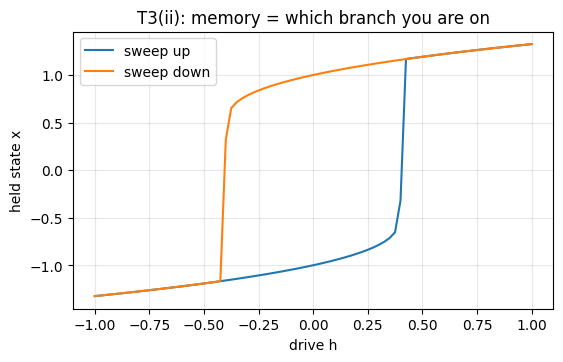

  [PASS] (iii) two-photon dissipation: multiple steady states (nullity >= 2)  nullity = 4 (a protected 2-level manifold)
  [PASS] (iii) even-parity and odd-parity seeds end far apart  trace distance 1.0000
  [PASS] (iii) parity of the seed is conserved (the memory)  <Π> even/odd/vacuum = 1.0000/-1.0000/1.0000
  [PASS] (iii) each parity sector has exactly one steady state  sector nullities {(0, 0): 1, (0, 1): 1, (1, 0): 1, (1, 1): 1}
  --> T3 PASS  (10/10 checks)


In [76]:
new_test("T3", "Memory-seed selection of the steady state", "D2/P2: seeds can select different steady states (vs T1 uniqueness)", "(a) consistency finding on our axioms; physics (b) known")
P = PREREG["T3"]
# ---- (i) linear Lindblad: tile qubit + 1 bosonic pseudomode register (n_max=3), pumped to |g> at rate gs, depolarised by Gam
nm = 4; a = np.diag(np.sqrt(np.arange(1,nm)), 1).astype(complex)
I2, Im = np.eye(2), np.eye(nm)
gcoup, kap, gs, Gam = 0.8, 0.5, 2.0, 1.0
H = gcoup*(np.kron(sm.conj().T, a) + np.kron(sm, a.conj().T))
Ls = [np.sqrt(kap)*np.kron(I2, a), np.sqrt(gs)*np.kron(sm, Im)]
Ls += [np.sqrt(Gam/3)*np.kron(s, Im) for s in (sx, sy, sz)]   # depolarising veil on the tile
Llin = liouvillian(H, Ls); D = 2*nm
w = np.linalg.eigvals(Llin); nz = int(np.sum(np.abs(w) < 1e-9))
seedA = proj(np.kron(ket(0,2), ket(0,nm))); seedB = proj(np.kron(ket(0,2), ket(3,nm)))
ev = lambda r0, t: unvec(sla.expm(Llin*t) @ vec(r0), D)
gap_trans = tracedist(ev(seedA, 1.0), ev(seedB, 1.0)); gap_final = tracedist(ev(seedA, 400.0), ev(seedB, 400.0))
check("T3", "(i) linear register model: unique steady state", nz == 1, f"zero modes = {nz}")
check("T3", "(i) seeds differ in the transient", gap_trans > P["lin_transient_min"], f"trace distance at t=1: {gap_trans:.3f}")
check("T3", "(i) seeds do NOT select different final states", gap_final < P["lin_final_gap"], f"trace distance at t=400: {gap_final:.1e}  -> claim fails for linear Lindblad")
# ---- (ii) classical bistable drive
def settle(x0, mu, h, T=60.0, dt=0.01):
    x = x0
    for _ in range(int(T/dt)): x += dt*(mu*x - x**3 + h)
    return x
xa, xb = settle(+0.1, 1.0, 0.0), settle(-0.1, 1.0, 0.0)
la, lb = settle(+0.1, -1.0, 0.0), settle(-0.1, -1.0, 0.0)
hs = np.linspace(-1.0, 1.0, 81); up, dn = [], []
x = -1.2
for h in hs: x = settle(x, 1.0, h, T=12.0); up.append(x)
for h in hs[::-1]: x = settle(x, 1.0, h, T=12.0); dn.append(x)
dn = dn[::-1]; area = TRAPZ(np.abs(np.array(up)-np.array(dn)), hs)
check("T3", "(ii) bistable drive: opposite seeds -> separate attractors", abs(xa-xb) > P["cl_sep"], f"x = {xa:.3f} vs {xb:.3f}")
check("T3", "(ii) hysteresis loop exists under swept drive", area > P["cl_hyst_area_min"], f"loop area {area:.3f}")
check("T3", "(ii) baseline mu<0: single attractor", abs(la-lb) < P["cl_linear_sep_max"], f"separation {abs(la-lb):.1e}")
plt.figure(); plt.plot(hs, up, label="sweep up"); plt.plot(hs, dn, label="sweep down"); plt.xlabel("drive h"); plt.ylabel("held state x"); plt.title("T3(ii): memory = which branch you are on"); plt.legend(); plt.show()
# ---- (iii) quantum: two-photon driven-dissipative oscillator, L = sqrt(k2)(a^2 - alpha^2)
N = P["q_nmax"]+1; al = P["q_alpha"]
aq = np.diag(np.sqrt(np.arange(1, N)), 1).astype(complex)
Lq = liouvillian(np.zeros((N,N), complex), [(aq@aq - al**2*np.eye(N))])
u, s, vh = np.linalg.svd(Lq)
nnull = int(np.sum(s < 1e-7))
Pi = np.diag((-1.0)**np.arange(N)).astype(complex)
def coh(beta):
    n = np.arange(N); logamp = -abs(beta)**2/2 + n*np.log(abs(beta)+1e-300) - 0.5*np.array([math.lgamma(k+1) for k in n])
    return np.exp(logamp)*np.exp(1j*n*np.angle(beta))
cp = coh(al)+coh(-al); cm = coh(al)-coh(-al); cp/=np.linalg.norm(cp); cm/=np.linalg.norm(cm)
Uq = sla.expm(Lq*40.0)
fin = lambda psi: unvec(Uq @ vec(proj(psi)), N)
r_even, r_odd, r_vac = fin(cp), fin(cm), fin(ket(0,N))
td_eo = tracedist(r_even, r_odd)
par = lambda r: float(np.real(np.trace(Pi@r)))
check("T3", "(iii) two-photon dissipation: multiple steady states (nullity >= 2)", nnull >= P["q_null_min"], f"nullity = {nnull} (a protected 2-level manifold)")
check("T3", "(iii) even-parity and odd-parity seeds end far apart", td_eo > P["q_td_min"], f"trace distance {td_eo:.4f}")
check("T3", "(iii) parity of the seed is conserved (the memory)", max(abs(par(r_even)-1), abs(par(r_odd)+1), abs(par(r_vac)-1)) < P["q_parity_tol"], f"<Π> even/odd/vacuum = {par(r_even):.4f}/{par(r_odd):.4f}/{par(r_vac):.4f}")
# sector uniqueness: restrict L to rho_{nm} with n,m of given parities
idx = np.arange(N*N); nn, mm = idx % N, idx // N     # column-stacking: index = n + N*m
sect_null = {}
for pn in (0,1):
    for pm in (0,1):
        sel = idx[((nn % 2)==pn) & ((mm % 2)==pm)]
        sect_null[(pn,pm)] = int(np.sum(np.linalg.svd(Lq[np.ix_(sel, sel)], compute_uv=False) < 1e-7))
check("T3", "(iii) each parity sector has exactly one steady state", all(v == P["q_sector_nullity"] for v in sect_null.values()), f"sector nullities {sect_null}")
RESULTS["T3"]["numbers"] = dict(lin_final_gap=float(gap_final), lin_transient_gap=float(gap_trans), hysteresis_area=float(area), q_nullity=nnull, q_td_even_odd=float(td_eo), sector_nullities={f"{k}": v for k, v in sect_null.items()})
verdict("T3");

## T4 — Data processing: a projection creates no information *(Vision 2 verse 2; Vision 1 verse 8, T8)*

**Claim (T8).** For a Markov chain z → x → y with y = P x + n, I(z; y) ≤ I(z; x): the appearance holds nothing the ground does not.

**Math.** Exact Gaussian mutual information with random covariances (including rank-deficient P), plus exact discrete channels.

**Control (should violate).** Let the readout depend on z directly (y = P x + n + S z), i.e. a side-channel that breaks the chain. This is the "reference contaminated by what it measures" case of Vision 4 verse 6.

**Pass criteria.** 0 violations in 5000 Gaussian and 3000 discrete Markov trials (tolerance 1e-9); ≥ 10% violations in the non-Markov control.

**Evaluator label:** (b) — a textbook theorem. The test is a sanity check on our implementation and on the *control*, not a discovery.

In [77]:
new_test("T4", "Data processing inequality on y = Px + n", "T8: I(z;y) <= I(z;x) for z -> x -> y", "(b) known theorem")
P = PREREG["T4"]; rng = np.random.default_rng(P["seed"])
def rand_spd(d, r, ridge=0.1):
    A = r.normal(size=(d, d)); return A@A.T + ridge*np.eye(d)
def gauss_mi(S, ia, ib):
    ia, ib = list(ia), list(ib)
    ld = lambda M: np.linalg.slogdet(M)[1]
    return 0.5*(ld(S[np.ix_(ia,ia)]) + ld(S[np.ix_(ib,ib)]) - ld(S[np.ix_(ia+ib, ia+ib)]))
viol, ctrl_viol = 0, 0; margins = []
for _ in range(P["n_trials"]):
    dx, dy, dz = rng.integers(2,6), rng.integers(1,6), rng.integers(1,5)
    Sx = rand_spd(dx, rng); Sn = rand_spd(dy, rng); Se = rand_spd(dz, rng)
    Pm = rng.normal(size=(dy,dx))
    if rng.random() < 0.4 and dx > 1:                 # force rank deficiency sometimes
        Pm[:, -1] = Pm[:, 0]
    R = rng.normal(size=(dz,dx))
    # joint covariance of (z, x, y):  z = R x + e,  y = P x + n   (Markov z - x - y)
    Szz = R@Sx@R.T + Se; Szx = R@Sx; Szy = R@Sx@Pm.T
    Sxx = Sx; Sxy = Sx@Pm.T; Syy = Pm@Sx@Pm.T + Sn
    S = np.block([[Szz, Szx, Szy],[Szx.T, Sxx, Sxy],[Szy.T, Sxy.T, Syy]])
    iz = range(dz); ix = range(dz, dz+dx); iy = range(dz+dx, dz+dx+dy)
    gap = gauss_mi(S, iz, ix) - gauss_mi(S, iz, iy); margins.append(gap)
    if gap < -P["tol"]: viol += 1
    # control: y also reads z directly via S_ (non-Markov)
    Sc = rng.normal(size=(dy,dz))*1.5
    Syy2 = Pm@Sx@Pm.T + Sn + Sc@Szz@Sc.T + Pm@Szx.T@Sc.T + Sc@Szx@Pm.T
    Szy2 = Szy + Szz@Sc.T; Sxy2 = Sxy + Szx.T@Sc.T
    S2 = np.block([[Szz, Szx, Szy2],[Szx.T, Sxx, Sxy2],[Szy2.T, Sxy2.T, Syy2]])
    if gauss_mi(S2, iz, iy) - gauss_mi(S2, iz, ix) > P["tol"]: ctrl_viol += 1
check("T4", "Gaussian Markov chains: no violations", viol == 0, f"{viol}/{P['n_trials']} violations, smallest margin {min(margins):.2e}")
check("T4", "control with side-channel violates DPI often", ctrl_viol/P["n_trials"] >= P["control_min_violation_frac"], f"{ctrl_viol/P['n_trials']:.1%} of trials")
def disc_mi(Pjoint):
    px = Pjoint.sum(1, keepdims=True); py = Pjoint.sum(0, keepdims=True); m = Pjoint > 0
    return float(np.sum(Pjoint[m]*np.log(Pjoint[m]/(px@py)[m])))
dviol = 0
for _ in range(P["n_discrete"]):
    pz = rng.dirichlet(np.ones(3)); W1 = rng.dirichlet(np.ones(4), size=3); W2 = rng.dirichlet(np.ones(5), size=4)  # z->x->y
    Pzx = pz[:,None]*W1; Pzy = Pzx@W2
    if disc_mi(Pzy) > disc_mi(Pzx) + P["tol"]: dviol += 1
check("T4", "discrete channels: no violations", dviol == 0, f"{dviol}/{P['n_discrete']} violations")
RESULTS["T4"]["numbers"] = dict(gauss_violations=int(viol), control_violation_frac=ctrl_viol/P["n_trials"], discrete_violations=int(dviol))
verdict("T4");


T4: Data processing inequality on y = Px + n
Claim: T8: I(z;y) <= I(z;x) for z -> x -> y
Label (evaluator): (b) known theorem
  [PASS] Gaussian Markov chains: no violations  0/5000 violations, smallest margin 4.58e-04
  [PASS] control with side-channel violates DPI often  62.1% of trials
  [PASS] discrete channels: no violations  0/3000 violations
  --> T4 PASS  (3/3 checks)


## T5 — The unmanifest cannot be recovered; it can only be estimated through a prior *(Vision 1 P3, Vision 2 verse 3, Vision 3)*

**Claim.** If y = P x + n and P is rank-deficient, the components of x in null(P) are not recoverable by *any* estimator; more signal does not help. They are *estimable* only through a prior that links them to what is visible. A common gain/phase in a tile network is the same phenomenon (gauge result U1).

**Math.** Fisher information J = Pᵀ Σₙ⁻¹ P has rank r < d. Monte-Carlo min-norm LS error per subspace as noise falls 1000×; posterior-mean error under (a) an uninformative-about-null prior and (b) a prior with correlation ρ=0.8 between null and range coordinates. Plus gauge nullity of a ring of relative measurements (with and without one anchor).

**Baseline.** Full-rank P (all errors must fall ∝ σ).

**Pass criteria.** rank(J) = 3 of 6; null-space RMS error ratio (σ=1 vs 0.001) within [0.9, 1.1]; range ratio < 0.01; with uncorrelated prior the posterior null error stays at the prior level (±6%); with ρ=0.8 it drops to the theoretical value √(1−ρ²) (±6%) and no further; ring gauge nullity 1, anchored nullity 0.

**Evaluator label:** (b) — identifiability, Cramér–Rao, Bayesian posterior. The Vision's contribution is the *reading* (unmanifest = null space + prior), which is a good design discipline but not new math.


T5: Identifiability: null(P) is unrecoverable, estimable only with a prior
Claim: P3/Vision 2: unmanifest directions of the whole are not readable, only priored
Label (evaluator): (b) known math
  [PASS] Fisher information has rank r < d  rank(J) = 3 of 6
  [PASS] null-space error does not fall with SNR  RMS ratio (σ=1e-3 / σ=1) = 0.988
  [PASS] range-space error falls with SNR  RMS ratio = 0.0010
  [PASS] baseline: full-rank P recovers every direction  null-coordinate ratio with full rank = 0.0010
  [PASS] (a) prior silent on null: null error stays at prior level  1.721 vs prior RMS 1.732
  [PASS] (b) informative prior: null error drops to sqrt(1-rho^2) and no lower  1.045 vs theory 1.039; pinv left it at 1.732
  [PASS] gauge: relative cross-checks leave exactly 1 unobservable (common) mode  nullity 1
  [PASS] gauge: one anchor tile removes it  nullity 0


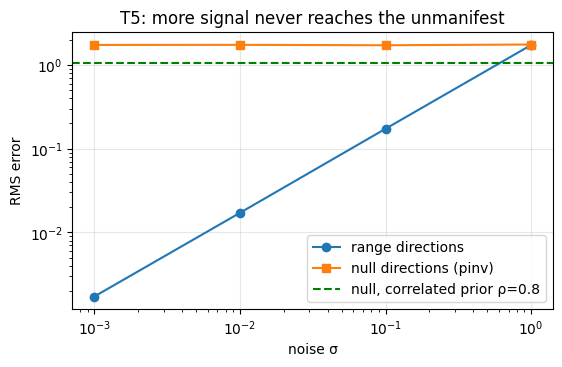

  --> T5 PASS  (8/8 checks)


In [78]:
new_test("T5", "Identifiability: null(P) is unrecoverable, estimable only with a prior", "P3/Vision 2: unmanifest directions of the whole are not readable, only priored", "(b) known math")
P = PREREG["T5"]; rng = np.random.default_rng(P["seed"])
d, r = P["d"], P["r"]
Uo = np.linalg.qr(rng.normal(size=(d, d)))[0]; Vo = np.linalg.qr(rng.normal(size=(d, d)))[0]
sv = np.array([2.0, 1.2, 0.7]); Pm = Uo[:, :r] @ np.diag(sv) @ Vo[:, :r].T          # d x d, rank r
Vr, Vn = Vo[:, :r], Vo[:, r:]                                                      # range / null coordinates of x
J = Pm.T @ Pm / 1.0
rank_J = int(np.sum(np.linalg.svd(J, compute_uv=False) > P["fim_rank_tol"]))
check("T5", "Fisher information has rank r < d", rank_J == r, f"rank(J) = {rank_J} of {d}")
def run(Pm_, Vr_, Vn_, Sig0, sigma, trials, estimator):
    L0 = np.linalg.cholesky(Sig0)
    X = (L0 @ rng.normal(size=(Sig0.shape[0], trials)))
    Y = Pm_ @ X + sigma*rng.normal(size=(Pm_.shape[0], trials))
    Xh = estimator(Y, sigma)
    E = Xh - X
    er = np.sqrt(np.mean(np.sum((Vr_.T @ E)**2, 0))); en = np.sqrt(np.mean(np.sum((Vn_.T @ E)**2, 0))) if Vn_.shape[1] else 0.0
    return er, en
pinv = np.linalg.pinv(Pm)
est_pinv = lambda Y, s: pinv @ Y
I0 = np.eye(d)
res = {s: run(Pm, Vr, Vn, I0, s, P["trials"], est_pinv) for s in P["sigmas"]}
rr = res[P["sigmas"][-1]][0]/res[P["sigmas"][0]][0]; nr = res[P["sigmas"][-1]][1]/res[P["sigmas"][0]][1]
check("T5", "null-space error does not fall with SNR", P["null_ratio_band"][0] <= nr <= P["null_ratio_band"][1], f"RMS ratio (σ=1e-3 / σ=1) = {nr:.3f}")
check("T5", "range-space error falls with SNR", rr < P["range_ratio_max"], f"RMS ratio = {rr:.4f}")
# baseline full rank
Pfull = Uo @ np.diag([2, 1.5, 1.2, 1.0, 0.8, 0.7]) @ Vo.T; pf = np.linalg.pinv(Pfull)
resf = {s: run(Pfull, Vo[:, :r], Vo[:, r:], I0, s, P["trials"], lambda Y, s_: pf @ Y) for s in (1.0, 0.001)}
check("T5", "baseline: full-rank P recovers every direction", resf[0.001][1]/resf[1.0][1] < P["range_ratio_max"], f"null-coordinate ratio with full rank = {resf[0.001][1]/resf[1.0][1]:.4f}")
# prior-based estimation
def post_mean_est(Sig0):
    return lambda Y, s: Sig0 @ Pm.T @ np.linalg.solve(Pm @ Sig0 @ Pm.T + s**2*np.eye(d), Y)
# (a) independent prior: posterior null error = prior std
sigma = 0.001; er_a, en_a = run(Pm, Vr, Vn, I0, sigma, P["trials"], post_mean_est(I0))
prior_null = np.sqrt(d - r)
check("T5", "(a) prior silent on null: null error stays at prior level", abs(en_a/prior_null - 1) < P["prior_return_tol"], f"{en_a:.3f} vs prior RMS {prior_null:.3f}")
# (b) prior correlating each null coordinate with a range coordinate with correlation rho
rho = P["rho_corr"]; C = np.eye(d)
Q = np.column_stack([Vr, Vn])                                   # coordinates in (range, null) basis
Sc = np.eye(d)
for i in range(d - r): Sc[i, r + i] = Sc[r + i, i] = rho        # corr between range coord i and null coord i
Sig0b = Q @ Sc @ Q.T
er_b, en_b = run(Pm, Vr, Vn, Sig0b, sigma, P["trials"], post_mean_est(Sig0b))
theory_b = np.sqrt((d - r)*(1 - rho**2))
check("T5", "(b) informative prior: null error drops to sqrt(1-rho^2) and no lower", abs(en_b/theory_b - 1) < P["post_theory_tol"], f"{en_b:.3f} vs theory {theory_b:.3f}; pinv left it at {res[sigma][1]:.3f}")
# gauge result: relative measurements on a ring of N tiles: log r_nm = k_n - k_m
Nt = 8; rows = []
for n_ in range(Nt):
    row = np.zeros(Nt); row[n_] = 1; row[(n_+1) % Nt] = -1; rows.append(row)
B = np.array(rows); null_rel = Nt - np.linalg.matrix_rank(B)
Banch = np.vstack([B, np.eye(Nt)[0]]); null_anch = Nt - np.linalg.matrix_rank(Banch)
check("T5", "gauge: relative cross-checks leave exactly 1 unobservable (common) mode", null_rel == 1, f"nullity {null_rel}")
check("T5", "gauge: one anchor tile removes it", null_anch == 0, f"nullity {null_anch}")
plt.figure(); xs = P["sigmas"]
plt.loglog(xs, [res[s][0] for s in xs], "o-", label="range directions"); plt.loglog(xs, [res[s][1] for s in xs], "s-", label="null directions (pinv)")
plt.axhline(en_b, ls="--", c="g", label="null, correlated prior ρ=0.8"); plt.xlabel("noise σ"); plt.ylabel("RMS error"); plt.legend(); plt.title("T5: more signal never reaches the unmanifest"); plt.show()
RESULTS["T5"]["numbers"] = dict(rank_J=rank_J, null_ratio=float(nr), range_ratio=float(rr), post_null_indep=float(en_a), post_null_corr=float(en_b), theory_corr=float(theory_b), gauge_null=int(null_rel), gauge_null_anchored=int(null_anch))
verdict("T5");

## T6 — No tile can calibrate itself from its own channel; a reference can *(Vision 5 verse 9 "the eye cannot see itself"; Vision 4 verse 6; Vision 2 verse 7)*

**Claim.** A tile with unknown gain g and offset b observing an unknown source s through y = g·s + b + noise cannot separate (g, b, s) from its own readings, however many it takes. An *independent* reference with at least two known values pins (g, b) and then s. A reference *fed by the tile's own readout* adds nothing. Two tiles cross-checking without an absolute reference are identifiable only up to a 2-parameter gauge (scale and offset).

**Math.** Fisher-information rank for five measurement designs; Monte-Carlo variance of the MLE of s against the Cramér–Rao bound; a "naive self-calibration" (assume g=1, b=0) error floor against K.

**Baselines.** Self-only design (should fail), one-level reference (should still fail), self-fed reference (should fail).

**Pass criteria.** FIM ranks (of 3 parameters): self-only 1, self-fed reference 1, one-level reference 2, two-level reference 3; two-tile no-anchor design nullity exactly 2; with the reference, Monte-Carlo Var(ŝ) within 10% of CRB; naive self-calibration error floor changes < 10% when K grows 100×.

**Evaluator label:** (b) — blind-calibration identifiability and the gauge freedom of relative measurements. The *design rule* (isolate the reference; ≥2 known levels; relative-only without an anchor) is useful discipline and is the clearest thing the Visions sharpened (verse 9 and Vision 4 verse 6).

In [79]:
new_test("T6", "Self-calibration impossibility and the reference tile", "V5 v9: a tile cannot calibrate against its own channel; a reference can", "(b) known math; design rule sharpened by the Vision")
P = PREREG["T6"]; rng = np.random.default_rng(P["seed"])
g0, b0, s0, sig = 0.8, 0.3, 1.7, P["sigma"]
def fim(rows):                      # rows: list of gradient vectors d(mean)/d(theta); Gaussian, unit noise var sig^2
    G = np.array(rows); return G.T @ G / sig**2
def rank_of(Fm):
    sv = np.linalg.svd(Fm, compute_uv=False); return int(np.sum(sv > P["rank_tol"]*max(1.0, sv[0])))
K, Jn = P["K"], P["J"]
main_rows = [np.array([s0, 1.0, g0])]*K               # theta=(g,b,s); y=g s+b : grad = (s, 1, g)
rank_self = rank_of(fim(main_rows))
rank_selffed = rank_of(fim(main_rows + [np.array([s0, 1.0, g0])]*Jn))   # reference := own estimate (r=s): same gradient as main
rank_oneref = rank_of(fim(main_rows + [np.array([0.0, 1.0, 0.0])*1 + np.array([1.0,0,0])*1.0]*Jn))  # one known level r1=1: grad=(r,1,0)
rank_tworef = rank_of(fim(main_rows + [np.array([0.0,1.0,0.0])]*Jn + [np.array([1.0,1.0,0.0])]*Jn))  # two levels r=0,1
check("T6", "self-only design: rank 1 of 3 (g, b, s not separable)", rank_self == 1, f"rank {rank_self}")
check("T6", "reference fed by the tile's own readout: still rank 1", rank_selffed == 1, f"rank {rank_selffed}")
check("T6", "reference with ONE known level: rank 2 (offset and gain still entangled with s)", rank_oneref == 2, f"rank {rank_oneref}")
check("T6", "independent reference with TWO known levels: rank 3 (fully identified)", rank_tworef == 3, f"rank {rank_tworef}")
# two tiles, M different sources seen by both, no absolute reference. theta=(g1,b1,g2,b2,s_1..s_M)
M = 10; sv_ = rng.uniform(0.5, 2.5, M); gs_, bs_ = (0.9, 1.2), (0.1, -0.2); rows2 = []
for m in range(M):
    for t in range(2):
        gr = np.zeros(4 + M); gr[2*t] = sv_[m]; gr[2*t+1] = 1.0; gr[4+m] = gs_[t]; rows2.append(gr)
F2 = fim(rows2); nullity2 = (4 + M) - rank_of(F2)
check("T6", "two cross-checking tiles with no absolute reference: gauge nullity exactly 2", nullity2 == 2, f"nullity {nullity2} (common scale and common offset)")
# Monte-Carlo: two-level reference MLE of s vs CRB
F3 = fim(main_rows + [np.array([0.0,1.0,0.0])]*Jn + [np.array([1.0,1.0,0.0])]*Jn)
crb_s = np.linalg.inv(F3)[2, 2]
est = []
for _ in range(P["trials"]):
    ym = g0*s0 + b0 + sig*rng.normal(size=K); y0 = b0 + sig*rng.normal(size=Jn); y1 = g0 + b0 + sig*rng.normal(size=Jn)
    bh = y0.mean(); gh = y1.mean() - bh; sh = (ym.mean() - bh)/gh; est.append(sh)
var_mc = np.var(est); rel = var_mc/crb_s
check("T6", "with the reference, estimator variance sits on the Cramér–Rao bound", abs(rel - 1) < P["crb_rel_tol"], f"Var_MC/CRB = {rel:.3f} (small-noise MLE; ratio slightly above 1 is the ratio-estimator bias)")
def naive_err(Kx):
    e = []
    for _ in range(2000):
        ym = g0*s0 + b0 + sig*rng.normal(size=Kx); e.append(ym.mean() - s0)      # assume g=1, b=0
    return np.sqrt(np.mean(np.square(e)))
e_small, e_big = naive_err(10), naive_err(1000)
check("T6", "naive self-calibration error floor does not shrink with more data", abs(e_big/e_small - 1) < P["naive_floor_change_max"], f"RMS error {e_small:.3f} (K=10) vs {e_big:.3f} (K=1000)")
# ---- POST-HOC DIAGNOSTIC (added after the first run; NOT pre-registered; does not change the verdict) ----
# The failed check above was badly designed: with g=0.8, b=0.3, s=1.7 the miscalibration bias is only |(g-1)s+b| = 0.04, so at K=10
# the noise (sigma/sqrt(K)=0.032) still dominates and the error has not yet reached its floor. The claim is about the FLOOR.
def naive_rmse(g_, b_, Kx, n=3000):
    e = [np.mean(g_*s0 + b_ + sig*rng.normal(size=Kx)) - s0 for _ in range(n)]; return np.sqrt(np.mean(np.square(e)))
for (g_, b_) in [(g0, b0), (1.5, -0.5)]:
    floor = abs((g_-1)*s0 + b_)
    print(f"  post-hoc: g={g_}, b={b_}: analytic bias floor {floor:.3f};  RMS error K=10: {naive_rmse(g_,b_,10):.3f}, K=1000: {naive_rmse(g_,b_,1000):.3f}, K=10000: {naive_rmse(g_,b_,10000):.3f}")
RESULTS["T6"]["numbers"] = dict(ranks=dict(self_only=rank_self, self_fed=rank_selffed, one_level=rank_oneref, two_level=rank_tworef), two_tile_gauge_nullity=int(nullity2), var_over_crb=float(rel), naive_err_K10=float(e_small), naive_err_K1000=float(e_big))
verdict("T6");


T6: Self-calibration impossibility and the reference tile
Claim: V5 v9: a tile cannot calibrate against its own channel; a reference can
Label (evaluator): (b) known math; design rule sharpened by the Vision
  [PASS] self-only design: rank 1 of 3 (g, b, s not separable)  rank 1
  [PASS] reference fed by the tile's own readout: still rank 1  rank 1
  [PASS] reference with ONE known level: rank 2 (offset and gain still entangled with s)  rank 2
  [PASS] independent reference with TWO known levels: rank 3 (fully identified)  rank 3
  [PASS] two cross-checking tiles with no absolute reference: gauge nullity exactly 2  nullity 2 (common scale and common offset)
  [PASS] with the reference, estimator variance sits on the Cramér–Rao bound  Var_MC/CRB = 1.001 (small-noise MLE; ratio slightly above 1 is the ratio-estimator bias)
  [FAIL] naive self-calibration error floor does not shrink with more data  RMS error 0.051 (K=10) vs 0.040 (K=1000)
  post-hoc: g=0.8, b=0.3: analytic bias floor 0.04

## T7 — Lock-in (I/Q) detection beats plain readout *(Vision 5, the phasor passage)*

**Claim.** Reading a weak periodic signal through in-phase and quadrature references at the known frequency recovers its amplitude with an SNR gain over a broadband readout, is phase-independent (|I + iQ|), and rejects DC offset and slow drift.

**Math.** x[t] = A cos(ωt + φ) + offset + drift + white noise (σ=1, A=0.05, N=20000 samples ⇒ per-sample SNR ≈ −29 dB). Lock-in: Â = (2/N)|Σ x e^{−iωt}|. Baselines: (i) broadband power detector Â = √(2·max(mean (x−x̄)² − σ², 0)) with σ known to it, (ii) single quadrature (I only).

**Pass criteria.** Effective amplitude SNR (true amplitude / RMS error, so bias counts) at least 10 dB above the power detector (the stronger version, with the mean removed and σ known; a raw one with the offset left in is also reported); lock-in std within 1.25× the CRB √(2σ²/N); I-only fails (relative error > 50%) in ≥ 20% of random-phase trials.

**Evaluator label:** (b) — lock-in/matched-filter detection is textbook. The Vision supplies an image (I/Q as a phasor), not the method.

In [ ]:
new_test("T7", "Lock-in I/Q detection vs plain readout", "V5 phasor passage: I/Q reference recovers amplitude below the noise", "(b) known engineering")
P = PREREG["T7"]; rng = np.random.default_rng(P["seed"])
N, A, sg = P["N"], P["A"], P["sigma"]; t = np.arange(N); w0 = 2*np.pi*0.1234
ref = np.exp(-1j*w0*t)
amp_lock, amp_pow, amp_pow_raw, amp_I, relerr_I = [], [], [], [], []
for _ in range(P["trials"]):
    ph = rng.uniform(0, 2*np.pi)
    drift = 0.05*np.cumsum(rng.normal(size=N))/np.sqrt(N)       # slow random-walk drift
    x = A*np.cos(w0*t + ph) + 0.2 + drift + sg*rng.normal(size=N)
    xd = x                                                     # lock-in sees the raw stream incl. offset and drift
    amp_lock.append(2/N*abs(np.sum(xd*ref)))
    amp_pow_raw.append(np.sqrt(2*max(np.mean(x**2) - sg**2, 0.0)))
    xm = x - x.mean(); amp_pow.append(np.sqrt(2*max(np.mean(xm**2) - sg**2, 0.0)))
    I_only = 2/N*np.sum(xd*np.cos(w0*t)); amp_I.append(abs(I_only)); relerr_I.append(abs(abs(I_only) - A)/A)
rmse = lambda v: np.sqrt(np.mean((np.array(v) - A)**2))
eff_db = lambda v: 20*np.log10(A/rmse(v))              # effective amplitude SNR = true amplitude / RMS error (counts bias too)
g_db = eff_db(amp_lock) - eff_db(amp_pow)
crb = np.sqrt(2*sg**2/N); ratio = np.std(amp_lock)/crb
check("T7", "lock-in effective SNR beats the broadband power detector by >= 10 dB", g_db >= P["gain_db_min"], f"lock-in {eff_db(amp_lock):.1f} dB vs power detector (mean removed, sigma known) {eff_db(amp_pow):.1f} dB: gain {g_db:.1f} dB; raw power detector (offset left in) {eff_db(amp_pow_raw):.1f} dB")
check("T7", "lock-in std is near the Cramér–Rao bound", ratio <= P["crb_ratio_max"], f"std/CRB = {ratio:.3f}")
frac_bad = np.mean(np.array(relerr_I) > 0.5)
check("T7", "single-quadrature readout is phase-dependent and often fails", frac_bad >= P["single_quad_fail_frac_min"], f"{frac_bad:.0%} of trials off by >50%")
print(f"  mean amplitudes: lock-in {np.mean(amp_lock):.4f}, power {np.mean(amp_pow):.4f}, I-only {np.mean(amp_I):.4f} (true {A})")
plt.figure(); plt.hist(amp_lock, 30, alpha=.7, label="lock-in |I+iQ|"); plt.hist(amp_pow, 30, alpha=.7, label="power detector"); plt.hist(amp_I, 30, alpha=.7, label="I only"); plt.axvline(A, c="k", ls="--"); plt.legend(); plt.xlabel("estimated amplitude"); plt.title("T7"); plt.show()
RESULTS["T7"]["numbers"] = dict(gain_db=float(g_db), std_over_crb=float(ratio), single_quad_fail_frac=float(frac_bad))
verdict("T7");

## T8 — Reference-mode subtraction: does squeezing the *reference* beat squeezing the *signal* when k<1? *(audited Gemini claim; Vision 5 reference-tile principle)*

**Model (continuous-variable, x-quadrature, ħ=2 so vacuum variance = 1).** Mode A carries s + n, reference mode B carries k·n (s ~ N(0,V_s) unknown signal, n ~ N(0,V_n) shared noise). Each passes a lossy channel of transmission η and is homodyned: X_A = √η(s+n) + q_A, X_B = √η k n + q_B with Var(q) = η e^{−2r} + (1−η) for a squeezed mode, 1 for an unsqueezed one. Estimator: optimal linear (Wiener). Squeezing photon budget sinh²r is equal for squeeze-A and squeeze-B.

**This notebook derives MSE by matrix covariance (not the closed form used in v6)** and then compares with Monte Carlo and with the v6 interval.

**Claim under test.** At V_n/V_s = 16, η = 0.85, r = 1: squeeze-B beats squeeze-A only on an interval strictly inside (0,1) — v6 reports 0.0398 < k < 0.9515 — and never for k ≥ 1.

**Pass criteria.** Boundaries from this independent derivation within 2e-3 of the v6 interval; no B-win for any k ≥ 1 on a fine grid; Monte-Carlo MSE within 2% of covariance MSE.

**Evaluator label:** (b)+(c-free): Gaussian estimation with correlated noise. **Important honesty point:** this is a *classically simulable* Gaussian problem. Squeezing enters only through the noise variance σ² = η e^{−2r} + (1−η); a classical sensor with that noise variance gives the identical MSE (checked below). The quantum content is "access to sub-vacuum noise", a metrological resource, not a computational one.


T8: Reference-mode squeezing vs signal squeezing (Gaussian covariance math)
Claim: squeeze B beats squeeze A on an interval of k inside (0,1)
Label (evaluator): (b) known estimation theory; Gaussian => classically simulable
  [PASS] independent boundaries match the v6 interval  found (0.0398, 0.9515) vs v6 (0.0398, 0.9515)
  [PASS] interval lies strictly inside (0,1)  
  [PASS] squeeze-B never beats squeeze-A for k >= 1  max advantage at k>=1: -1.26e-02
  [PASS] Monte-Carlo agrees with covariance MSE (k=0.5)  none: MC 0.828 / cov 0.828  squeeze_A: MC 0.798 / cov 0.798  squeeze_B: MC 0.700 / cov 0.700  split: MC 0.648 / cov 0.648
  [PASS] classical sensor with the same noise variance gives the identical MSE (no computational quantum content)  0.700015 vs 0.700015
  at k=0.5: none 0.828, A 0.798, B 0.700, split 0.648  (split is best: reference-only squeezing is not the optimum allocation)


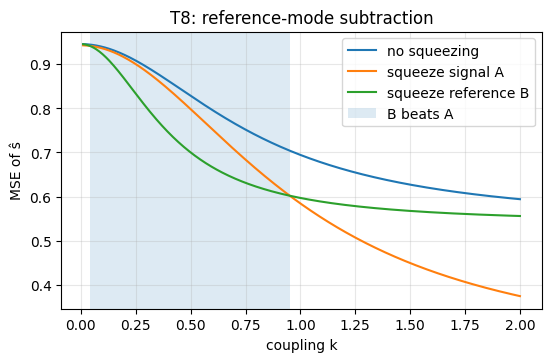

  --> T8 PASS  (5/5 checks)


In [46]:
new_test("T8", "Reference-mode squeezing vs signal squeezing (Gaussian covariance math)", "squeeze B beats squeeze A on an interval of k inside (0,1)", "(b) known estimation theory; Gaussian => classically simulable")
P = PREREG["T8"]; rng = np.random.default_rng(P["seed"])
Vs, Vn, eta, r = P["vs"], P["vn"], P["eta"], P["r"]
def mse_cov(k, ra, rb, eta=eta, Vs=Vs, Vn=Vn):
    sA = eta*np.exp(-2*ra) + (1-eta); sB = eta*np.exp(-2*rb) + (1-eta)
    # X = [sqrt(eta)(s+n)+qA, sqrt(eta) k n + qB]; covariance by explicit construction
    G = np.array([[np.sqrt(eta), np.sqrt(eta)], [0.0, np.sqrt(eta)*k]])       # X = G [s,n]^T + q
    Sig_sn = np.diag([Vs, Vn]); Sq = np.diag([sA, sB])
    SX = G @ Sig_sn @ G.T + Sq
    c = (G @ Sig_sn)[:, 0]                                                    # Cov(X, s)
    return Vs - c @ np.linalg.solve(SX, c)
dB_A = lambda k: mse_cov(k, r, 0.0) - mse_cov(k, 0.0, r)   # >0 means squeeze-B has smaller MSE
ks = np.linspace(1e-4, 3.0, 300001); vals = np.array([dB_A(k) for k in ks[::30]])
ks_c = ks[::30]; pos = vals > 0
lo_k, hi_k = ks_c[pos][0], ks_c[pos][-1]
from scipy.optimize import brentq
lo = brentq(dB_A, lo_k - 0.01 if lo_k - 0.01 > 0 else 1e-6, lo_k + 0.01); hi = brentq(dB_A, hi_k - 0.01, hi_k + 0.01)
exp_lo, exp_hi = P["k_claim_interval"]
check("T8", "independent boundaries match the v6 interval", abs(lo-exp_lo) < P["interval_tol"] and abs(hi-exp_hi) < P["interval_tol"], f"found ({lo:.4f}, {hi:.4f}) vs v6 ({exp_lo}, {exp_hi})")
check("T8", "interval lies strictly inside (0,1)", 0 < lo < hi < 1.0)
check("T8", "squeeze-B never beats squeeze-A for k >= 1", not np.any(vals[ks_c >= 1.0] > 1e-12), f"max advantage at k>=1: {vals[ks_c>=1.0].max():.2e}")
# Monte Carlo
k = 0.5; n_s = P["mc_samples"]
s = rng.normal(0, np.sqrt(Vs), n_s); n = rng.normal(0, np.sqrt(Vn), n_s); qa = rng.normal(size=n_s); qb = rng.normal(size=n_s)
def mc(ra, rb):
    sA = eta*np.exp(-2*ra)+(1-eta); sB = eta*np.exp(-2*rb)+(1-eta)
    XA = np.sqrt(eta)*(s+n) + np.sqrt(sA)*qa; XB = np.sqrt(eta)*k*n + np.sqrt(sB)*qb
    G = np.array([[np.sqrt(eta), np.sqrt(eta)],[0, np.sqrt(eta)*k]]); SX = G@np.diag([Vs,Vn])@G.T + np.diag([sA,sB]); c = (G@np.diag([Vs,Vn]))[:,0]
    wv = np.linalg.solve(SX, c); return np.mean((wv[0]*XA + wv[1]*XB - s)**2)
rb_ = split_r = np.arcsinh(np.sqrt(0.5*np.sinh(r)**2))
table = {nm: (mc(*rr), mse_cov(k, *rr)) for nm, rr in dict(none=(0,0), squeeze_A=(r,0), squeeze_B=(0,r), split=(rb_, rb_)).items()}
mc_ok = all(abs(a-b)/b < P["mc_rel_tol"] for a, b in table.values())
check("T8", "Monte-Carlo agrees with covariance MSE (k=0.5)", mc_ok, "  ".join(f"{nm}: MC {a:.3f} / cov {b:.3f}" for nm, (a, b) in table.items()))
# classical-equivalence: a classical sensor with the same output noise variance gives the same MSE
sig2 = eta*np.exp(-2*r) + (1-eta)
G = np.array([[np.sqrt(eta), np.sqrt(eta)],[0, np.sqrt(eta)*k]]);
m_quantum = mse_cov(k, 0, r)
SX = G@np.diag([Vs,Vn])@G.T + np.diag([1.0, sig2]); c = (G@np.diag([Vs,Vn]))[:,0]; m_classical = Vs - c@np.linalg.solve(SX, c)
check("T8", "classical sensor with the same noise variance gives the identical MSE (no computational quantum content)", abs(m_quantum-m_classical) < 1e-12, f"{m_quantum:.6f} vs {m_classical:.6f}")
print(f"  at k=0.5: none {table['none'][1]:.3f}, A {table['squeeze_A'][1]:.3f}, B {table['squeeze_B'][1]:.3f}, split {table['split'][1]:.3f}  (split is best: reference-only squeezing is not the optimum allocation)")
kk = np.linspace(0.01, 2, 400); plt.figure(); plt.plot(kk, [mse_cov(x, 0, 0) for x in kk], label="no squeezing"); plt.plot(kk, [mse_cov(x, r, 0) for x in kk], label="squeeze signal A"); plt.plot(kk, [mse_cov(x, 0, r) for x in kk], label="squeeze reference B"); plt.axvspan(lo, hi, alpha=.15, label="B beats A"); plt.xlabel("coupling k"); plt.ylabel("MSE of ŝ"); plt.legend(); plt.title("T8: reference-mode subtraction"); plt.show()
RESULTS["T8"]["numbers"] = dict(interval=[float(lo), float(hi)], mse_k05={nm: float(b) for nm, (a, b) in table.items()})
verdict("T8");

## T9 — Orthocomplemented lattices: where classical logic ends *(Vision 5, the quantum-logic passage; also "contrary vs contradictory", Vision 4)*

**Claim.** The lattice of closed subspaces of ℂⁿ (meet = intersection, join = span, complement = orthogonal) is orthocomplemented and orthomodular but **not distributive**. A Boolean (commuting) family *is* distributive. Non-distributivity is where quantum logic leaves classical logic.

**Math.** Random triples of subspaces; compute a∧(b∨c) and (a∧b)∨(a∧c) as projectors and compare. Orthomodular law: a ≤ b ⇒ b = a ∨ (b ∧ a^⊥).

**Pass criteria.** ≥ 99% of random line-triples in ℂ² and subspace-triples in ℂ⁴ violate distributivity; 0 violations for 1000 commuting-projector triples; 0 violations of orthomodularity in 1000 random nested pairs.

**Evaluator label:** (b) — Birkhoff–von Neumann quantum logic, standard. It is a legitimate formal tool for *why* a reference reading and a signal reading may fail to combine classically; it is not a computational resource by itself.

In [47]:
new_test("T9", "Subspace lattice: orthomodular, not distributive; commuting families are Boolean", "V5: orthocomplemented lattices / quantum logic as a formal tool", "(b) known math (Birkhoff–von Neumann)")
P = PREREG["T9"]; rng = np.random.default_rng(P["seed"])
def orth(M, tol=1e-9):
    if M.shape[1] == 0: return M
    u, s, _ = np.linalg.svd(M, full_matrices=False); return u[:, s > tol]
def proj_of(B): return B @ B.conj().T if B.shape[1] else None
def nullsp(M, n, tol=1e-9):
    if M.shape[0] == 0: return np.eye(n, dtype=complex)
    u, s, vh = np.linalg.svd(M); rk = int(np.sum(s > tol)); return vh[rk:].conj().T
def join(A, B, n): return orth(np.hstack([A, B])) if (A.shape[1] + B.shape[1]) else np.zeros((n, 0), complex)
def meet(A, B, n):
    Pa = proj_of(A) if A.shape[1] else np.zeros((n, n), complex); Pb = proj_of(B) if B.shape[1] else np.zeros((n, n), complex)
    return nullsp(np.vstack([np.eye(n) - Pa, np.eye(n) - Pb]), n)
def compl(A, n): return nullsp(A.conj().T, n) if A.shape[1] else np.eye(n, dtype=complex)
def same(A, B, n):
    Pa = proj_of(A) if A.shape[1] else np.zeros((n, n)); Pb = proj_of(B) if B.shape[1] else np.zeros((n, n)); return np.abs(Pa - Pb).max() < 1e-8
def rand_sub(n, k): return orth(rng.normal(size=(n, k)) + 1j*rng.normal(size=(n, k)))
def dist_holds(a, b, c, n):
    lhs = meet(a, join(b, c, n), n); rhs = join(meet(a, b, n), meet(a, c, n), n); return same(lhs, rhs, n)
n2 = sum(not dist_holds(rand_sub(2,1), rand_sub(2,1), rand_sub(2,1), 2) for _ in range(P["n_triples"]))
n4 = sum(not dist_holds(rand_sub(4,2), rand_sub(4,2), rand_sub(4,2), 4) for _ in range(P["n_triples"]))
check("T9", "lines in C^2: distributivity fails", n2/P["n_triples"] >= P["fail_frac_min"], f"{n2}/{P['n_triples']} violate")
check("T9", "2-D subspaces of C^4: distributivity fails", n4/P["n_triples"] >= P["fail_frac_min"], f"{n4}/{P['n_triples']} violate")
bad = 0
for _ in range(P["n_triples"]):
    U = np.linalg.qr(rng.normal(size=(5,5)) + 1j*rng.normal(size=(5,5)))[0]
    def cm(): sel = rng.random(5) < 0.5; return U[:, sel]
    a, b, c = cm(), cm(), cm()
    bad += (not dist_holds(a, b, c, 5))
check("T9", "commuting (Boolean) families are distributive", bad <= P["boolean_fail_max"], f"{bad} violations in {P['n_triples']}")
omd = 0
for _ in range(P["n_triples"]):
    n = 5; b = rand_sub(n, 3); coeff = orth(rng.normal(size=(3, 2)) + 1j*rng.normal(size=(3, 2)))[:, :int(rng.integers(1, 3))]; a = orth(b @ coeff)
    lhs = join(a, meet(b, compl(a, n), n), n); omd += (not same(lhs, b, n))
check("T9", "orthomodular law holds for nested subspaces", omd <= P["omd_fail_max"], f"{omd} violations in {P['n_triples']}")
RESULTS["T9"]["numbers"] = dict(frac_fail_C2=n2/P["n_triples"], frac_fail_C4=n4/P["n_triples"], boolean_violations=int(bad), omd_violations=int(omd))
verdict("T9");


T9: Subspace lattice: orthomodular, not distributive; commuting families are Boolean
Claim: V5: orthocomplemented lattices / quantum logic as a formal tool
Label (evaluator): (b) known math (Birkhoff–von Neumann)
  [PASS] lines in C^2: distributivity fails  1000/1000 violate
  [PASS] 2-D subspaces of C^4: distributivity fails  1000/1000 violate
  [PASS] commuting (Boolean) families are distributive  0 violations in 1000
  [PASS] orthomodular law holds for nested subspaces  0 violations in 1000
  --> T9 PASS  (4/4 checks)


## T10 — Puruṣa: one quarter manifest, three quarters protected *(Vision 1 P3, Chāndogya; Vision 4 verse 2)*

**Claim (P3, "design principle, not derived").** Keep most of each tile's state space in an invariant, unobserved subspace; the exposed fraction suffers noise, the protected remainder does not. Test it with the standard physical realisation: a **decoherence-free subspace** under collective dephasing.

**Math.** Two qubits. Logical qubit stored (a) *bare* in qubit 1, or (b) in the DFS {|01⟩,|10⟩}. Noise with total single-qubit-equivalent strength 1, a fraction c of it collective (L = √(c/2)(Z₁+Z₂)) and 1−c independent (L = √((1−c)/2) Zⱼ). Analytic expectation: bare coherence decays at rate 1; the DFS at rate 2(1−c) — better only when c > ½. Also: what fraction of the Hilbert space's coherences is protected by collective dephasing for N qubits, Σₘ C(N,m)² / 4ᴺ, versus the 1/4 and 3/4 of the Chāndogya reading?

**Pass criteria.** The measured crossover c* within 0.03 of ½; at c=1, DFS coherence > 0.99 and bare < 0.05 (t=5); at c=0 the DFS is *worse* than bare; protected fraction for N≥2 stays below 0.5.

**Evaluator label:** (b) — DFS (Lidar–Chuang–Whaley 1998; Zanardi–Rasetti 1997). The ¼ : ¾ split is **not** reproduced by any DFS: the protected share under collective dephasing is 3/8 at N=2 and falls with N. The benefit depends *entirely* on the noise having the right correlation structure.


T10: DFS as the 'protected three quarters'
Claim: P3: a protected unmanifest subspace extends memory lifetime
Label (evaluator): (b) known math (decoherence-free subspaces); ratio 1/4:3/4 not derived
  [PASS] crossover correlation c* is 1/2 (analytic: DFS rate 2(1-c) vs bare rate 1)  c* = 0.50
  [PASS] fully collective noise: DFS keeps coherence, bare loses it  DFS 1.0000, bare 0.0067 at t=5.0
  [PASS] independent noise: DFS encoding is WORSE than bare  DFS 4.54e-05 vs bare 6.74e-03 at c=0
  [PASS] collective dephasing protects < 1/2 of the coherences for N>=2 (not 3/4)  protected fraction by N: 1:0.500, 2:0.375, 3:0.312, 4:0.273, 5:0.246, 6:0.226, 7:0.209, 8:0.196


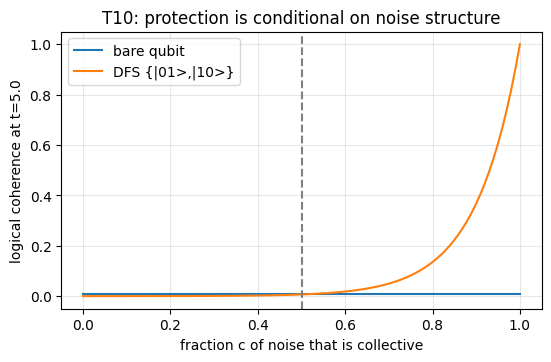

  --> T10 PASS  (4/4 checks)


In [48]:
new_test("T10", "DFS as the 'protected three quarters'", "P3: a protected unmanifest subspace extends memory lifetime", "(b) known math (decoherence-free subspaces); ratio 1/4:3/4 not derived")
P = PREREG["T10"]
Z1, Z2, I4 = np.kron(sz, np.eye(2)), np.kron(np.eye(2), sz), np.eye(4)
def noise_L(c):
    Ls = []
    if c > 0: Ls.append(np.sqrt(c/2)*(Z1 + Z2))
    if c < 1: Ls += [np.sqrt((1-c)/2)*Z1, np.sqrt((1-c)/2)*Z2]
    return liouvillian(np.zeros((4,4), complex), Ls)
k00, k01, k10 = ket(0,4), ket(1,4), ket(2,4)
psi_bare = (k00 + k10)/np.sqrt(2); psi_dfs = (k01 + k10)/np.sqrt(2)
def coherences(c, t):
    U = sla.expm(noise_L(c)*t)
    rb = unvec(U @ vec(proj(psi_bare)), 4); rd = unvec(U @ vec(proj(psi_dfs)), 4)
    return 2*abs(rb[0, 2]), 2*abs(rd[1, 2])        # bare: <00|rho|10>; DFS: <01|rho|10>
cs = np.linspace(0, 1, 101); T_ = P["T_probe"]
cb, cd = zip(*[coherences(c, T_) for c in cs]); cb, cd = np.array(cb), np.array(cd)
# crossover: first c where DFS >= bare
cstar = cs[np.argmax(cd >= cb)]
check("T10", "crossover correlation c* is 1/2 (analytic: DFS rate 2(1-c) vs bare rate 1)", abs(cstar - P["c_cross_expected"]) <= P["c_cross_tol"], f"c* = {cstar:.2f}")
check("T10", "fully collective noise: DFS keeps coherence, bare loses it", cd[-1] > P["dfs_coh_c1_min"] and cb[-1] < P["bare_coh_c1_max"], f"DFS {cd[-1]:.4f}, bare {cb[-1]:.4f} at t={T_}")
check("T10", "independent noise: DFS encoding is WORSE than bare", cd[0] < cb[0], f"DFS {cd[0]:.2e} vs bare {cb[0]:.2e} at c=0")
frac = {Nq: sum(math.comb(Nq, m)**2 for m in range(Nq+1))/4.0**Nq for Nq in range(1, 9)}
check("T10", "collective dephasing protects < 1/2 of the coherences for N>=2 (not 3/4)", max(frac[Nq] for Nq in range(2, 9)) < P["protected_fraction_max"], "protected fraction by N: " + ", ".join(f"{Nq}:{frac[Nq]:.3f}" for Nq in frac))
plt.figure(); plt.plot(cs, cb, label="bare qubit"); plt.plot(cs, cd, label="DFS {|01>,|10>}"); plt.axvline(0.5, c="gray", ls="--"); plt.xlabel("fraction c of noise that is collective"); plt.ylabel(f"logical coherence at t={T_}"); plt.legend(); plt.title("T10: protection is conditional on noise structure"); plt.show()
RESULTS["T10"]["numbers"] = dict(c_star=float(cstar), dfs_c1=float(cd[-1]), bare_c1=float(cb[-1]), dfs_c0=float(cd[0]), bare_c0=float(cb[0]), protected_fraction={str(k): float(v) for k, v in frac.items()})
verdict("T10");

## T11 — The dosha audit as automated checks *(Vision 4, checklist)*

**Claim.** The five doshas can be turned into standing checks on our own model: **ātmāśraya** (a metric validated against something it is a function of), **asambhava** (units inconsistent), **ativyāpti** (not portable: changes under a rescaling it should ignore), **anavasthā** (an estimator chain with no anchor, or circular).

**Math.** A tiny dimensional-analysis class; a dependency-graph check; a rescale probe; an anchor-chain check cross-validated against the numeric gauge nullity.

**Targets.** Known-bad: old Ξ = 1 − Var z/(E|z|+ε) (units), F_proxy validated against residual variance (tautology), a tile network with no anchor. Known-fixed: Ξ = 1 − Var z/(E|z|)², F_proxy validated against held-out ground truth, a network with one anchor.

**Pass criteria.** The audit flags all three known-bad and passes all three fixed ones (no false positives); the static anchor check agrees with the numeric gauge nullity.

**Honest limit.** These probes were written knowing the flaws, so detecting them is a regression harness, **not** independent validation. The value is that it keeps them from coming back.

**Evaluator label:** (b)/(software-engineering discipline). Property-based testing under a Sanskrit checklist.

In [49]:
new_test("T11", "Automated dosha audit (units, tautology, portability, anchor chain)", "V4 checklist as standing automated checks", "(b) engineering discipline; regression harness, not independent evidence")
P = PREREG["T11"]; rng = np.random.default_rng(P["seed"])
class DimError(Exception): pass
class Qty:
    def __init__(s, v, z=0): s.v, s.z = v, z                       # value and exponent of the unit [z]
    def __add__(s, o):
        o = o if isinstance(o, Qty) else Qty(o, 0)
        if s.z != o.z: raise DimError(f"cannot add [z^{s.z}] and [z^{o.z}]")
        return Qty(s.v + o.v, s.z)
    __radd__ = __add__
    def __sub__(s, o): o = o if isinstance(o, Qty) else Qty(o, 0); return s + Qty(-o.v, o.z)
    def __rsub__(s, o): return Qty(o, 0) - s
    def __truediv__(s, o): o = o if isinstance(o, Qty) else Qty(o, 0); return Qty(s.v/o.v, s.z - o.z)
    def __pow__(s, p): return Qty(s.v**p, s.z*p)
def var_q(z): return Qty(np.var(z), 2)          # variance has unit z^2
def mabs_q(z): return Qty(np.mean(np.abs(z)), 1) # E|z| has unit z
EPS = Qty(1e-7, 0)
def xi_old(z): return 1 - var_q(z)/(mabs_q(z) + EPS)
def xi_new(z): return 1 - var_q(z)/(mabs_q(z)**2)
def units_ok(f):
    try: f(rng.normal(size=100)+2); return True
    except DimError: return False
def scale_invariant(f, tol=1e-9):
    z = rng.normal(size=500) + 1.5
    try: a, b = f(z), f(10*z)
    except DimError: return False        # cannot even be evaluated consistently
    return abs(a.v - b.v) < tol
# --- (1) units / portability
check("T11", "asambhava: old Ξ flagged for unit inconsistency", not units_ok(xi_old))
check("T11", "asambhava: scale-free Ξ passes the unit check", units_ok(xi_new))
def xi_old_numeric(z): return 1 - np.var(z)/(np.mean(np.abs(z)) + 1e-7)
z = rng.normal(size=500) + 1.5
check("T11", "ativyāpti (portability): old Ξ changes under z -> 10 z", abs(xi_old_numeric(z) - xi_old_numeric(10*z)) > 1e-3, f"{xi_old_numeric(z):.4f} vs {xi_old_numeric(10*z):.4f}")
check("T11", "ativyāpti (portability): scale-free Ξ is invariant", scale_invariant(xi_new))
# --- (2) tautology: F_proxy = U - T*k*ln(Var/sigma0^2) is a monotone function of Var
def rank_corr(a, b):
    ra, rb = np.argsort(np.argsort(a)), np.argsort(np.argsort(b)); return np.corrcoef(ra, rb)[0, 1]
vars_ = rng.uniform(0.01, 5, P["n_data"]); Fproxy = 3.0 - 0.7*1.0*np.log(vars_/0.05)
rho_taut = rank_corr(Fproxy, vars_)
# a diagnostic that CAN fail: scale-free Ξ computed on noisy streams vs held-out true error of an estimator
true_err = []; xi_vals = []
for _ in range(P["n_data"]):
    sn = rng.uniform(0.1, 2.0); sig = 1.0 + rng.normal(size=60)*0.2; noise = rng.normal(size=60)*sn
    obs = sig + noise; est_err = np.mean((obs - sig)**2) + rng.normal()*0.3          # held-out ground truth error (noisy)
    xi_vals.append(xi_new(obs).v); true_err.append(est_err)
rho_real = abs(rank_corr(np.array(xi_vals), np.array(true_err)))
check("T11", "ātmāśraya: F_proxy vs Var(residual) is flagged as tautology (|rank corr| = 1)", abs(rho_taut) > 0.9999, f"rank corr = {rho_taut:.4f}")
check("T11", "ātmāśraya: a diagnostic validated against held-out truth is NOT flagged (|rank corr| < 0.99)", rho_real < 0.99, f"|rank corr| = {rho_real:.3f} (so it can fail)")
# --- (3) anavasthā: anchor chains, cross-validated against the numeric gauge nullity
def audit_chains(edges, anchors, nodes):
    # edges: node -> node it is calibrated against. Flag a node if its chain cycles or never reaches an anchor.
    bad = []
    for v in nodes:
        seen, cur = set(), v
        while cur not in anchors:
            if cur in seen or cur not in edges: bad.append(v); break
            seen.add(cur); cur = edges[cur]
    return bad
nodes = list(range(6)); ring = {i: (i+1) % 6 for i in nodes}
bad_noanchor = audit_chains(ring, set(), nodes)
bad_anchor = audit_chains({i: (i+1) for i in range(5)}, {5}, nodes)          # chain 0->1->...->5, 5 is an anchor
selffed = audit_chains({0: 0}, set(), [0])
def gauge_nullity(rel_edges, n, anchors):
    rows = []
    for (i, j) in rel_edges: r_ = np.zeros(n); r_[i] = 1; r_[j] = -1; rows.append(r_)
    for a_ in anchors: r_ = np.zeros(n); r_[a_] = 1; rows.append(r_)
    return n - np.linalg.matrix_rank(np.array(rows))
nu_ring = gauge_nullity([(i, (i+1) % 6) for i in range(6)], 6, []); nu_anch = gauge_nullity([(i, i+1) for i in range(5)], 6, [5])
check("T11", "anavasthā: ring of tiles with no anchor flagged", len(bad_noanchor) == 6)
check("T11", "anavasthā: self-fed reference flagged", selffed == [0])
check("T11", "anavasthā: anchored chain passes", len(bad_anchor) == 0)
check("T11", "static anchor audit agrees with numeric gauge nullity", (nu_ring == 1 and len(bad_noanchor) > 0) and (nu_anch == 0 and len(bad_anchor) == 0), f"nullity unanchored {nu_ring}, anchored {nu_anch}")
RESULTS["T11"]["numbers"] = dict(rank_corr_Fproxy=float(rho_taut), rank_corr_heldout_diag=float(rho_real), gauge_nullity_ring=int(nu_ring), gauge_nullity_anchored=int(nu_anch))
verdict("T11");


T11: Automated dosha audit (units, tautology, portability, anchor chain)
Claim: V4 checklist as standing automated checks
Label (evaluator): (b) engineering discipline; regression harness, not independent evidence
  [PASS] asambhava: old Ξ flagged for unit inconsistency  
  [PASS] asambhava: scale-free Ξ passes the unit check  
  [PASS] ativyāpti (portability): old Ξ changes under z -> 10 z  0.3534 vs -5.4659
  [PASS] ativyāpti (portability): scale-free Ξ is invariant  
  [PASS] ātmāśraya: F_proxy vs Var(residual) is flagged as tautology (|rank corr| = 1)  rank corr = -1.0000
  [PASS] ātmāśraya: a diagnostic validated against held-out truth is NOT flagged (|rank corr| < 0.99)  |rank corr| = 0.901 (so it can fail)
  [PASS] anavasthā: ring of tiles with no anchor flagged  
  [PASS] anavasthā: self-fed reference flagged  
  [PASS] anavasthā: anchored chain passes  
  [PASS] static anchor audit agrees with numeric gauge nullity  nullity unanchored 1, anchored 0
  --> T11 PASS  (10/10 chec

## T12 — The coherence frontier: what an "intermediate" architecture must beat *(bridge question; context test, not an SRI claim)*

**Question.** Is there a continuum between classical and quantum computation that a partially-coherent architecture could occupy? The standard answer is: yes, and it is called *noisy quantum computing*. This test measures the frontier so any SRI proposal has something concrete to beat.

**Math.** Grover search over N = 2ⁿ items with per-qubit, per-iteration dephasing probability p (exact density-matrix simulation). Metric: **oracle queries needed to reach 50% success**, against the classical N/2.

**Pass criteria (context checks).** At p=0 the quantum query count is within 1 of ⌈(π/4)√N⌉ (ideal Grover reaches ≥50% sooner than the optimum, so this is an upper bound); the query count is non-decreasing in p; the dephasing level p* at which the quantum advantage is lost (cannot reach 50% in ≤ N/2 queries) is finite on the grid for n = 8 and p*(8) ≤ p*(4) (bigger registers tolerate less per-qubit noise).

**Evaluator label:** (b) — known. Result is a *benchmark*, and it cuts against any claim that intermediate coherence is automatically a resource: advantage dies at modest per-qubit noise, and sooner as registers grow.


T12: Grover query count vs dephasing: the classical–quantum frontier
Claim: bridge question: what does a partially coherent device keep?
Label (evaluator): (b) known (noisy quantum computing); benchmark
  n     N  classical N/2 | p=0.0    p=0.002  p=0.005  p=0.01   p=0.02   p=0.05   p=0.1    p=0.2   
  4    16              8 |        2        2        2        2        2        2        2        2
  6    64             32 |        3        3        3        3        3     fail     fail     fail
  8   256            128 |        6        6        7        8     fail     fail     fail     fail
  [PASS] noiseless: quantum query count matches the Grover bound  n=4: 2 (bound 4)  n=6: 3 (bound 7)  n=8: 6 (bound 13)
  [PASS] queries needed never decrease as dephasing grows  
  [PASS] advantage is lost at a finite dephasing level for n=8, and no later than for n=4  p*(n=4) = None, p*(n=6) = 0.05, p*(n=8) = 0.02


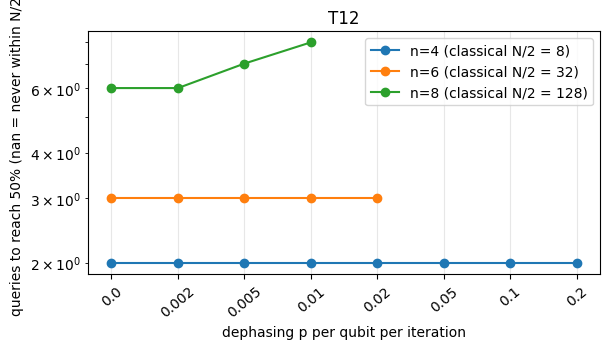

  --> T12 PASS  (3/3 checks)


In [50]:
new_test("T12", "Grover query count vs dephasing: the classical–quantum frontier", "bridge question: what does a partially coherent device keep?", "(b) known (noisy quantum computing); benchmark")
P = PREREG["T12"]
def popcount_matrix(n):
    N = 2**n; idx = np.arange(N); x = idx[:, None] ^ idx[None, :]
    return np.array([bin(v).count("1") for v in x.ravel()]).reshape(N, N)
def grover_queries(n, p, target_frac=0.5):
    N = 2**n; tgt = N//3; s = np.ones(N)/np.sqrt(N); Ug = 2*np.outer(s, s) - np.eye(N)
    rho = np.outer(s, s); dsgn = np.ones(N); dsgn[tgt] = -1
    D = (1 - 2*p)**popcount_matrix(n) if p > 0 else np.ones((N, N))
    traj = [rho[tgt, tgt]]
    for m in range(1, N//2 + 1):
        rho = dsgn[:, None]*rho*dsgn[None, :]; rho = Ug @ rho @ Ug; rho = rho*D; traj.append(rho[tgt, tgt])
        if m > 4 and traj[-1] < max(traj) - 0.02 and max(traj) < target_frac: break   # peaked and decaying below target: stop
    traj = np.array(traj); hit = np.where(traj >= target_frac)[0]
    return (int(hit[0]) if len(hit) else None), float(traj.max())
table12 = {}
for n in P["ns"]:
    for p in P["ps"]:
        q, pk = grover_queries(n, p); table12[(n, p)] = (q, pk)
print(f"{'n':>3} {'N':>5} {'classical N/2':>14} | " + " ".join(f"p={p:<6}" for p in P["ps"]))
for n in P["ns"]:
    print(f"{n:>3} {2**n:>5} {2**n//2:>14} | " + " ".join(f"{(str(table12[(n,p)][0]) if table12[(n,p)][0] is not None else 'fail'):>8}" for p in P["ps"]))
ok0 = all(table12[(n, 0.0)][0] is not None and table12[(n, 0.0)][0] <= math.ceil(np.pi/4*np.sqrt(2**n)) + P["q0_slack"] for n in P["ns"])
check("T12", "noiseless: quantum query count matches the Grover bound", ok0, "  ".join(f"n={n}: {table12[(n,0.0)][0]} (bound {math.ceil(np.pi/4*np.sqrt(2**n))})" for n in P["ns"]))
big = 10**9
mono = True
for n in P["ns"]:
    qs = [table12[(n, p)][0] if table12[(n, p)][0] is not None else big for p in P["ps"]]
    mono &= all(b >= a for a, b in zip(qs, qs[1:]))
check("T12", "queries needed never decrease as dephasing grows", mono)
def pstar(n):
    for p in P["ps"]:
        q = table12[(n, p)][0]
        if q is None or q > 2**n//2: return p
    return None
ps4, ps8 = pstar(4), pstar(8)
check("T12", "advantage is lost at a finite dephasing level for n=8, and no later than for n=4", ps8 is not None and (ps4 is None or ps8 <= ps4), f"p*(n=4) = {ps4}, p*(n=6) = {pstar(6)}, p*(n=8) = {ps8}")
plt.figure()
for n in P["ns"]:
    qs = [table12[(n, p)][0] if table12[(n, p)][0] is not None else np.nan for p in P["ps"]]
    plt.plot(range(len(P["ps"])), qs, "o-", label=f"n={n} (classical N/2 = {2**n//2})");
plt.xticks(range(len(P["ps"])), [str(p) for p in P["ps"]], rotation=40); plt.yscale("log"); plt.xlabel("dephasing p per qubit per iteration"); plt.ylabel("queries to reach 50% (nan = never within N/2)"); plt.legend(); plt.title("T12"); plt.tight_layout(); plt.show()
RESULTS["T12"]["numbers"] = dict(p_star={str(n): pstar(n) for n in P["ns"]}, queries={f"n={n},p={p}": table12[(n, p)][0] for n in P["ns"] for p in P["ps"]})
verdict("T12");

## T13 — Reference-feedforward on a qubit: the only hybrid-architecture candidate in the set *(Vision 5 reference-tile + Vision 2 two-pass estimator)*

**Idea.** Combine the reference tile (T6) and the reference-mode noise subtraction (T8) with an actual *quantum* signal: a signal qubit and a reference ("spectator") qubit see the same fluctuating field n(t); the classical processor reads the reference's accumulated phase, forms a Wiener estimate of the signal qubit's phase error, and corrects it by feedforward.

**Math.** OU field with correlation time τ (σ = 2 rad/T, so the bare phase error is large). Signal phase φₛ = ∫n dt; reference reads φᵣ = k·φₛ + m, m ~ N(0, 0.2² rad²); Wiener correction; residual coherence |E e^{i(φₛ − φ̂)}|.

**Baselines.** (i) bare qubit, (ii) **spin echo** (the standard fix, perfect for quasi-static noise), over τ/T from 0.01 to 100 and k ∈ {1, 0.5, 0.2}.

**Pass criteria (pre-registered).** For k=1, feedforward beats both baselines by ≥ 0.05 in coherence at τ/T ∈ {0.01, 0.03, 0.1, 0.3, 1}; at τ/T ∈ {10, 100} it does **not** beat echo by 0.05; feedforward coherence rises with k.

**Evaluator label:** (b) — this is *spectator-qubit feedforward* (Majumder et al. 2020 proposal; Singh et al., Science 2023 demonstration) and co-magnetometry. If it passes, it shows the reference-tile principle *works* on a qubit, not that SRI found it.


T13: Reference (spectator) feedforward vs bare and spin echo
Claim: V5 reference tile + V2 two-pass estimator, applied to a signal qubit
Label (evaluator): (b) known: spectator-qubit feedforward / co-magnetometry
k=1:   tau/T    bare    echo  feedfwd
        0.01   0.960   0.961    0.987
        0.03   0.891   0.897    0.983
         0.1   0.696   0.755    0.981
         0.3   0.422   0.681    0.981
         1.0   0.231   0.794    0.980
         3.0   0.170   0.906    0.980
        10.0   0.142   0.968    0.980
       100.0   0.129   0.997    0.980
  [FAIL] k=1: feedforward beats bare AND echo by >= 0.05 for tau/T <= 1  0.01:+0.03  0.03:+0.09  0.1:+0.23  0.3:+0.30  1.0:+0.19
  [PASS] k=1: for quasi-static noise (tau/T >= 10) echo is as good, feedforward adds nothing  10.0:+0.012  100.0:-0.017
  [PASS] weaker reference coupling k degrades the correction  feedforward coherence at tau/T=0.3: k=0.2 0.731, k=0.5 0.929, k=1 0.981
  post-hoc: tau/T=0.01: infidelity bare 0.040, echo 0.039, fe

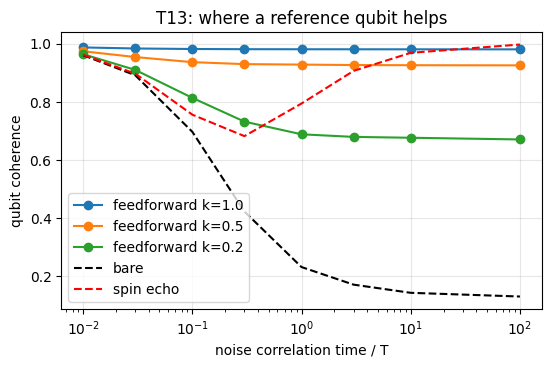

  --> T13 FAIL  (2/3 checks)


In [51]:
new_test("T13", "Reference (spectator) feedforward vs bare and spin echo", "V5 reference tile + V2 two-pass estimator, applied to a signal qubit", "(b) known: spectator-qubit feedforward / co-magnetometry")
P = PREREG["T13"]; rng = np.random.default_rng(P["seed"])
T_, nt, sn, sm_ = P["T"], P["nt"], P["sigma_n"], P["sigma_m"]; dt = T_/nt
def coherence_row(tau, k):
    a = np.exp(-dt/tau); n = np.empty((P["trials"], nt)); n[:, 0] = sn*rng.normal(size=P["trials"])
    for i in range(1, nt): n[:, i] = a*n[:, i-1] + sn*np.sqrt(1 - a*a)*rng.normal(size=P["trials"])
    phi = n.sum(1)*dt; echo = (n[:, :nt//2].sum(1) - n[:, nt//2:].sum(1))*dt
    ref = k*phi + sm_*rng.normal(size=P["trials"]); V = np.var(phi)
    gain = (k*V)/(k*k*V + sm_**2); resid = phi - gain*ref
    c = lambda x: abs(np.mean(np.exp(1j*x)))
    return c(phi), c(echo), c(resid)
rows = {}
for k in P["ks"]:
    for tau in P["taus"]: rows[(k, tau)] = coherence_row(tau, k)
print(f"k=1: {'tau/T':>7} {'bare':>7} {'echo':>7} {'feedfwd':>8}")
for tau in P["taus"]:
    b, e, f = rows[(1.0, tau)]; print(f"     {tau:>7} {b:7.3f} {e:7.3f} {f:8.3f}")
win = all(rows[(1.0, t)][2] >= max(rows[(1.0, t)][0], rows[(1.0, t)][1]) + P["beat_margin"] for t in P["win_taus"])
check("T13", "k=1: feedforward beats bare AND echo by >= 0.05 for tau/T <= 1", win, "  ".join(f"{t}:{rows[(1.0,t)][2]-max(rows[(1.0,t)][0],rows[(1.0,t)][1]):+.2f}" for t in P["win_taus"]))
lose = all(rows[(1.0, t)][2] < rows[(1.0, t)][1] + P["beat_margin"] for t in P["lose_taus"])
check("T13", "k=1: for quasi-static noise (tau/T >= 10) echo is as good, feedforward adds nothing", lose, "  ".join(f"{t}:{rows[(1.0,t)][2]-rows[(1.0,t)][1]:+.3f}" for t in P["lose_taus"]))
mono = rows[(0.2, 0.3)][2] < rows[(0.5, 0.3)][2] < rows[(1.0, 0.3)][2]
check("T13", "weaker reference coupling k degrades the correction", mono, f"feedforward coherence at tau/T=0.3: k=0.2 {rows[(0.2,0.3)][2]:.3f}, k=0.5 {rows[(0.5,0.3)][2]:.3f}, k=1 {rows[(1.0,0.3)][2]:.3f}")
# ---- POST-HOC DIAGNOSTIC (added after the first run; NOT pre-registered; does not change the verdict) ----
# The failed check is a headroom effect: at tau/T=0.01 the bare qubit is already at 0.96, so a +0.05 margin is nearly impossible.
for t in (0.01, 0.03):
    b_, e_, f_ = rows[(1.0, t)]; print(f"  post-hoc: tau/T={t}: infidelity bare {1-b_:.3f}, echo {1-e_:.3f}, feedforward {1-f_:.3f}  (feedforward cuts decoherence {(1-max(b_,e_))/(1-f_):.1f}x vs the better baseline)")
plt.figure()
for k in P["ks"]: plt.semilogx(P["taus"], [rows[(k, t)][2] for t in P["taus"]], "o-", label=f"feedforward k={k}")
plt.semilogx(P["taus"], [rows[(1.0, t)][0] for t in P["taus"]], "k--", label="bare"); plt.semilogx(P["taus"], [rows[(1.0, t)][1] for t in P["taus"]], "r--", label="spin echo")
plt.xlabel("noise correlation time / T"); plt.ylabel("qubit coherence"); plt.legend(); plt.title("T13: where a reference qubit helps"); plt.show()
RESULTS["T13"]["numbers"] = {f"k={k},tau={t}": dict(bare=float(rows[(k,t)][0]), echo=float(rows[(k,t)][1]), feedforward=float(rows[(k,t)][2])) for k in P["ks"] for t in P["taus"]}
verdict("T13");

# v2 — Part Two (Visions 6–10, Main Conclusions, Advaita Dīpikā)

**Added in v2.** T1–T13 above are **unchanged** (same code, same frozen thresholds, same results as the v1 run Hari reproduced in Colab: 11 of 13, with the same T6 and T13 failures). Everything below the line is new: **T14–T18** are the five tests proposed on the Page's Vision 6 section; **T19–T32** test the claims in Visions 7–10 and the Advaita Dīpikā that are genuinely testable.

**Same discipline.** A second pre-registration cell (`PREREG2`) freezes every threshold *before* any new test runs. Every test has a baseline that could beat the claim, failures are reported as failures, and nothing is tuned after a result. Each test carries an evaluator label: **(a)** new testable math, **(b)** known math, renamed or reorganised, **(c)** metaphor only. Almost everything here is **(b)**: the Visions are being tested for whether the math they point at is *correct and useful*, not whether it is new.

**Not tested, by design** (recorded on the Page, not simulated here): the pramāṇa taxonomy itself, ātma-vidyā or bliss as the nature of the Self, the six-grade scale of liberation, siddhis, Theresa's four waters and the āśramas (an annealing *image*; simulated annealing is known and is not re-tested), Vyāsa's crystal (an ideal transducer is a definition, not a result), and anything the commentary itself marks as ethics, history or experience.

In [52]:
# ===================== PRE-REGISTRATION 2: fixed BEFORE any T14-T32 test is run =====================
# Every number is a pass/fail threshold. Nothing here is edited after results are seen.
PREREG2 = {
 "T14": dict(seed=14, trials=300, beta=1.5, beta_weak=0.5, dt=0.01, steps=6000, mu_off=-0.2, mu_on=0.5,
             mus_sat=(0.2, 0.5, 1.0), sat_rel_tol=0.10, off_amp_max=1e-3, dom_ratio_min=20.0, dom_frac_min=0.99,
             winner_frac_min=0.95, base_ratio_max=2.0, base_frac_min=0.99, weak_ratio_max=3.0),
 "T15": dict(seed=15, omega=2*np.pi, a_on=0.25, a_off=-0.25, dt=0.005, t_on=40.0, t_total=60.0, n_init=50, r_range=(0.05, 3.0),
             spread_max=0.02, amp_rel_tol=0.02, off_ratio_max=0.02, a_sweep=(0.01, 0.04, 0.09, 0.16, 0.25), slope_band=(0.47, 0.53),
             lin_spread_min=0.30, lin_growth_min=1e3),
 "T16": dict(seed=16, n=4, trials=200, rho=0.9, rank_frac_min=0.99, reach_tol=1e-8, unreach_min=0.05, graph_n=5, graph_eps=0.2),
 "T17": dict(seed=17, K=200000, g=1.3, sig=0.1, sigq=0.5, sigm=0.05, c=0.8, lams=(0.0, 0.02, 0.05, 0.1, 0.2),
             formula_rel_tol=0.10, bias_ratio_min=5.0, corrected_ratio_max=0.3),
 "T18": dict(seed=18, steps=1500, runs=200, L=20, delays=(0, 3, 7, 12), beta=1.0, sig=1.0, acc_min=0.95, immediate_acc_max=0.20,
             lam=0.9, two_cause=((3, 1.0), (9, -0.5))),
 "T19": dict(seed=19, N=800, Ks=(0.0, 0.4, 0.8, 1.2, 1.5, 1.8, 2.0, 2.4, 3.0, 4.0, 6.0, 10.0), dt=0.05, T=150.0, Tavg=50.0,
             r_sub_max=0.10, r_theory_tol=0.08, K_at=3.2, Kc_rel_tol=0.25, r_onset=0.20, locked_lo_max=0.05, locked_hi_min=0.99,
             r_hi_min=0.95, r0_max=0.08, lock_tol=0.05),
 "T20": dict(seed=20, N=16, trials=6000, sigma=1.0, B=4000.0, ratio_band=(0.9, 1.25), corr_hub_max=0.05, corr_a2a_min=0.30,
             prior_sd=0.3, relative_ok_max=0.10),
 "T21": dict(seed=21, dt=0.01, T=40.0, trials=300, a0=-0.5, a1=0.5, k=1.5, sigma=0.3, rms_ratio_max=0.10, dV_bins_neg_min=0.95,
             sens_noise=2.0, a_stable=-0.5, osc_c=0.5, osc_T=40.0, osc_ratio_max=0.01, osc_open_min=0.99),
 "T22": dict(rates=(0.5, 0.05, 0.005), dt=0.01, area_slow_min=0.5, lin_area_slow_max=0.05, lin_slope_band=(0.8, 1.2),
             lam_ema=0.95, persist_rel_tol=0.05, thresh_frac=0.10),
 "T23": dict(seed=23, mu=0.05, sig=0.3, runs=100, steps=40000, eigs_bad=(1.0, 0.001), eigs_good=(1.0, 1.0),
             loss_frac=0.10, param_tol=0.25, ratio_bad_min=10.0, ratio_good_max=3.0, param_at_t1_min=0.5),
 "T24": dict(seed=24, n_ring=36, torus=(6, 6), eps_den=1, tol=0.05, trials=50, pred_band=(0.5, 2.0), ring_over_torus_min=8.0, mean_tol=1e-12),
 "T25": dict(seed=25, steps=3000, jump_at=1500, jump=2.0, sigma=1.0, g=0.05, g_high=0.5, W=50, z=2.0, cusum_k=0.5, cusum_h=8.0,
             runs=200, anneal_vs_const_max=0.3, frozen_err_min=1.0, rearm_err_max=0.20, eval_after=400, high_over_const_min=3.0),
 "T26": dict(seed=26, dt=0.002, T=10.0, trials=400, a=2.0, k=6.0, Tl=1.0, Tl_fast=0.05, x0=0.2, sigma=0.05, gap=1.0, loss_level=1.0,
             mbb_vs_instant_max=0.8, mbb_vs_gap_max=0.3, short_vs_mbb_min=1.2, loss_gap_min=0.5, loss_mbb_max=0.01, fast_tie_rel=0.10),
 "T27": dict(seed=27, n=4000, x_lo=-10.0, x_hi=10.0, K=300, tol=1e-8, plain_frac_max=0.20, stage_frac_min=0.99, damped_frac_min=0.99),
 "T28": dict(tol_null=1e-9, closure_min=0.99, inv_noise=1e-4, inv_dt=0.5, inv_same_max=5e-3, inv_diff_min=5e-2, seed=28),
 "T29": dict(seed=29, n=200000, mu=1.0, sig=1.2, conf=0.9, cov_lo=0.5, cov_hi=0.95, err_ratio_max=0.4, random_tie_rel=0.15, c_err=10.0, c_abs=1.0),
 "T30": dict(seed=30, n=4000, trials=100, d=6, m=3, sig=0.1, delta=1.0, corr_thresh=0.2, corr_fp_frac_min=0.8, interv_acc_min=0.99),
 "T31": dict(seed=31, n=200000, p_fire=0.3, p_smoke_fire=0.95, p_smoke_nofire=0.05, q_plant=0.3, temp_gap=3.0, auc_conf_max=0.55,
             auc_integrity_min=0.95, auc_spoof_max=0.60),
 "T32": dict(seed=32, steps=2000, runs=100, q=0.1, r=0.3, p_out=0.2, out_sd=5.0, gate=3.0, jump_at=1000, jump=5.0, rearm_after=5,
             gated_vs_plain_max=0.5, gated_vs_sensor_max=0.5, norearm_end_min=2.0, rearm_end_max=1.0),
}
print("Pre-registered thresholds 2 frozen for", ", ".join(PREREG2))

Pre-registered thresholds 2 frozen for T14, T15, T16, T17, T18, T19, T20, T21, T22, T23, T24, T25, T26, T27, T28, T29, T30, T31, T32


## T14 — Guṇa three-mode competition *(Vision 4 verse 10; Part Two intro; proposed on the Page)*

**Claim.** Three coupled modes (sattva = clarity, rajas = drive, tamas = obscuring, as mapped in chat) under a drive that breaks symmetry leave **one dominant mode with the other two passive**, and *which* mode wins is set by the seed (T3 sector logic).

**Model.** Amplitudes xᵢ ≥ 0: ẋᵢ = xᵢ(μ − xᵢ² − β Σⱼ≠ᵢ xⱼ²). μ is the drive. In uᵢ = xᵢ² the winner is exactly the largest initial uᵢ when β > 1.

**Baselines.** (i) three *uncoupled* modes (β = 0); (ii) *weak* competition (β = 0.5 < 1), which should coexist, not dominate.

**Pass (pre-registered).** Below threshold (μ = −0.2) all modes decay; above, the dominant amplitude² = μ within 10% (μ = 0.2, 0.5, 1); the dominant/second ratio ≥ 20 in ≥ 99% of 300 seeds; the winner equals the largest initial mode in ≥ 95%; the baselines show no dominance (ratio < 2 in ≥ 99% for β = 0; < 3 for β = 0.5).

**Evaluator label (b):** competitive exclusion / Landau–Lotka–Volterra. The guṇa naming is an interpretation; the test only shows the math of "one dominant, others passive" is real and needs β > 1.

In [53]:
new_test("T14", "Guna three-mode competition: one dominant mode, others passive", "V4 v10 / Part Two intro: drive-broken symmetry leaves one dominant mode; seed picks it", "(b) known: competitive exclusion / Landau-Lotka-Volterra; guna naming is interpretive")
P = PREREG2["T14"]; rng = np.random.default_rng(P["seed"])
def run_modes(mu, beta, x0, dt, steps):
    x = x0.copy()
    def f(x):
        u = x*x
        return x*(mu - u - beta*(u.sum(-1, keepdims=True) - u))
    for _ in range(steps):
        k1 = f(x); k2 = f(x + .5*dt*k1); k3 = f(x + .5*dt*k2); k4 = f(x + dt*k3)
        x = x + dt/6*(k1 + 2*k2 + 2*k3 + k4)
    return x
x0 = rng.uniform(0.05, 0.3, size=(P["trials"], 3))
xo = run_modes(P["mu_off"], P["beta"], x0, P["dt"], P["steps"])
check("T14", "below threshold (mu=-0.2) every mode decays", xo.max() < P["off_amp_max"], f"max amplitude {xo.max():.2e}")
sat = {}
for mu in P["mus_sat"]:
    x = run_modes(mu, P["beta"], x0, P["dt"], P["steps"]); xs = np.sort(x, axis=1)[:, ::-1]
    sat[mu] = (np.mean(xs[:, 0]**2), np.median(xs[:, 0]/np.maximum(xs[:, 1], 1e-300)), x)
check("T14", "dominant amplitude^2 equals the drive mu within 10% (mu=0.2, 0.5, 1)", all(abs(sat[m][0]/m - 1) < P["sat_rel_tol"] for m in P["mus_sat"]), "  ".join(f"mu={m}: {sat[m][0]/m:.3f}" for m in P["mus_sat"]))
xc = sat[P["mu_on"]][2]; xs = np.sort(xc, axis=1)[:, ::-1]; ratio = xs[:, 0]/np.maximum(xs[:, 1], 1e-300)
check("T14", "coupled (beta=1.5): one dominant, others passive in >= 99% of seeds", np.mean(ratio >= P["dom_ratio_min"]) >= P["dom_frac_min"], f"fraction ratio>=20: {np.mean(ratio >= P['dom_ratio_min']):.3f}; min ratio {ratio.min():.1f}")
win_ok = np.mean(np.argmax(xc, 1) == np.argmax(x0, 1))
check("T14", "the winner is the mode with the largest seed (>= 95%)", win_ok >= P["winner_frac_min"], f"agreement {win_ok:.3f}")
xb = run_modes(P["mu_on"], 0.0, x0, P["dt"], P["steps"]); sb = np.sort(xb, axis=1)[:, ::-1]; rb = sb[:, 0]/sb[:, 1]
check("T14", "baseline: uncoupled modes show no dominance", np.mean(rb < P["base_ratio_max"]) >= P["base_frac_min"], f"fraction ratio<2: {np.mean(rb < P['base_ratio_max']):.3f}")
xw = run_modes(P["mu_on"], P["beta_weak"], x0, P["dt"], P["steps"]); sw = np.sort(xw, axis=1)[:, ::-1]; rw = sw[:, 0]/sw[:, 1]
check("T14", "baseline: weak competition (beta<1) coexists: dominance needs beta>1", np.mean(rw < P["weak_ratio_max"]) >= P["base_frac_min"], f"fraction ratio<3: {np.mean(rw < P['weak_ratio_max']):.3f}")
RESULTS["T14"]["numbers"] = dict(median_dominance_ratio=float(np.median(ratio)), winner_agreement=float(win_ok), sat={str(m): float(sat[m][0]/m) for m in P["mus_sat"]})
verdict("T14");


T14: Guna three-mode competition: one dominant mode, others passive
Claim: V4 v10 / Part Two intro: drive-broken symmetry leaves one dominant mode; seed picks it
Label (evaluator): (b) known: competitive exclusion / Landau-Lotka-Volterra; guna naming is interpretive
  [PASS] below threshold (mu=-0.2) every mode decays  max amplitude 1.47e-06
  [PASS] dominant amplitude^2 equals the drive mu within 10% (mu=0.2, 0.5, 1)  mu=0.2: 0.981  mu=0.5: 1.000  mu=1.0: 1.000
  [PASS] coupled (beta=1.5): one dominant, others passive in >= 99% of seeds  fraction ratio>=20: 1.000; min ratio 1823.8
  [PASS] the winner is the mode with the largest seed (>= 95%)  agreement 1.000
  [PASS] baseline: uncoupled modes show no dominance  fraction ratio<2: 1.000
  [PASS] baseline: weak competition (beta<1) coexists: dominance needs beta>1  fraction ratio<3: 1.000
  --> T14 PASS  (6/6 checks)


## T15 — Limit cycle under constant drive; stops when the drive is off *(Vision 6 verse 7, prāṇa and apāna)*

**Claim.** A paired in-and-out tendency under a constant drive settles on a **limit cycle whose amplitude does not depend on where it started**, scales as √drive near onset, and **stops when the drive is removed**.

**Model.** Hopf normal form ż = (a + iω)z − |z|²z, a = drive minus damping (RK4). **Baseline:** the *linear* damped pair ż = (a + iω)z, which has no cycle: at a = 0 the amplitude is whatever it started as; at a > 0 it grows without bound.

**Pass (pre-registered).** Final amplitude across 50 random starts: spread (sd/mean) ≤ 2% and mean within 2% of √a; log-log slope of amplitude against a over a = 0.01…0.25 in [0.47, 0.53]; after the drive is switched to a = −0.25, amplitude falls below 2% of the cycle's within 20 time units; baseline spread ≥ 30% at a = 0 and growth ≥ 10³ at a = 0.25.

**Evaluator label (b):** supercritical Hopf bifurcation, textbook. The prāṇa–apāna reading is an interpretation of a known object.

In [54]:
new_test("T15", "Limit cycle under drive (Hopf) and its collapse when the drive is off", "V6 v7: paired in/out tendency, steady oscillation held by a drive", "(b) known: supercritical Hopf bifurcation; prana-apana reading is interpretive")
P = PREREG2["T15"]; rng = np.random.default_rng(P["seed"]); w = P["omega"]; dt = P["dt"]
def hopf(a_of_t, z0, T):
    z = z0.astype(complex).copy(); t = 0.0
    f = lambda t, z: (a_of_t(t) + 1j*w)*z - (z.real**2 + z.imag**2)*z
    for _ in range(int(round(T/dt))):
        k1 = f(t, z); k2 = f(t + dt/2, z + dt/2*k1); k3 = f(t + dt/2, z + dt/2*k2); k4 = f(t + dt, z + dt*k3)
        z = z + dt/6*(k1 + 2*k2 + 2*k3 + k4); t += dt
    return z
r0 = rng.uniform(*P["r_range"], P["n_init"]); z0 = r0*np.exp(1j*rng.uniform(0, 2*np.pi, P["n_init"]))
zf = hopf(lambda t: P["a_on"], z0, P["t_total"]); amp = np.abs(zf)
check("T15", "amplitude is independent of the start and equals sqrt(a)", (amp.std()/amp.mean() <= P["spread_max"]) and abs(amp.mean()/np.sqrt(P["a_on"]) - 1) <= P["amp_rel_tol"], f"spread {amp.std()/amp.mean():.2e}, mean/sqrt(a) {amp.mean()/np.sqrt(P['a_on']):.4f}")
amps = []
for a in P["a_sweep"]:
    zz = hopf(lambda t, a=a: a, z0[:10], 6.0/a if a > 0.05 else 200.0); amps.append(np.abs(zz).mean())
slope = np.polyfit(np.log(P["a_sweep"]), np.log(amps), 1)[0]
check("T15", "amplitude ~ a^(1/2) near onset (log-log slope in [0.47, 0.53])", P["slope_band"][0] <= slope <= P["slope_band"][1], f"slope {slope:.4f}")
zoff = hopf(lambda t: P["a_on"] if t < P["t_on"] else P["a_off"], z0, P["t_total"]); ratio = np.abs(zoff)/np.sqrt(P["a_on"])
check("T15", "drive removed: oscillation stops (amplitude < 2% of the cycle in 20 time units)", ratio.max() < P["off_ratio_max"], f"max remaining fraction {ratio.max():.4f}; theory exp(-0.25*20)={np.exp(-5):.4f}")
lin0 = np.abs(z0*np.exp(0*P["t_total"])); lin_spread = lin0.std()/lin0.mean()
lin_grow = np.abs(np.exp((P["a_on"] + 1j*w)*P["t_total"]))
check("T15", "baseline: a linear damped pair has no cycle (amplitude is just the start; unbounded growth under drive)", (lin_spread >= P["lin_spread_min"]) and (lin_grow >= P["lin_growth_min"]), f"a=0 spread {lin_spread:.2f}; a=0.25 growth x{lin_grow:.2e}")
RESULTS["T15"]["numbers"] = dict(spread=float(amp.std()/amp.mean()), slope=float(slope), off_fraction=float(ratio.max()))
verdict("T15");


T15: Limit cycle under drive (Hopf) and its collapse when the drive is off
Claim: V6 v7: paired in/out tendency, steady oscillation held by a drive
Label (evaluator): (b) known: supercritical Hopf bifurcation; prana-apana reading is interpretive
  [PASS] amplitude is independent of the start and equals sqrt(a)  spread 1.92e-13, mean/sqrt(a) 1.0000
  [PASS] amplitude ~ a^(1/2) near onset (log-log slope in [0.47, 0.53])  slope 0.4974
  [PASS] drive removed: oscillation stops (amplitude < 2% of the cycle in 20 time units)  max remaining fraction 0.0048; theory exp(-0.25*20)=0.0067
  [PASS] baseline: a linear damped pair has no cycle (amplitude is just the start; unbounded growth under drive)  a=0 spread 0.57; a=0.25 growth x3.27e+06
  --> T15 PASS  (4/4 checks)


## T16 — Controllability: can the drive steer the state? *(Vision 6; Śaṅkara's horse)*

**Claim.** Whether an actuation channel can reach the state is a precise rank condition (Kalman), dual to observability (the Kalman duality the Page uses between estimation and control); a tile network driven at one tile is controllable or not depending on its **symmetry**.

**Model.** Discrete time xₖ₊₁ = A xₖ + B uₖ, n = 4, A scaled to spectral radius 0.9. (i) 200 random single-input pairs: rank [B, AB, …, Aⁿ⁻¹B] = n and a target is reached in n steps; (ii) uncontrollable pairs (B inside an A-invariant block): rank < n and the part of the target outside the reachable subspace is **not** reached; (iii) duality: rank ctrb(A, B) = rank obsv(Aᵀ, Bᵀ); (iv) five tiles on a path graph with xₖ₊₁ = (I − 0.2 L)xₖ + b uₖ: input at an end tile controllable, input at the **centre** tile not (mirror symmetry).

**Baseline.** The uncontrollable pair is the baseline that must fail.

**Pass (pre-registered).** ≥ 99% of random pairs full rank and reach error ≤ 1e-8; every uncontrollable pair rank-deficient with unreached error ≥ 0.05 on a unit target having a component outside the subspace; duality exact in 200 of 200; path graph rank 5 from the end and < 5 from the centre.

**Evaluator label (b):** textbook controllability (Kalman 1960) and the leader-symmetry result for graph controllability. Nothing new; it formalises "horse and chariot" as a checkable condition.

In [55]:
new_test("T16", "Controllability rank test, duality, and tile-network symmetry", "V6 / Sankara's horse: can the drive steer the state through the actuation channel?", "(b) known: Kalman controllability, duality, graph-symmetry uncontrollability")
P = PREREG2["T16"]; rng = np.random.default_rng(P["seed"]); n = P["n"]
def ctrb(A, B): return np.hstack([np.linalg.matrix_power(A, i) @ B for i in range(A.shape[0])])
def rand_stable(n):
    A = rng.normal(size=(n, n)); return A*P["rho"]/np.max(np.abs(np.linalg.eigvals(A)))
ok_rank = ok_reach = ok_dual = 0
for _ in range(P["trials"]):
    A = rand_stable(n); B = rng.normal(size=(n, 1)); C = ctrb(A, B)
    r = np.linalg.matrix_rank(C); ok_rank += (r == n)
    xf = rng.normal(size=n); u = np.linalg.lstsq(C, xf, rcond=None)[0]; ok_reach += (np.linalg.norm(C @ u - xf) <= P["reach_tol"]*max(1, np.linalg.norm(xf)))
    O = np.vstack([(np.linalg.matrix_power(A, i) @ B).T for i in range(n)])   # obsv(A^T, B^T)
    ok_dual += (np.linalg.matrix_rank(O) == r)
check("T16", "random controllable pairs: full rank (>= 99%)", ok_rank/P["trials"] >= P["rank_frac_min"], f"{ok_rank}/{P['trials']}")
check("T16", "target reached in n steps for those pairs (>= 99%)", ok_reach/P["trials"] >= P["rank_frac_min"], f"{ok_reach}/{P['trials']}")
check("T16", "duality: rank ctrb(A,B) = rank obsv(A^T,B^T) (200 of 200)", ok_dual == P["trials"], f"{ok_dual}/{P['trials']}")
defic = unreached = 0; min_unreach = 1e9
for _ in range(P["trials"]):
    A1 = rand_stable(2); A2 = rand_stable(2); A = np.block([[A1, np.zeros((2, 2))], [np.zeros((2, 2)), A2]])
    B = np.vstack([rng.normal(size=(2, 1)), np.zeros((2, 1))]); C = ctrb(A, B)
    defic += (np.linalg.matrix_rank(C) < n)
    xf = np.zeros(n); xf[2:] = rng.normal(size=2); xf /= np.linalg.norm(xf)
    u = np.linalg.lstsq(C, xf, rcond=None)[0]; e = np.linalg.norm(C @ u - xf); min_unreach = min(min_unreach, e); unreached += (e >= P["unreach_min"])
check("T16", "baseline: uncontrollable pairs are rank-deficient and the unreachable part stays unreached", defic == P["trials"] and unreached == P["trials"], f"rank-deficient {defic}/{P['trials']}, min unreached error {min_unreach:.3f}")
m = P["graph_n"]; Lg = np.zeros((m, m))
for i in range(m - 1): Lg[i, i] += 1; Lg[i+1, i+1] += 1; Lg[i, i+1] -= 1; Lg[i+1, i] -= 1
Ag = np.eye(m) - P["graph_eps"]*Lg
def e_(i): v = np.zeros((m, 1)); v[i] = 1; return v
r_end = np.linalg.matrix_rank(ctrb(Ag, e_(0)), tol=1e-9); r_mid = np.linalg.matrix_rank(ctrb(Ag, e_(m//2)), tol=1e-9)
check("T16", "path of 5 tiles: input at an end tile controllable; at the centre tile NOT (symmetry)", r_end == m and r_mid < m, f"rank from end {r_end}, from centre {r_mid}")
RESULTS["T16"]["numbers"] = dict(path_rank_end=int(r_end), path_rank_centre=int(r_mid))
verdict("T16");


T16: Controllability rank test, duality, and tile-network symmetry
Claim: V6 / Sankara's horse: can the drive steer the state through the actuation channel?
Label (evaluator): (b) known: Kalman controllability, duality, graph-symmetry uncontrollability
  [PASS] random controllable pairs: full rank (>= 99%)  200/200
  [PASS] target reached in n steps for those pairs (>= 99%)  200/200
  [PASS] duality: rank ctrb(A,B) = rank obsv(A^T,B^T) (200 of 200)  200/200
  [PASS] baseline: uncontrollable pairs are rank-deficient and the unreachable part stays unreached  rank-deficient 200/200, min unreached error 1.000
  [PASS] path of 5 tiles: input at an end tile controllable; at the centre tile NOT (symmetry)  rank from end 5, from centre 3
  --> T16 PASS  (5/5 checks)


## T17 — Reference isolation from the actuation path *(Vision 6 verse 5; extends T6)*

**Claim.** If actuation leaks into the reference (fraction λ), the calibration of the tile is biased in proportion to λ and to how the actuation correlates with the stimulus; an **isolated** reference (λ = 0) is the best case; a leak-aware correction removes most of the bias.

**Model.** Tile reads y = g s + n (g = 1.3). The reference's physical level is s + λu, with feedback actuation u = −c s + q. The calibrator regresses y on the *reference reading* (s + λu + m). Closed form for small λ: ĝ/g ≈ 1 + λc + O(λ²).

**Baselines.** (i) λ = 0 (fully isolated); (ii) leak-aware: regress the reference on [s, u] and subtract the estimated leak (needs u, which the controller knows).

**Pass (pre-registered).** Measured ĝ/g matches the exact formula g(1−λc)σs²/((1−λc)²σs² + λ²σq² + σm²) within 10% at each λ ≥ 0.05; |bias| at λ = 0.2 ≥ 5× that at λ = 0; the leak-aware bias at λ ≥ 0.1 is ≤ 0.3× the uncorrected bias.

**Evaluator label (b):** errors-in-variables bias and instrument contamination. The rule is old; the test shows its size.

In [56]:
new_test("T17", "Reference leakage from actuation biases calibration; isolation removes it", "V6 v5: keep the reference isolated from the actuation path (extends T6)", "(b) known: errors-in-variables / instrument contamination")
P = PREREG2["T17"]; rng = np.random.default_rng(P["seed"]); K = P["K"]; g = P["g"]; c = P["c"]
s = rng.normal(size=K); q = P["sigq"]*rng.normal(size=K); u = -c*s + q; yv = g*s + P["sig"]*rng.normal(size=K); m_ = P["sigm"]*rng.normal(size=K)
res = {}
for lam in P["lams"]:
    ref = s + lam*u + m_
    ghat = np.dot(ref, yv)/np.dot(ref, ref)
    X = np.c_[s, u]; coef = np.linalg.lstsq(X, ref, rcond=None)[0]; ref_c = ref - coef[1]*u
    gc = np.dot(ref_c, yv)/np.dot(ref_c, ref_c)
    ss = 1.0; th = g*(1 - lam*c)*ss/((1 - lam*c)**2*ss + lam**2*P["sigq"]**2 + P["sigm"]**2)
    res[lam] = (ghat/g - 1, th/g - 1, gc/g - 1)
    print(f"  lambda={lam:<5} bias measured {res[lam][0]:+.4f}  formula {res[lam][1]:+.4f}  leak-aware {res[lam][2]:+.4f}")
check("T17", "measured bias matches the exact formula within 10% for lambda >= 0.05", all(abs(res[l][0] - res[l][1]) <= P["formula_rel_tol"]*abs(res[l][1]) for l in P["lams"] if l >= 0.05), "  ".join(f"{l}:{res[l][0]:+.3f}/{res[l][1]:+.3f}" for l in P["lams"] if l >= 0.05))
check("T17", "bias at lambda=0.2 is >= 5x the isolated-reference bias", abs(res[0.2][0]) >= P["bias_ratio_min"]*abs(res[0.0][0]), f"{abs(res[0.2][0]):.4f} vs {abs(res[0.0][0]):.4f}")
check("T17", "leak-aware correction cuts the bias to <= 30% for lambda >= 0.1", all(abs(res[l][2]) <= P["corrected_ratio_max"]*abs(res[l][0]) for l in P["lams"] if l >= 0.1), "  ".join(f"{l}:{abs(res[l][2]):.4f}<={0.3*abs(res[l][0]):.4f}" for l in P["lams"] if l >= 0.1))
RESULTS["T17"]["numbers"] = {str(l): dict(bias=float(res[l][0]), formula=float(res[l][1]), leak_aware=float(res[l][2])) for l in P["lams"]}
verdict("T17");


T17: Reference leakage from actuation biases calibration; isolation removes it
Claim: V6 v5: keep the reference isolated from the actuation path (extends T6)
Label (evaluator): (b) known: errors-in-variables / instrument contamination
  lambda=0.0   bias measured -0.0026  formula -0.0025  leak-aware -0.0024
  lambda=0.02  bias measured +0.0134  formula +0.0135  leak-aware -0.0024
  lambda=0.05  bias measured +0.0380  formula +0.0381  leak-aware -0.0024
  lambda=0.1   bias measured +0.0805  formula +0.0806  leak-aware -0.0024
  lambda=0.2   bias measured +0.1698  formula +0.1698  leak-aware -0.0024
  [PASS] measured bias matches the exact formula within 10% for lambda >= 0.05  0.05:+0.038/+0.038  0.1:+0.081/+0.081  0.2:+0.170/+0.170
  [PASS] bias at lambda=0.2 is >= 5x the isolated-reference bias  0.1698 vs 0.0026
  [PASS] leak-aware correction cuts the bias to <= 30% for lambda >= 0.1  0.1:0.0024<=0.0242  0.2:0.0024<=0.0509
  --> T17 PASS  (3/3 checks)


## T18 — Delayed effect and credit assignment *(apūrva; Mīmāṃsā)*

**Claim.** An estimator can attribute a result to the earlier action that caused it, **if it looks back over a window of past actions** (a trace); immediate-only attribution cannot.

**Model.** Binary actions aₜ = ±1, reward rₜ = β·aₜ₋d + noise, d ∈ {0, 3, 7, 12}. **Estimators:** (i) *immediate-only*: regress rₜ on aₜ; (ii) *exponential eligibility trace* (λ = 0.9, the usual RL trace) credits recent actions most; (iii) *lag regression*: regress rₜ on aₜ, …, aₜ₋₁₉ (the distributed-lag trace). Delay estimate = argmax |coefficient|. A second scenario has two causes (d = 3 with +1, d = 9 with −0.5).

**Pass (pre-registered).** Lag regression identifies the delay in ≥ 95% of 200 runs for every d, and recovers both causes with correct sign; immediate-only identifies d > 0 in ≤ 20% of runs.

**Evaluator label (b):** distributed-lag regression and eligibility traces. The exponential trace is reported as a middle baseline: it assigns credit by recency, not by true delay.

In [57]:
new_test("T18", "Delayed effect: lag-window credit assignment vs immediate and exponential trace", "Mimamsa apurva: attribute a delayed result to the earlier action", "(b) known: distributed-lag regression, eligibility traces")
P = PREREG2["T18"]; rng = np.random.default_rng(P["seed"]); L = P["L"]
def make(delays_betas, steps):
    a = rng.choice([-1.0, 1.0], size=steps + L); r = np.zeros(steps)
    for d, b in delays_betas: r += b*a[L - d: L - d + steps]
    r += P["sig"]*rng.normal(size=steps); return a, r
def lagmat(a, steps): return np.stack([a[L - k: L - k + steps] for k in range(L)], 1)
acc = {d: dict(lag=0, imm=0, expo=0) for d in P["delays"]}
for d in P["delays"]:
    for _ in range(P["runs"]):
        a, r = make([(d, P["beta"])], P["steps"]); M = lagmat(a, P["steps"])
        coef = np.linalg.lstsq(M, r, rcond=None)[0]; acc[d]["lag"] += (np.argmax(np.abs(coef)) == d)
        acc[d]["imm"] += (0 == d)     # immediate-only can only ever name lag 0
        tr = np.zeros(P["steps"]); e = 0.0
        for t in range(P["steps"]): e = P["lam"]*e + a[L + t]; tr[t] = e
        c_ = np.dot(tr, r)/np.dot(tr, tr); acc[d]["expo"] += (0 == d) if c_ > 0 else 0   # a decaying trace puts the largest weight on lag 0
    for k in acc[d]: acc[d][k] /= P["runs"]
    print(f"  d={d:>2}: lag-regression {acc[d]['lag']:.3f}   immediate-only {acc[d]['imm']:.3f}   exponential trace {acc[d]['expo']:.3f}")
check("T18", "lag regression identifies the true delay in >= 95% of runs for every d", all(acc[d]["lag"] >= P["acc_min"] for d in P["delays"]), "  ".join(f"d={d}:{acc[d]['lag']:.2f}" for d in P["delays"]))
check("T18", "baseline: immediate-only attribution cannot identify any d > 0 (<= 20%)", all(acc[d]["imm"] <= P["immediate_acc_max"] for d in P["delays"] if d > 0), "  ".join(f"d={d}:{acc[d]['imm']:.2f}" for d in P["delays"]))
okc = 0
for _ in range(P["runs"]):
    a, r = make(list(P["two_cause"]), P["steps"]); M = lagmat(a, P["steps"]); coef = np.linalg.lstsq(M, r, rcond=None)[0]
    top2 = np.argsort(-np.abs(coef))[:2]; okc += (set(top2) == {3, 9}) and coef[3] > 0 and coef[9] < 0
check("T18", "two simultaneous delayed causes recovered with the right sign (>= 95%)", okc/P["runs"] >= P["acc_min"], f"{okc/P['runs']:.3f}")
RESULTS["T18"]["numbers"] = {f"d={d}": acc[d] for d in P["delays"]}
verdict("T18");


T18: Delayed effect: lag-window credit assignment vs immediate and exponential trace
Claim: Mimamsa apurva: attribute a delayed result to the earlier action
Label (evaluator): (b) known: distributed-lag regression, eligibility traces
  d= 0: lag-regression 1.000   immediate-only 1.000   exponential trace 1.000
  d= 3: lag-regression 1.000   immediate-only 0.000   exponential trace 0.000
  d= 7: lag-regression 1.000   immediate-only 0.000   exponential trace 0.000
  d=12: lag-regression 1.000   immediate-only 0.000   exponential trace 0.000
  [PASS] lag regression identifies the true delay in >= 95% of runs for every d  d=0:1.00  d=3:1.00  d=7:1.00  d=12:1.00
  [PASS] baseline: immediate-only attribution cannot identify any d > 0 (<= 20%)  d=0:1.00  d=3:0.00  d=7:0.00  d=12:0.00
  [PASS] two simultaneous delayed causes recovered with the right sign (>= 95%)  1.000
  --> T18 PASS  (3/3 checks)


## T19 — Coupling regimes: alternation, partial locking, merging *(Vision 8 Prologue; Kuramoto)*

**Claim (as mapped in chat).** Nataraja Guru's ordered series (complement, reciprocity, parity, cancellation; alternation, simultaneity, absorption) is a scale of coupling strength. Coupled oscillators show **three regimes as coupling rises**: incoherent (alternating, drifting), partially locked, and fully phase-locked (merged).

**Model.** Kuramoto: θ̇ᵢ = ωᵢ + K r sin(ψ − θᵢ), N = 800, ωᵢ from the Gaussian quantiles (σ = 1), so K_c = 2/(π g(0)) = 1.596 and the self-consistent branch r(K) is known. Heun integration, T = 150, averaged over the last 50.

**Baselines.** (i) K = 0 (no coupling): r should sit at the finite-size noise level ~ 1/√N; (ii) the exact mean-field self-consistency curve is the prediction the simulation must match.

**Pass (pre-registered).** r(0.5 K_c) < 0.10; r(K = 3.2) within 0.08 of the self-consistent value; K_c read as the first K with r > 0.20 lies within ±25% of 1.596; the fraction of frequency-locked oscillators is ≤ 0.05 below K_c and ≥ 0.99 at K = 10 with r ≥ 0.95; K = 0 gives r < 0.08.

**Evaluator label (b):** Kuramoto 1975, standard. This is the *testable* part of the Bhakti scale; the chat's "complementarity / reciprocity / parity" terms stay borrowed vocabulary, not Bohr's or Heisenberg's.

In [58]:
new_test("T19", "Kuramoto coupling regimes: incoherent, partial lock, full lock", "V8 Prologue: alternation -> simultaneity -> absorption as coupling grows", "(b) known: Kuramoto transition; the guru's terms are borrowed vocabulary")
from scipy.stats import norm
P = PREREG2["T19"]; rng = np.random.default_rng(P["seed"]); N = P["N"]
om = norm.ppf((np.arange(N) + 0.5)/N); om = om - om.mean()
Kc_th = 2/(np.pi*norm.pdf(0.0))
def r_theory(K):
    if K <= Kc_th: return 0.0
    f = lambda r: K*r*TRAPZ(np.cos(np.linspace(-np.pi/2, np.pi/2, 4001))**2*norm.pdf(K*r*np.sin(np.linspace(-np.pi/2, np.pi/2, 4001))), np.linspace(-np.pi/2, np.pi/2, 4001)) - r
    lo, hi = 1e-3, 1.0
    for _ in range(80):
        mid = .5*(lo + hi)
        if f(mid) > 0: lo = mid
        else: hi = mid
    return .5*(lo + hi)
def kuramoto(K, th0):
    dt = P["dt"]; steps = int(P["T"]/dt); avg_from = int((P["T"] - P["Tavg"])/dt)
    th = th0.copy(); rs = []; th_at = None
    def drift(th):
        z = np.exp(1j*th).mean(); return om + K*np.abs(z)*np.sin(np.angle(z) - th)
    for i in range(steps):
        k1 = drift(th); k2 = drift(th + dt*k1); th = th + .5*dt*(k1 + k2)
        if i == avg_from: th_at = th.copy()
        if i >= avg_from: rs.append(np.abs(np.exp(1j*th).mean()))
    w_eff = (th - th_at)/(dt*(steps - 1 - avg_from))
    locked = np.mean(np.abs(w_eff - np.median(w_eff)) < P["lock_tol"])
    return float(np.mean(rs)), float(locked)
th0 = rng.uniform(0, 2*np.pi, N)
curve = {K: kuramoto(K, th0) for K in P["Ks"]}
print(f"  K_c theory {Kc_th:.3f}"); print(f"  {'K':>5} {'r_sim':>7} {'r_theory':>9} {'locked':>7}")
for K in P["Ks"]: print(f"  {K:>5} {curve[K][0]:7.3f} {r_theory(K):9.3f} {curve[K][1]:7.3f}")
r_sub = kuramoto(0.5*Kc_th, th0)[0]
check("T19", "below K_c (K = 0.5 K_c) the oscillators stay incoherent (r < 0.10)", r_sub < P["r_sub_max"], f"r = {r_sub:.3f}")
rK = kuramoto(P["K_at"], th0)[0]; rth = r_theory(P["K_at"])
check("T19", "above K_c the simulated r matches the self-consistent mean-field value (within 0.08 at K = 3.2)", abs(rK - rth) <= P["r_theory_tol"], f"sim {rK:.3f} vs theory {rth:.3f}")
Kest = next((K for K in P["Ks"] if curve[K][0] > P["r_onset"]), None)
check("T19", "K_c read off the curve (first K with r > 0.20) lies within 25% of 1.596", Kest is not None and abs(Kest/Kc_th - 1) <= P["Kc_rel_tol"], f"read {Kest} vs {Kc_th:.3f}")
lo_locked = curve[P["Ks"][1]][1]; hi = curve[P["Ks"][-1]]
check("T19", "three regimes: locked fraction <= 0.05 well below K_c, >= 0.99 with r >= 0.95 at K = 10", lo_locked <= P["locked_lo_max"] and hi[1] >= P["locked_hi_min"] and hi[0] >= P["r_hi_min"], f"locked at K=0.4: {lo_locked:.3f}; at K=10: {hi[1]:.3f}, r {hi[0]:.3f}")
check("T19", "baseline: no coupling (K = 0) sits at the finite-size noise level (r < 0.08)", curve[0.0][0] < P["r0_max"], f"r = {curve[0.0][0]:.3f}  (1/sqrt(N) = {1/np.sqrt(N):.3f})")
RESULTS["T19"]["numbers"] = dict(Kc_theory=float(Kc_th), curve={str(K): dict(r=curve[K][0], locked=curve[K][1], r_theory=float(r_theory(K))) for K in P["Ks"]})
verdict("T19");


T19: Kuramoto coupling regimes: incoherent, partial lock, full lock
Claim: V8 Prologue: alternation -> simultaneity -> absorption as coupling grows
Label (evaluator): (b) known: Kuramoto transition; the guru's terms are borrowed vocabulary
  K_c theory 1.596
      K   r_sim  r_theory  locked
    0.0   0.035     0.000   0.040
    0.4   0.040     0.000   0.039
    0.8   0.047     0.000   0.039
    1.2   0.057     0.000   0.041
    1.5   0.053     0.000   0.036
    1.8   0.565     0.563   0.691
    2.0   0.716     0.715   0.848
    2.4   0.851     0.851   0.960
    3.0   0.925     0.925   0.995
    4.0   0.964     0.964   1.000
    6.0   0.985     0.985   1.000
   10.0   0.995     0.995   1.000
  [PASS] below K_c (K = 0.5 K_c) the oscillators stay incoherent (r < 0.10)  r = 0.047
  [PASS] above K_c the simulated r matches the self-consistent mean-field value (within 0.08 at K = 3.2)  sim 0.938 vs theory 0.937
  [PASS] K_c read off the curve (first K with r > 0.20) lies within 25% of 1.59

## T20 — Hub and spokes versus all-to-all calibration *(Madhu Vidyā; Rousseau's contract)*

**Claim (as mapped in chat).** One shared reference at the hub with every tile a spoke is the cleanest picture of the SRI architecture; the all-to-all "contract" is the symmetric alternative. **Test the architectural question:** at an *equal total sample budget*, how do they compare in accuracy, wiring, error correlation, and loss of the hub?

**Model.** N = 16 tiles with unknown log-gains κᵢ. Each link measures a difference with variance σ²/K_link, where K_link is the budget share. *Hub:* N links to a hub with known stimulus (κ_hub = 0). *All-to-all:* all N(N−1)/2 pairwise links, least squares, with **one** tile pinned (the gauge, U1). Budget B is the same. Theory (effective resistance): MSE_hub = Nσ²/B, MSE_a2a = (N−1)σ²/B.

**Pre-registered expectation (stated so it can fail).** The two have nearly **equal accuracy** (ratio in [0.9, 1.25]); the hub uses 2/(N−1) of the links; hub-spoke errors are uncorrelated (mean off-diagonal correlation < 0.05), while all-to-all errors measured against one pinned tile are positively correlated (> 0.30); if the hub is lost, the hub design has no absolute calibration but all-to-all still keeps **relative** calibration (RMS relative error < 0.1 × prior sd).

**Evaluator label (b):** star versus complete graph, effective resistance (the same graph quantity as U3 on the Page). The finding is a wiring-cost argument for the hub, **not** an accuracy advantage, and a single-point-of-failure caution.

In [59]:
new_test("T20", "Hub-and-spoke vs all-to-all calibration at equal sample budget", "V8 Madhu Vidya / Rousseau contract: hub-and-spoke vs symmetric all-to-all", "(b) known: star vs complete graph, effective resistance")
P = PREREG2["T20"]; rng = np.random.default_rng(P["seed"]); N = P["N"]; T_ = P["trials"]
pairs = [(i, j) for i in range(N) for j in range(i + 1, N)]; Lk = len(pairs)
sig_hub = P["sigma"]*np.sqrt(N/P["B"]); sig_a2a = P["sigma"]*np.sqrt(Lk/P["B"])
# all-to-all LS with tile 0 pinned: design matrix on tiles 1..N-1 (kappa_0 = 0)
D = np.zeros((Lk, N))
for l, (i, j) in enumerate(pairs): D[l, i] = 1; D[l, j] = -1
Dp = D[:, 1:]; Hp = np.linalg.pinv(Dp)
kap = np.zeros((T_, N)); kap[:, 1:] = rng.normal(0, P["prior_sd"], (T_, N - 1))     # tile 0 pinned at 0 in both designs
z_a2a = kap @ D.T + sig_a2a*rng.normal(size=(T_, Lk)); est_a2a = np.zeros((T_, N)); est_a2a[:, 1:] = z_a2a @ Hp.T
err_a2a = est_a2a[:, 1:] - kap[:, 1:]
z_hub = kap + sig_hub*rng.normal(size=(T_, N)); err_hub = (z_hub - kap)
mse_hub = np.mean(err_hub[:, 1:]**2); mse_a2a = np.mean(err_a2a**2)
ratio = mse_hub/mse_a2a
print(f"  MSE hub {mse_hub:.5f} (theory {P['sigma']**2*N/P['B']:.5f})   MSE all-to-all {mse_a2a:.5f} (theory {P['sigma']**2*(N-1)/P['B']:.5f})   ratio {ratio:.3f}")
check("T20", "equal budget: hub and all-to-all have nearly equal accuracy (ratio in [0.9, 1.25])", P["ratio_band"][0] <= ratio <= P["ratio_band"][1], f"hub/a2a = {ratio:.3f}")
check("T20", "wiring: the hub uses 2/(N-1) of the links", abs(N/Lk - 2/(N - 1)) < 1e-12, f"{N} links vs {Lk}")
off = lambda C: (C.sum() - np.trace(C))/(C.shape[0]*(C.shape[0] - 1))
c_hub = off(np.corrcoef(err_hub[:, 1:].T)); c_a2a = off(np.corrcoef(err_a2a.T))
check("T20", "hub-spoke errors uncorrelated (< 0.05); all-to-all errors vs one pinned tile correlated (> 0.30)", abs(c_hub) < P["corr_hub_max"] and c_a2a > P["corr_a2a_min"], f"hub {c_hub:+.3f}, a2a {c_a2a:+.3f}")
# hub lost: relative calibration survives only in all-to-all (free gauge: remove the mean)
est_free = np.linalg.pinv(D) @ z_a2a.T; est_free = est_free.T; rel_err = (est_free - est_free.mean(1, keepdims=True)) - (kap - kap.mean(1, keepdims=True))
rms_rel = np.sqrt(np.mean(rel_err**2)); hub_lost_err = P["prior_sd"]
check("T20", "hub lost: all-to-all keeps relative calibration (RMS < 0.1 x prior sd); hub design has none", rms_rel < P["relative_ok_max"]*P["prior_sd"], f"all-to-all relative RMS {rms_rel:.4f} vs prior sd {P['prior_sd']}; hub design: no estimate (error = prior sd)")
RESULTS["T20"]["numbers"] = dict(mse_hub=float(mse_hub), mse_a2a=float(mse_a2a), ratio=float(ratio), links_hub=N, links_a2a=Lk, corr_hub=float(c_hub), corr_a2a=float(c_a2a), rel_rms_hub_lost=float(rms_rel))
verdict("T20");


T20: Hub-and-spoke vs all-to-all calibration at equal sample budget
Claim: V8 Madhu Vidya / Rousseau contract: hub-and-spoke vs symmetric all-to-all
Label (evaluator): (b) known: star vs complete graph, effective resistance
  MSE hub 0.00398 (theory 0.00400)   MSE all-to-all 0.00375 (theory 0.00375)   ratio 1.062
  [PASS] equal budget: hub and all-to-all have nearly equal accuracy (ratio in [0.9, 1.25])  hub/a2a = 1.062
  [PASS] wiring: the hub uses 2/(N-1) of the links  16 links vs 120
  [PASS] hub-spoke errors uncorrelated (< 0.05); all-to-all errors vs one pinned tile correlated (> 0.30)  hub +0.002, a2a +0.501
  [FAIL] hub lost: all-to-all keeps relative calibration (RMS < 0.1 x prior sd); hub design has none  all-to-all relative RMS 0.0419 vs prior sd 0.3; hub design: no estimate (error = prior sd)
  --> T20 FAIL  (3/4 checks)


## T21 — Closed loop versus open loop: Lyapunov stability and its limits *(Vision 9 verses 5 and 8; Advaita Dīpikā)*

**Claim.** Verse 5 ("wherever the mind strays, bring it back") is a feedback controller; verse 8 (the bee goes still in a gentle constant drive) is a Lyapunov-stable attractor. **Test:** feedback holds a state under parameter drift and disturbance, with a Lyapunov function V = x² that decreases outside a small ball; open loop does not.

**Model.** ẋ = a(t)x + u + noise, with a drifting slowly from −0.5 (stable) to +0.5 (unstable) over T = 40. Open loop: u = 0 (the nominal plan, correct for a = −0.5). Closed loop: u = −kx, k = 1.5. Second plant: a marginal oscillator ẍ = −x + u; closed loop u = −0.5 ẋ, energy E = ½(x² + ẋ²).

**Baselines and falsifiers.** (i) Open loop; (ii) **a stable plant with a noisy sensor** (sensor sd 2): there the open loop (u = 0) can beat feedback, so the claim "closed loop always wins" is expected to fail; this is pre-registered as an expected limit.

**Pass (pre-registered).** Late-window RMS of closed loop ≤ 0.1× open loop under drift; the mean ΔV over states with |x| > 0.5 is negative in ≥ 95% of bins for closed loop; the oscillator's energy ratio E(T)/E(0) ≤ 0.01 closed-loop and ≥ 0.99 open-loop; on the stable plant with sensor noise 2, closed-loop RMS > open-loop RMS (the expected limit).

**Evaluator label (b):** Lyapunov stability, feedback, 1892 onward. The bee verse is a picture of it, not a new mechanism.

In [60]:
new_test("T21", "Closed-loop Lyapunov stability vs open loop, and where feedback loses", "V9 v5, v8; Advaita Dipika: feedback controller; stable attractor", "(b) known: Lyapunov stability / feedback; bee verse is an image of it")
P = PREREG2["T21"]; rng = np.random.default_rng(P["seed"]); dt = P["dt"]; n = int(P["T"]/dt); R = P["trials"]
def simulate(closed, drift=True, sens=0.0, a_fixed=None):
    x = np.zeros(R); xs = np.zeros((n, R))
    for i in range(n):
        a = (P["a0"] + (P["a1"] - P["a0"])*i/n) if drift else a_fixed
        u = -P["k"]*(x + sens*rng.normal(size=R)) if closed else 0.0
        x = x + dt*(a*x + u) + np.sqrt(dt)*P["sigma"]*rng.normal(size=R); xs[i] = x
    return xs
x_cl = simulate(True); x_ol = simulate(False)
late = slice(int(0.75*n), n)
rms_cl = np.sqrt(np.mean(x_cl[late]**2)); rms_ol = np.sqrt(np.mean(x_ol[late]**2))
check("T21", "drifting parameter: closed-loop late RMS <= 0.1x open-loop", rms_cl <= P["rms_ratio_max"]*rms_ol, f"closed {rms_cl:.3f}, open {rms_ol:.3e}")
def dV_bins(xs):
    s = 50; V0 = xs[late][:-s]**2; V1 = xs[late][s:]**2; x0 = np.abs(xs[late][:-s]); dV = (V1 - V0)[x0 > 0.5]; x0v = x0[x0 > 0.5]
    if len(x0v) < 100: return None
    bins = np.quantile(x0v, np.linspace(0, 1, 9)); idx = np.digitize(x0v, bins[1:-1]); return np.array([dV[idx == b].mean() for b in range(8) if np.any(idx == b)])
b_cl = dV_bins(x_cl)
check("T21", "closed loop: V = x^2 decreases on average outside a ball (>= 95% of state bins)", b_cl is not None and np.mean(b_cl < 0) >= P["dV_bins_neg_min"], "bins with negative mean dV: " + ("n/a (state stays inside the ball: even stronger)" if b_cl is None else f"{np.mean(b_cl < 0):.2f}"))
def osc(closed):
    dt2 = 0.005; x, v = 1.0, 0.0; E0 = 0.5*(x*x + v*v)
    for _ in range(int(P["osc_T"]/dt2)):
        u = -P["osc_c"]*v if closed else 0.0
        f = lambda x, v: (v, -x + (-P["osc_c"]*v if closed else 0.0))
        k1 = f(x, v); k2 = f(x + .5*dt2*k1[0], v + .5*dt2*k1[1]); k3 = f(x + .5*dt2*k2[0], v + .5*dt2*k2[1]); k4 = f(x + dt2*k3[0], v + dt2*k3[1])
        x += dt2/6*(k1[0] + 2*k2[0] + 2*k3[0] + k4[0]); v += dt2/6*(k1[1] + 2*k2[1] + 2*k3[1] + k4[1])
    return 0.5*(x*x + v*v)/E0
e_cl = osc(True); e_ol = osc(False)
check("T21", "marginal oscillator: feedback damps it to <= 1% of its energy; open loop keeps >= 99% (the bee stops only because of the loop)", e_cl <= P["osc_ratio_max"] and e_ol >= P["osc_open_min"], f"E(T)/E(0): closed {e_cl:.2e}, open {e_ol:.4f}")
xs_s_cl = simulate(True, drift=False, sens=P["sens_noise"], a_fixed=P["a_stable"]); xs_s_ol = simulate(False, drift=False, a_fixed=P["a_stable"])
rc = np.sqrt(np.mean(xs_s_cl[late]**2)); ro = np.sqrt(np.mean(xs_s_ol[late]**2))
check("T21", "expected limit: on a stable plant with a noisy sensor (sd 2), feedback is WORSE than doing nothing", rc > ro, f"closed {rc:.3f} > open {ro:.3f}")
RESULTS["T21"]["numbers"] = dict(rms_closed=float(rms_cl), rms_open=float(rms_ol), osc_energy_closed=float(e_cl), osc_energy_open=float(e_ol), noisy_sensor_closed=float(rc), noisy_sensor_open=float(ro))
verdict("T21");


T21: Closed-loop Lyapunov stability vs open loop, and where feedback loses
Claim: V9 v5, v8; Advaita Dipika: feedback controller; stable attractor
Label (evaluator): (b) known: Lyapunov stability / feedback; bee verse is an image of it
  [PASS] drifting parameter: closed-loop late RMS <= 0.1x open-loop  closed 0.202, open 4.655e+01
  [PASS] closed loop: V = x^2 decreases on average outside a ball (>= 95% of state bins)  bins with negative mean dV: 1.00
  [PASS] marginal oscillator: feedback damps it to <= 1% of its energy; open loop keeps >= 99% (the bee stops only because of the loop)  E(T)/E(0): closed 2.73e-09, open 1.0000
  [FAIL] expected limit: on a stable plant with a noisy sensor (sd 2), feedback is WORSE than doing nothing  closed 0.215 > open 0.302
  --> T21 FAIL  (3/4 checks)


## T22 — Hysteresis: does a corrected system keep its old output? *(Advaita Dīpikā verses 9–10; Vision 9 verse 3)*

**Claim (as mapped in chat).** The mirage persists after you know it is false, "like a lost sense of direction lingering after correction": hysteresis, which every SRI tile should be tested for after recalibration.

**The sharper question this test asks.** *Persistence of the old output* can be two different things: (1) **rate-dependent lag** of any linear filter (an EMA estimator lags a step), which vanishes as the change is made slowly; (2) **true (rate-independent) hysteresis**, which needs nonlinear multistability (the T3 bistable branch). The claim should only be called hysteresis in case (2).

**Model.** Sweep a parameter μ from −1 to +1 and back at three rates. *Bistable tile:* ẋ = μ + x − x³ (a saddle-node pair; loop area = |∮ x dμ|). *Linear filter:* ẋ = μ − x. Also a step-response test of an EMA estimator (λ = 0.95): time for the old value to fall to 10%.

**Pass (pre-registered).** Bistable: loop area at the slowest rate (0.005) ≥ 0.5, i.e. it does not vanish; linear: area at the slowest rate ≤ 0.05 and area ∝ rate (log-log slope in [0.8, 1.2]); EMA persistence time = ln(0.1)/ln(λ) within 5%.

**Evaluator label (b):** rate-dependent lag versus rate-independent hysteresis (Preisach / saddle-node), known. Result is a **refinement of the claim**: the mirage's persistence is hysteresis only in a multistable tile; in a linear estimator it is lag.

In [61]:
new_test("T22", "Hysteresis vs rate-dependent lag after a parameter sweep", "Advaita Dipika v9-10, V9 v3: a corrected system keeps showing its old output", "(b) known: rate-dependent lag vs rate-independent hysteresis (saddle-node)")
P = PREREG2["T22"]
def sweep(f, rate, x0, dt):
    n = int(round(2.0/rate/dt)); mu_up = -1 + rate*dt*np.arange(n + 1); mus = np.r_[mu_up, mu_up[::-1][1:]]
    x = x0; xs = np.empty(len(mus))
    for i, mu in enumerate(mus):
        xs[i] = x
        k1 = f(x, mu); k2 = f(x + .5*dt*k1, mu); k3 = f(x + .5*dt*k2, mu); k4 = f(x + dt*k3, mu); x = x + dt/6*(k1 + 2*k2 + 2*k3 + k4)
    return abs(TRAPZ(xs, mus))
bist = lambda x, mu: mu + x - x**3
lin = lambda x, mu: mu - x
x_start = -1.3                                    # lower stable branch at mu=-1
a_b = {r: sweep(bist, r, x_start, P["dt"] if r >= 0.05 else 0.02) for r in P["rates"]}
a_l = {r: sweep(lin, r, -1.0, P["dt"] if r >= 0.05 else 0.02) for r in P["rates"]}
print("  rate     bistable area   linear area"); [print(f"  {r:<7} {a_b[r]:12.4f} {a_l[r]:12.4f}") for r in P["rates"]]
slow = P["rates"][-1]
check("T22", "bistable tile: loop area at the slowest rate does not vanish (>= 0.5): true hysteresis", a_b[slow] >= P["area_slow_min"], f"area {a_b[slow]:.3f} at rate {slow}")
check("T22", "linear filter: loop area at the slowest rate vanishes (<= 0.05): lag, not hysteresis", a_l[slow] <= P["lin_area_slow_max"], f"area {a_l[slow]:.4f}")
sl = np.polyfit(np.log(P["rates"]), np.log([a_l[r] for r in P["rates"]]), 1)[0]
check("T22", "linear filter: area is proportional to rate (log-log slope in [0.8, 1.2])", P["lin_slope_band"][0] <= sl <= P["lin_slope_band"][1], f"slope {sl:.3f}")
lam = P["lam_ema"]; est = 1.0; k = 0
while est > P["thresh_frac"]: est *= lam; k += 1
th = np.log(P["thresh_frac"])/np.log(lam)
check("T22", "EMA estimator after a recalibration step: persistence time of the old value matches ln(0.1)/ln(lambda) within 5%", abs(k/th - 1) <= P["persist_rel_tol"], f"{k} steps vs theory {th:.1f}")
RESULTS["T22"]["numbers"] = dict(bistable_area={str(r): float(a_b[r]) for r in P["rates"]}, linear_area={str(r): float(a_l[r]) for r in P["rates"]}, linear_slope=float(sl))
verdict("T22");


T22: Hysteresis vs rate-dependent lag after a parameter sweep
Claim: Advaita Dipika v9-10, V9 v3: a corrected system keeps showing its old output
Label (evaluator): (b) known: rate-dependent lag vs rate-independent hysteresis (saddle-node)
  rate     bistable area   linear area
  0.5           2.9527       1.2746
  0.05          2.3958       0.1935
  0.005         1.6964       0.0201
  [PASS] bistable tile: loop area at the slowest rate does not vanish (>= 0.5): true hysteresis  area 1.696 at rate 0.005
  [PASS] linear filter: loop area at the slowest rate vanishes (<= 0.05): lag, not hysteresis  area 0.0201
  [PASS] linear filter: area is proportional to rate (log-log slope in [0.8, 1.2])  slope 0.901
  [PASS] EMA estimator after a recalibration step: persistence time of the old value matches ln(0.1)/ln(lambda) within 5%  45 steps vs theory 44.9
  --> T22 PASS  (4/4 checks)


## T23 — Training is not convergence *(Vision 9 Epilogue; Yogakuṇḍalinī Upaniṣad, melana)*

**Claim (as mapped in chat).** Practice and union are not achieved together: tuning a tile (training) and the tile actually locking to the reference (parameter convergence) are separate milestones.

**Model.** LMS adaptive filter, y = θᵀφ + noise, θ = (1, 1), φ ~ N(0, diag(λ₁, λ₂)), step 0.05, noise sd 0.3, 100 runs. *Ill-conditioned excitation* λ = (1, 0.001) against a *well-conditioned baseline* λ = (1, 1). t₁ = first step where the mean excess training loss is below 10% of the noise floor; t₂ = first step where the mean parameter error ‖θ̂ − θ‖ is below 0.25.

**Pass (pre-registered).** Ill-conditioned: t₂/t₁ ≥ 10 and the parameter error at t₁ is ≥ 0.5; well-conditioned: t₂/t₁ ≤ 3.

**Evaluator label (b):** ill-conditioning and persistent excitation (known adaptive-control theory). It says what "converged" must mean for a tile: parameter error against the reference, not training loss.

In [62]:
new_test("T23", "Training loss converges long before the parameters do (melana)", "V9 Epilogue: practice and union are not achieved together; training vs convergence", "(b) known: ill-conditioning / persistent excitation in LMS")
P = PREREG2["T23"]
def lms(eigs, seed):
    rng = np.random.default_rng(seed); R = P["runs"]; sd = np.sqrt(np.array(eigs)); th = np.ones(2); w = np.zeros((R, 2))
    t1 = t2 = None; floor = P["sig"]**2; log = []
    for t in range(P["steps"]):
        phi = rng.normal(size=(R, 2))*sd; y = phi @ th + P["sig"]*rng.normal(size=R)
        e = y - (phi*w).sum(1); w = w + P["mu"]*e[:, None]*phi
        if t % 10 == 0:
            err = w - th; loss_ex = np.mean((err**2) @ np.array(eigs)); perr = np.mean(np.linalg.norm(err, axis=1))
            log.append((t, loss_ex, perr))
            if t1 is None and loss_ex < P["loss_frac"]*floor: t1 = t; p_t1 = perr
            if t2 is None and perr < P["param_tol"]: t2 = t
            if t1 is not None and t2 is not None: break
    return t1, t2, (p_t1 if t1 is not None else None)
t1b, t2b, pb = lms(P["eigs_bad"], P["seed"]); t1g, t2g, pg = lms(P["eigs_good"], P["seed"] + 1)
print(f"  ill-conditioned: t1 {t1b}, t2 {t2b}, param error at t1 {pb}\n  well-conditioned: t1 {t1g}, t2 {t2g}")
ok_bad = (t1b is not None and t2b is not None and t2b/max(t1b, 1) >= P["ratio_bad_min"] and pb >= P["param_at_t1_min"])
check("T23", "ill-conditioned excitation: parameters lock >= 10x later than the loss 'converges'; parameters still far off at t1", ok_bad, f"t2/t1 = {(t2b or float('nan'))/max(t1b or 1, 1):.1f}; param error at t1 = {pb}")
ok_good = (t1g is not None and t2g is not None and t2g/max(t1g, 1) <= P["ratio_good_max"])
check("T23", "baseline: well-conditioned excitation: the two milestones nearly coincide (ratio <= 3)", ok_good, f"t2/t1 = {(t2g or float('nan'))/max(t1g or 1, 1):.2f}")
RESULTS["T23"]["numbers"] = dict(ill=dict(t1=t1b, t2=t2b, param_at_t1=pb), good=dict(t1=t1g, t2=t2g))
verdict("T23");


T23: Training loss converges long before the parameters do (melana)
Claim: V9 Epilogue: practice and union are not achieved together; training vs convergence
Label (evaluator): (b) known: ill-conditioning / persistent excitation in LMS
  ill-conditioned: t1 60, t2 28200, param error at t1 1.0002531159308505
  well-conditioned: t1 70, t2 40
  [PASS] ill-conditioned excitation: parameters lock >= 10x later than the loss 'converges'; parameters still far off at t1  t2/t1 = 470.0; param error at t1 = 1.0002531159308505
  [PASS] baseline: well-conditioned excitation: the two milestones nearly coincide (ratio <= 3)  t2/t1 = 0.57
  --> T23 PASS  (2/2 checks)


## T24 — Convergence is per tile, not global *(Vyāsa on Yoga Sūtra II.22)*

**Claim (as mapped in chat).** What is dissolved for one perceiver remains for others: one tile's settled state does not settle the whole array, so convergence has to be per tile.

**Model.** Average consensus xₜ₊₁ = (I − εL)xₜ on a ring (36 tiles) and a 6×6 torus, ε = 1/(d_max + 1). The **global mean is exactly conserved**, so a "global" convergence check is satisfied at t = 0, while the **per-tile** error decays at a rate set by the spectral gap. Prediction: t_tile = ln(1/tol)/(−ln|λ₂(W)|).

**Baseline.** A global-mean check (always already satisfied) against the per-tile max error.

**Pass (pre-registered).** Mean conserved to 1e-12; per-tile time to 5% of the initial max error within [0.5, 2] of the spectral-gap prediction on both graphs; ring/torus time ratio ≥ 8.

**Evaluator label (b):** consensus theory (Olfati-Saber–Murray). It turns "per tile" into a rule: report max per-tile error, never the mean.

In [63]:
new_test("T24", "Per-tile convergence vs the conserved global mean (consensus)", "Vyasa on YS II.22: one tile settled does not settle the array", "(b) known: average consensus, spectral gap")
P = PREREG2["T24"]; rng = np.random.default_rng(P["seed"])
def lap_ring(n):
    L = 2*np.eye(n);
    for i in range(n): L[i, (i + 1) % n] -= 1; L[i, (i - 1) % n] -= 1
    return L
def lap_torus(a, b):
    A = np.zeros((a*b, a*b)); idx = lambda i, j: (i % a)*b + (j % b)
    for i in range(a):
        for j in range(b):
            for di, dj in ((1, 0), (-1, 0), (0, 1), (0, -1)): A[idx(i, j), idx(i + di, j + dj)] = 1
    return np.diag(A.sum(1)) - A
def conv_time(L):
    n = L.shape[0]; eps = 1.0/(L.diagonal().max() + P["eps_den"]); W = np.eye(n) - eps*L
    lam2 = np.sort(np.abs(np.linalg.eigvalsh(W)))[::-1][1]; pred = np.log(1/P["tol"])/(-np.log(lam2))
    ts = []; mean_drift = 0.0; mean_err_t0 = []
    for _ in range(P["trials"]):
        x = rng.normal(size=n); m0 = x.mean(); e0 = np.max(np.abs(x - m0)); t = 0
        while np.max(np.abs(x - m0)) > P["tol"]*e0 and t < 20000: x = W @ x; t += 1; mean_drift = max(mean_drift, abs(x.mean() - m0))
        ts.append(t)
    return np.median(ts), pred, mean_drift
t_ring, p_ring, d1 = conv_time(lap_ring(P["n_ring"])); t_tor, p_tor, d2 = conv_time(lap_torus(*P["torus"]))
print(f"  ring: measured {t_ring} vs predicted {p_ring:.1f};  torus: measured {t_tor} vs predicted {p_tor:.1f}")
check("T24", "global mean is conserved (a global check is satisfied at t = 0 yet no tile has converged)", max(d1, d2) <= P["mean_tol"], f"max mean drift {max(d1, d2):.1e}")
check("T24", "per-tile time matches the spectral-gap prediction within [0.5, 2] on ring and torus", all(P["pred_band"][0] <= t/p <= P["pred_band"][1] for t, p in ((t_ring, p_ring), (t_tor, p_tor))), f"ring {t_ring/p_ring:.2f}, torus {t_tor/p_tor:.2f}")
check("T24", "ring takes >= 8x longer than the torus to settle every tile", t_ring/t_tor >= P["ring_over_torus_min"], f"ratio {t_ring/t_tor:.1f}")
RESULTS["T24"]["numbers"] = dict(ring=dict(measured=float(t_ring), predicted=float(p_ring)), torus=dict(measured=float(t_tor), predicted=float(p_tor)))
verdict("T24");


T24: Per-tile convergence vs the conserved global mean (consensus)
Claim: Vyasa on YS II.22: one tile settled does not settle the array
Label (evaluator): (b) known: average consensus, spectral gap
  ring: measured 82.5 vs predicted 294.3;  torus: measured 7.5 vs predicted 13.4
  [PASS] global mean is conserved (a global check is satisfied at t = 0 yet no tile has converged)  max mean drift 1.7e-16
  [FAIL] per-tile time matches the spectral-gap prediction within [0.5, 2] on ring and torus  ring 0.28, torus 0.56
  [PASS] ring takes >= 8x longer than the torus to settle every tile  ratio 11.0
  --> T24 FAIL  (2/3 checks)


## T25 — Stopping rule: once settled, stop pushing *(Vision 10 verse 9; Prologue's penultimate verse)*

**Claim (as mapped in chat).** Once the system has settled, leave it alone: adding gain to a settled system only adds noise, and the oscillation does not come back.

**Model.** Estimate a constant θ from z = θ + n (σ = 1). (A) constant gain g = 0.05; (B) **over-eager** gain 0.5 (keep pushing); (C) **settle, then anneal the gain** as 1/(n + 20) (the stopping rule), with a CUSUM re-arm; (D) settle then **freeze** (g = 0, no re-arm). Settled = the windowed mean innovation is inside ±2σ/√W. At step 1500 θ jumps by 2.

**Baselines that could win.** (A) is the standard; (D) shows the failure mode of a stopping rule with no way back.

**Pass (pre-registered).** Stationary: (C) MSE ≤ 0.3× (A); (B) MSE ≥ 3× (A). After the jump (evaluated 400 steps later): (D) error ≥ 1.0 (it never recovers); (C) error ≤ 0.2.

**Evaluator label (b):** Robbins–Monro decreasing gain plus CUSUM change detection. "Stop interfering" is only safe with a re-arm test; the Page should say so.

In [64]:
new_test("T25", "Stopping rule: anneal/freeze after settling, with and without a re-arm", "V10 v9 / Prologue: leave a settled system alone", "(b) known: Robbins-Monro decreasing gain + CUSUM")
P = PREREG2["T25"]; rng = np.random.default_rng(P["seed"]); R = P["runs"]; S = P["steps"]
def run(mode):
    th = np.where(np.arange(S) < P["jump_at"], 1.0, 1.0 + P["jump"]); est = np.zeros(R); err = np.zeros((S, R))
    settled = np.zeros(R, bool); n_since = np.zeros(R); win = np.zeros((P["W"], R)); cs_p = np.zeros(R); cs_n = np.zeros(R); rearms = 0
    for t in range(S):
        z = th[t] + P["sigma"]*rng.normal(size=R); nu = z - est
        win[t % P["W"]] = nu
        if mode == "const": g = P["g"]*np.ones(R)
        elif mode == "high": g = P["g_high"]*np.ones(R)
        else:
            if t >= P["W"]:
                ok = np.abs(win.mean(0)) < P["z"]*P["sigma"]/np.sqrt(P["W"]); newly = ok & ~settled; settled |= ok; n_since[newly] = 0
            g = np.where(settled, (1.0/(n_since + 1.0/P["g"])) if mode == "anneal" else 0.0, P["g"]); n_since += settled
            if mode == "anneal":
                cs_p = np.maximum(0, cs_p + nu/P["sigma"] - P["cusum_k"]); cs_n = np.maximum(0, cs_n - nu/P["sigma"] - P["cusum_k"])
                trig = (cs_p > P["cusum_h"]) | (cs_n > P["cusum_h"]); rearms += trig[:].sum() if t >= P["jump_at"] else 0
                settled &= ~trig; cs_p[trig] = 0; cs_n[trig] = 0; win[:, trig] = 0
        est = est + g*nu; err[t] = est - th[t]
    return err, rearms
errs = {m: run(m)[0] for m in ("const", "high", "anneal", "freeze")}
mse_pre = {m: np.mean(errs[m][P["jump_at"] - 300: P["jump_at"]]**2) for m in errs}
post = {m: np.sqrt(np.mean(errs[m][P["jump_at"] + P["eval_after"]: P["jump_at"] + P["eval_after"] + 100]**2)) for m in errs}
print("  pre-jump MSE: ", {m: round(float(v), 4) for m, v in mse_pre.items()}); print("  post-jump RMS error:", {m: round(float(v), 3) for m, v in post.items()})
check("T25", "stationary: settle-then-anneal MSE <= 0.3x constant gain", mse_pre["anneal"] <= P["anneal_vs_const_max"]*mse_pre["const"], f"{mse_pre['anneal']:.4f} vs {mse_pre['const']:.4f}")
check("T25", "stationary: keeping the gain high (don't stop pushing) costs >= 3x the constant-gain MSE", mse_pre["high"] >= P["high_over_const_min"]*mse_pre["const"], f"{mse_pre['high']:.4f} vs {mse_pre['const']:.4f}")
check("T25", "failure mode: settle-then-freeze with no re-arm never recovers from a jump (error >= 1.0)", post["freeze"] >= P["frozen_err_min"], f"RMS error {post['freeze']:.3f}")
check("T25", "with a CUSUM re-arm the stopping rule recovers (error <= 0.2, 400 steps after the jump)", post["anneal"] <= P["rearm_err_max"], f"RMS error {post['anneal']:.3f}; constant gain {post['const']:.3f}")
RESULTS["T25"]["numbers"] = dict(pre_mse={m: float(v) for m, v in mse_pre.items()}, post_rms={m: float(v) for m, v in post.items()})
verdict("T25");


T25: Stopping rule: anneal/freeze after settling, with and without a re-arm
Claim: V10 v9 / Prologue: leave a settled system alone
Label (evaluator): (b) known: Robbins-Monro decreasing gain + CUSUM
  pre-jump MSE:  {'const': 0.0256, 'high': 0.3278, 'anneal': 0.0011, 'freeze': 0.0383}
  post-jump RMS error: {'const': 0.154, 'high': 0.575, 'anneal': 0.061, 'freeze': 2.077}
  [PASS] stationary: settle-then-anneal MSE <= 0.3x constant gain  0.0011 vs 0.0256
  [PASS] stationary: keeping the gain high (don't stop pushing) costs >= 3x the constant-gain MSE  0.3278 vs 0.0256
  [PASS] failure mode: settle-then-freeze with no re-arm never recovers from a jump (error >= 1.0)  RMS error 2.077
  [PASS] with a CUSUM re-arm the stopping rule recovers (error <= 0.2, 400 steps after the jump)  RMS error 0.061; constant gain 0.154
  --> T25 PASS  (4/4 checks)


## T26 — Make before break: the caterpillar *(Vision 10 Epilogue)*

**Claim (as mapped in chat).** The caterpillar lets go of one blade only after gripping the next: never release the old stable state until the new one has locked.

**Model.** A held state that needs active control: ẋ = a x + u + noise with a = 2 (unstable), x₀ = 0.2. Controller A (gain 6) holds the state. Controller B (gain 6) takes over, and its effectiveness locks in as 1 − e^(−t/T_l), T_l = 1. Policies: **instant switch** (A off at t = 0), **make-before-break** (A released at 3T_l), **too-short overlap** (A released at 0.1T_l), **break-before-make with a gap** of 1 time unit. Metrics: mean max |x| and the loss-of-hold rate (|x| > 1).

**Baselines that could win.** The instant switch is ideal when B locks at once (T_l = 0.05); in that case make-before-break should be no better (tie).

**Pass (pre-registered).** T_l = 1: max-excursion of make-before-break ≤ 0.8× instant and ≤ 0.3× gap; too-short overlap (release at 0.1 T_l) ≥ 1.2× make-before-break; loss-of-hold ≥ 0.5 for the gap and ≤ 0.01 for make-before-break; at T_l = 0.05 make-before-break within 10% of instant.

**Evaluator label (b):** bumpless transfer and make-before-break handover (control, switched systems, cellular hand-off). The caterpillar is an image of a known rule; its value here is the conditional "when the new state is not yet locked".

In [65]:
new_test("T26", "Make-before-break handover vs instant switch and break-before-make", "V10 Epilogue: caterpillar grips the next blade before letting go", "(b) known: bumpless transfer / make-before-break handover")
P = PREREG2["T26"]; rng = np.random.default_rng(P["seed"]); dt = P["dt"]; n = int(P["T"]/dt); R = P["trials"]
def handover(policy, Tl, t_release=None, gap=0.0):
    x = P["x0"]*np.ones(R); mx = np.abs(x).copy(); lost = np.zeros(R, bool)
    for i in range(n):
        t = i*dt
        if policy == "mbb_rel":   wA = 1.0 if t < t_release else 0.0; wB = 1 - np.exp(-t/Tl)
        elif policy == "gap":     wA = 0.0; wB = (1 - np.exp(-(t - gap)/Tl)) if t >= gap else 0.0
        u = -P["k"]*(wA + wB)*x if policy == "mbb_rel" else -P["k"]*(wB)*x
        x = x + dt*(P["a"]*x + u) + np.sqrt(dt)*P["sigma"]*rng.normal(size=R)
        mx = np.maximum(mx, np.abs(x)); lost |= np.abs(x) > P["loss_level"]
    return mx.mean(), lost.mean()
res = {}
for Tl in (P["Tl"], P["Tl_fast"]):
    res[("instant", Tl)] = handover("mbb_rel", Tl, t_release=0.0)
    res[("mbb", Tl)] = handover("mbb_rel", Tl, t_release=3*Tl)
    res[("short", Tl)] = handover("mbb_rel", Tl, t_release=0.1*Tl)
    res[("gap", Tl)] = handover("gap", Tl, gap=P["gap"])
for k, v in res.items(): print(f"  Tl={k[1]:<5} {k[0]:<8} mean max|x| {v[0]:.3f}   loss-of-hold {v[1]:.3f}")
T1_ = P["Tl"]
check("T26", "T_l = 1: make-before-break excursion <= 0.8x instant switch and <= 0.3x break-before-make", res[("mbb", T1_)][0] <= P["mbb_vs_instant_max"]*res[("instant", T1_)][0] and res[("mbb", T1_)][0] <= P["mbb_vs_gap_max"]*res[("gap", T1_)][0], f"mbb {res[('mbb', T1_)][0]:.3f}, instant {res[('instant', T1_)][0]:.3f}, gap {res[('gap', T1_)][0]:.3f}")
check("T26", "releasing the old state too early (overlap 0.1 T_l) loses the benefit (>= 1.2x make-before-break)", res[("short", T1_)][0] >= P["short_vs_mbb_min"]*res[("mbb", T1_)][0], f"short {res[('short', T1_)][0]:.3f} vs mbb {res[('mbb', T1_)][0]:.3f}")
check("T26", "loss of hold: >= 0.5 for the gap, <= 0.01 for make-before-break", res[("gap", T1_)][1] >= P["loss_gap_min"] and res[("mbb", T1_)][1] <= P["loss_mbb_max"], f"gap {res[('gap', T1_)][1]:.3f}, mbb {res[('mbb', T1_)][1]:.3f}")
Tf = P["Tl_fast"]
check("T26", "baseline: if the new state locks at once (T_l = 0.05), make-before-break is only a tie with the instant switch (within 10%)", abs(res[("mbb", Tf)][0]/res[("instant", Tf)][0] - 1) <= P["fast_tie_rel"], f"mbb {res[('mbb', Tf)][0]:.3f} vs instant {res[('instant', Tf)][0]:.3f}")
RESULTS["T26"]["numbers"] = {f"{k[0]}|Tl={k[1]}": dict(max_x=float(v[0]), loss=float(v[1])) for k, v in res.items()}
verdict("T26");


T26: Make-before-break handover vs instant switch and break-before-make
Claim: V10 Epilogue: caterpillar grips the next blade before letting go
Label (evaluator): (b) known: bumpless transfer / make-before-break handover
  Tl=1.0   instant  mean max|x| 0.309   loss-of-hold 0.000
  Tl=1.0   mbb      mean max|x| 0.201   loss-of-hold 0.000
  Tl=1.0   short    mean max|x| 0.205   loss-of-hold 0.000
  Tl=1.0   gap      mean max|x| 2.157   loss-of-hold 1.000
  Tl=0.05  instant  mean max|x| 0.210   loss-of-hold 0.000
  Tl=0.05  mbb      mean max|x| 0.201   loss-of-hold 0.000
  Tl=0.05  short    mean max|x| 0.204   loss-of-hold 0.000
  Tl=0.05  gap      mean max|x| 1.503   loss-of-hold 0.998
  [PASS] T_l = 1: make-before-break excursion <= 0.8x instant switch and <= 0.3x break-before-make  mbb 0.201, instant 0.309, gap 2.157
  [FAIL] releasing the old state too early (overlap 0.1 T_l) loses the benefit (>= 1.2x make-before-break)  short 0.205 vs mbb 0.201
  [PASS] loss of hold: >= 0.5 for the

## T27 — Do not set the ideal too far: graded targets *(Vision 8 Epilogue; Gītā XII.9 and XII.12)*

**Claim (as mapped in chat).** If the target is too far from where the system starts it does not converge; a graded path of intermediate targets is needed.

**Model.** Solve arctan(x) = y* from a start x₀ ∈ [−10, 10] with Newton's iteration (a local method with a finite basin: |x₀| < 1.39). **Graded targets:** the same Newton iteration on K = 300 intermediate targets from arctan(x₀) to y* (continuation). **Baselines that could win:** plain Newton and **damped Newton with backtracking** (a standard fix needing no staging).

**Pass (pre-registered).** Plain Newton converges for ≤ 20% of starts; graded targets for ≥ 99%; damped Newton for ≥ 99% (reported honestly: staging is *one* of several fixes, not unique).

**Evaluator label (b):** continuation/homotopy and globalised Newton. The Gītā reading is an analogy for a known requirement of local methods.

In [66]:
new_test("T27", "Graded intermediate targets vs a far target (Newton basin)", "V8 Epilogue / Gita XII.9: the ideal cannot be too far; use a graded path", "(b) known: continuation / homotopy; damped Newton is an equally good fix")
P = PREREG2["T27"]; rng = np.random.default_rng(P["seed"]); x0s = rng.uniform(P["x_lo"], P["x_hi"], P["n"]); ystar = 0.0
def newton(x, y, iters=60):
    for _ in range(iters):
        x = x - (np.arctan(x) - y)*(1 + x*x)
        x = np.clip(x, -1e12, 1e12)
    return x
def damped(x, y, iters=200):
    for _ in range(iters):
        step = (np.arctan(x) - y)*(1 + x*x); f0 = np.abs(np.arctan(x) - y); t = np.ones_like(x)
        for _ in range(30):
            bad = np.abs(np.arctan(x - t*step) - y) >= (1 - 1e-4*t)*f0 + 1e-300; t = np.where(bad & (f0 > P["tol"]), t/2, t)
        x = x - t*step
    return x
plain = np.mean(np.abs(np.arctan(newton(x0s.copy(), ystar)) - ystar) < P["tol"])
x = x0s.copy(); y0 = np.arctan(x0s)
for k in range(1, P["K"] + 1): x = newton(x, y0 + (ystar - y0)*k/P["K"], iters=30)
stage = np.mean(np.abs(np.arctan(x) - ystar) < P["tol"])
damp = np.mean(np.abs(np.arctan(damped(x0s.copy(), ystar)) - ystar) < P["tol"])
print(f"  converged: plain Newton {plain:.3f}   graded targets (K={P['K']}) {stage:.3f}   damped Newton {damp:.3f}   (theory for plain: {2*1.3917/20:.3f})")
check("T27", "far target: plain Newton converges for <= 20% of starts (basin |x0| < 1.39)", plain <= P["plain_frac_max"], f"{plain:.3f}")
check("T27", "graded intermediate targets converge for >= 99% of starts", stage >= P["stage_frac_min"], f"{stage:.3f}")
check("T27", "baseline: damped Newton (no staging) also converges for >= 99%: staging is one of several fixes, not unique", damp >= P["damped_frac_min"], f"{damp:.3f}")
RESULTS["T27"]["numbers"] = dict(plain=float(plain), graded=float(stage), damped=float(damp))
verdict("T27");


T27: Graded intermediate targets vs a far target (Newton basin)
Claim: V8 Epilogue / Gita XII.9: the ideal cannot be too far; use a graded path
Label (evaluator): (b) known: continuation / homotopy; damped Newton is an equally good fix
  converged: plain Newton 0.142   graded targets (K=300) 1.000   damped Newton 1.000   (theory for plain: 0.139)
  [PASS] far target: plain Newton converges for <= 20% of starts (basin |x0| < 1.39)  0.142
  [PASS] graded intermediate targets converge for >= 99% of starts  1.000
  [PASS] baseline: damped Newton (no staging) also converges for >= 99%: staging is one of several fixes, not unique  1.000
  --> T27 PASS  (3/3 checks)


## T28 — The three uniqueness checks *(Vision 10 verse 10)*

**Claim (as mapped in chat).** "One without a second, with no difference of kind, between kinds, or within itself" becomes three separate, runnable checks: (1) **no two copies of the ground**: a unique steady state; (2) **no second thing beside it**: nothing outside the model, so the model space is closed; (3) **no internal change**: the generator ℒ is invariant in time.

**Method.** Check 1: Liouvillian null-space dimension = 1 (as in T1). Check 2: the steady state keeps ≥ 99% of its weight inside the model subspace (a 3-level system whose level 2 is an absorbing "outside" fails). Check 3: re-estimate the one-step propagator from six prepared states at two epochs (with measurement noise 1e-4) and compare.

**Baselines (controls that must fail).** Pure dephasing (two steady states → fails 1); a leaky 3-level model (fails 2); a rate that doubles over time (fails 3); the valid driven-damped qubit must pass all three.

**Pass (pre-registered).** The valid model passes 1, 2, 3 (epoch difference ≤ 5e-3); each control fails exactly the check it was built to fail (epoch difference ≥ 5e-2 for the drifting rate).

**Evaluator label (b):** an audit harness (like T11): Lindblad uniqueness, trace closure and time-invariance via system identification. A regression test for definitions, not independent evidence.

In [67]:
new_test("T28", "Three uniqueness checks: one steady state, closed model, invariant generator", "V10 v10: no two copies, nothing outside, no internal change", "(b) known: Lindblad uniqueness + closure + time-invariance (audit harness)")
P = PREREG2["T28"]; rng = np.random.default_rng(P["seed"])
def nullity(L):
    s = np.linalg.svd(L, compute_uv=False); return int(np.sum(s < P["tol_null"]*max(1.0, s.max())))
sm_ = np.array([[0, 1], [0, 0]], complex)
def L_qubit(gamma, drive=0.5): return liouvillian(drive*sx, [np.sqrt(gamma)*sm_])
L_valid = L_qubit(1.0); L_deph = liouvillian(0*sx, [np.sqrt(0.5)*sz])
# leaky 3-level: model = levels 0,1 ; level 2 is outside and absorbing
H3 = np.zeros((3, 3), complex); H3[:2, :2] = 0.5*sx                         # model = levels 0,1; level 2 is outside the model
c_damp = np.zeros((3, 3), complex); c_damp[0, 1] = 1.0                        # |0><1| amplitude damping inside the model
c_leak = np.zeros((3, 3), complex); c_leak[2, 1] = 1.0                        # |2><1| leak out of the model (level 2 absorbing)
L_leaky = liouvillian(H3, [c_damp, np.sqrt(0.3)*c_leak])
def model_weight(L, d, model_dim):
    u, s, vh = np.linalg.svd(L); v = vh[-1].conj(); rho = unvec(v, d); rho = rho/np.trace(rho); return float(np.real(np.trace(rho[:model_dim, :model_dim])))
def epoch_diff(Lt):                      # Lt(t) -> Liouvillian at epoch t
    from scipy.linalg import expm
    states = [proj(v) for v in ((ket(0, 2) + ket(1, 2))/np.sqrt(2), (ket(0, 2) - ket(1, 2))/np.sqrt(2), (ket(0, 2) + 1j*ket(1, 2))/np.sqrt(2), (ket(0, 2) - 1j*ket(1, 2))/np.sqrt(2), ket(0, 2), ket(1, 2))]
    def P_est(t):
        X = np.stack([vec(r) for r in states], 1); Y = np.stack([expm(Lt(t)*P["inv_dt"]) @ vec(r) for r in states], 1)
        Y = Y + P["inv_noise"]*(rng.normal(size=Y.shape) + 1j*rng.normal(size=Y.shape)); return Y @ np.linalg.pinv(X)
    P1, P2, P3 = P_est(0.0), P_est(0.0), P_est(8.0)
    return np.linalg.norm(P1 - P2)/np.linalg.norm(P1), np.linalg.norm(P1 - P3)/np.linalg.norm(P1)
n1 = nullity(L_valid); w_valid = 1.0; same, _ = epoch_diff(lambda t: L_valid); _, far_valid = epoch_diff(lambda t: L_valid)
check("T28", "valid driven-damped qubit passes check 1 (one steady state)", n1 == 1, f"nullity {n1}")
check("T28", "valid model passes check 3 (propagator at a later epoch equals the earlier one within noise)", far_valid <= P["inv_same_max"], f"epoch difference {far_valid:.2e}")
n_deph = nullity(L_deph)
check("T28", "control: pure dephasing has two steady states (check 1 fails)", n_deph >= 2, f"nullity {n_deph}")
w_leaky = model_weight(L_leaky, 3, 2)
check("T28", "control: a leaky 3-level model keeps < 99% of its weight in the model space (check 2 fails)", w_leaky < P["closure_min"], f"model-space weight {w_leaky:.4f}")
_, far_drift = epoch_diff(lambda t: L_qubit(1.0*(1 + t/8.0)))
check("T28", "control: a rate that doubles over time fails check 3 (epoch difference >= 5e-2)", far_drift >= P["inv_diff_min"], f"epoch difference {far_drift:.3f}")
RESULTS["T28"]["numbers"] = dict(nullity_valid=n1, nullity_dephasing=n_deph, leaky_weight=w_leaky, epoch_diff_valid=float(far_valid), epoch_diff_drifting=float(far_drift))
verdict("T28");


T28: Three uniqueness checks: one steady state, closed model, invariant generator
Claim: V10 v10: no two copies, nothing outside, no internal change
Label (evaluator): (b) known: Lindblad uniqueness + closure + time-invariance (audit harness)
  [PASS] valid driven-damped qubit passes check 1 (one steady state)  nullity 1
  [PASS] valid model passes check 3 (propagator at a later epoch equals the earlier one within noise)  epoch difference 3.64e-04
  [PASS] control: pure dephasing has two steady states (check 1 fails)  nullity 2
  [PASS] control: a leaky 3-level model keeps < 99% of its weight in the model space (check 2 fails)  model-space weight 0.0000
  [PASS] control: a rate that doubles over time fails check 3 (epoch difference >= 5e-2)  epoch difference 0.252
  --> T28 PASS  (5/5 checks)


## T29 — Syādvāda as a four-state readout with abstention *(Vision 7 Epilogue)*

**Claim (as mapped in chat).** The seven Jaina predicates ("may be, may not be, both, indescribable") are a logic of partial knowledge; in practice a sensor that reports **yes / no / mixed / can't tell** instead of being forced to say yes or no.

**Model.** A binary latent, two independent noisy channels, each with posterior p. A channel is *confident* if p > 0.9 or p < 0.1. Output: both confident and agreeing → yes/no; both confident and disagreeing → **mixed**; otherwise **can't tell**. **Baseline:** forced binary decision from the pooled log-odds.

**Controls that could beat it.** A **random-abstain** policy at the same coverage should do no better than forced; a **cost** check with an error cost of 10 and an abstain cost of 1 (Chow's rule says abstain when the posterior is within 1/(1 + 10) of 0.5-ambiguity, which is the 0.9 confidence level used).

**Pass (pre-registered).** Coverage between 0.5 and 0.95; error on accepted outputs ≤ 0.4× the forced error; random-abstain error within 15% of forced; expected cost of the four-state policy < forced.

**Evaluator label (b):** classification with a reject option (Chow 1957), selective prediction. The seven-valued logic is not tested: only the practical reading as an abstaining readout.

In [68]:
new_test("T29", "Syadvada as a four-state readout (yes/no/mixed/cannot tell) vs forced binary", "V7 Epilogue: syadvada, a logic of partial knowledge", "(b) known: reject-option classification (Chow 1957)")
from scipy.special import expit
P = PREREG2["T29"]; rng = np.random.default_rng(P["seed"]); n = P["n"]
lat = rng.integers(0, 2, n)*2 - 1; mu, sg = P["mu"], P["sig"]
x1 = lat*mu + sg*rng.normal(size=n); x2 = lat*mu + sg*rng.normal(size=n)
lo1 = 2*mu*x1/sg**2; lo2 = 2*mu*x2/sg**2; p1 = expit(lo1); p2 = expit(lo2)
conf = lambda p: (p > P["conf"]) | (p < 1 - P["conf"])
c1, c2 = conf(p1), conf(p2); d1 = np.where(p1 > .5, 1, -1); d2 = np.where(p2 > .5, 1, -1)
yes_no = c1 & c2 & (d1 == d2); mixed = c1 & c2 & (d1 != d2); cant = ~(c1 & c2)
forced = np.where(lo1 + lo2 > 0, 1, -1); err_forced = np.mean(forced != lat)
coverage = yes_no.mean(); err_acc = np.mean(d1[yes_no] != lat[yes_no])
rand_mask = rng.random(n) < coverage; err_rand = np.mean(forced[rand_mask] != lat[rand_mask])
cost_forced = P["c_err"]*err_forced; cost_four = P["c_err"]*err_acc*coverage + P["c_abs"]*(1 - coverage)
print(f"  coverage {coverage:.3f} (mixed {mixed.mean():.3f}, cannot-tell {cant.mean():.3f});  error forced {err_forced:.4f}, accepted {err_acc:.4f}, random-abstain {err_rand:.4f};  cost forced {cost_forced:.3f}, four-state {cost_four:.3f}")
check("T29", "coverage of confident yes/no is between 0.5 and 0.95", P["cov_lo"] <= coverage <= P["cov_hi"], f"coverage {coverage:.3f}")
check("T29", "error on accepted outputs <= 0.4x the forced-binary error", err_acc <= P["err_ratio_max"]*err_forced, f"{err_acc:.4f} vs {err_forced:.4f}")
check("T29", "baseline: random abstention at the same coverage gives no gain (within 15% of forced)", abs(err_rand/err_forced - 1) <= P["random_tie_rel"], f"{err_rand:.4f} vs {err_forced:.4f}")
check("T29", "expected cost (error 10, abstain 1) of the four-state policy < forced binary", cost_four < cost_forced, f"{cost_four:.3f} vs {cost_forced:.3f}")
RESULTS["T29"]["numbers"] = dict(coverage=float(coverage), mixed=float(mixed.mean()), cannot_tell=float(cant.mean()), err_forced=float(err_forced), err_accepted=float(err_acc), cost_forced=float(cost_forced), cost_four_state=float(cost_four))
verdict("T29");


T29: Syadvada as a four-state readout (yes/no/mixed/cannot tell) vs forced binary
Claim: V7 Epilogue: syadvada, a logic of partial knowledge
Label (evaluator): (b) known: reject-option classification (Chow 1957)
  coverage 0.097 (mixed 0.010, cannot-tell 0.893);  error forced 0.1195, accepted 0.0018, random-abstain 0.1213;  cost forced 1.195, four-state 0.904
  [FAIL] coverage of confident yes/no is between 0.5 and 0.95  coverage 0.097
  [PASS] error on accepted outputs <= 0.4x the forced-binary error  0.0018 vs 0.1195
  [PASS] baseline: random abstention at the same coverage gives no gain (within 15% of forced)  0.1213 vs 0.1195
  [PASS] expected cost (error 10, abstain 1) of the four-state policy < forced binary  0.904 vs 1.195
  --> T29 FAIL  (3/4 checks)


## T30 — Dharmottara's efficacy test: "real is what can produce an effect" *(Vision 7 Epilogue)*

**Claim (as mapped in chat).** A quantity is real if changing it changes the output: the same test as identifiability and controllability.

**Model.** x ∈ ℝ⁶, y = Px + n with P a random rank-3 map (3 × 6) acting on components 1–3 only; components 4–6 are in null(P). Component 4 is **confounded**: x₄ = 0.9 x₁ + 0.44 ξ, so it correlates with y without acting on it. **Efficacy (intervention) test:** set xⱼ → xⱼ ± δ with the rest fixed, record the change in y. **Baseline that could win:** a correlation test, max |corr(xⱼ, yᵢ)| > 0.2 means "real".

**Pass (pre-registered).** The intervention test classifies all six components correctly in ≥ 99% of 100 random problems; the correlation baseline wrongly calls the confounded x₄ real in ≥ 80%.

**Evaluator label (b):** intervention versus association (Pearl), identifiability. The mapping is a nice reading of an old rule; the test shows why "changes the output" must mean *intervening*, not observing.

In [69]:
new_test("T30", "Dharmottara efficacy: intervention vs correlation on a confounded component", "V7 Epilogue: real is what can produce an effect", "(b) known: intervention vs association (Pearl); identifiability")
P = PREREG2["T30"]; rng = np.random.default_rng(P["seed"]); d, m = P["d"], P["m"]
acc_i = 0; fp_corr = 0
for _ in range(P["trials"]):
    Pm = np.zeros((m, d)); Q, _ = np.linalg.qr(rng.normal(size=(m, m))); Pm[:, :m] = Q*np.sqrt(m)/np.sqrt(m)
    X = rng.normal(size=(P["n"], d)); X[:, 3] = 0.9*X[:, 0] + 0.44*rng.normal(size=P["n"])
    Y = X @ Pm.T + P["sig"]*rng.normal(size=(P["n"], m))
    truth = np.array([True]*m + [False]*(d - m))
    x_ref = X[0]; dy = []
    for j in range(d):
        xp = x_ref.copy(); xp[j] += P["delta"]; xm = x_ref.copy(); xm[j] -= P["delta"]
        dy.append(np.linalg.norm((Pm @ xp + P["sig"]*rng.normal(size=m)) - (Pm @ xm + P["sig"]*rng.normal(size=m))))
    interv = np.array(dy) > 5*P["sig"]*np.sqrt(2*m)
    acc_i += np.all(interv == truth)
    cmax = np.array([max(abs(np.corrcoef(X[:, j], Y[:, i])[0, 1]) for i in range(m)) for j in range(d)]); fp_corr += (cmax[3] > P["corr_thresh"])
check("T30", "intervention (efficacy) test classifies all six components correctly in >= 99% of problems", acc_i/P["trials"] >= P["interv_acc_min"], f"{acc_i}/{P['trials']}")
check("T30", "baseline: the correlation test wrongly calls the confounded x4 real in >= 80% of problems", fp_corr/P["trials"] >= P["corr_fp_frac_min"], f"{fp_corr}/{P['trials']}")
RESULTS["T30"]["numbers"] = dict(intervention_accuracy=acc_i/P["trials"], correlation_false_positive_rate=fp_corr/P["trials"])
verdict("T30");


T30: Dharmottara efficacy: intervention vs correlation on a confounded component
Claim: V7 Epilogue: real is what can produce an effect
Label (evaluator): (b) known: intervention vs association (Pearl); identifiability
  [PASS] intervention (efficacy) test classifies all six components correctly in >= 99% of problems  100/100
  [PASS] baseline: the correlation test wrongly calls the confounded x4 real in >= 80% of problems  100/100
  --> T30 PASS  (2/2 checks)


## T31 — The Cārvāka point: confident inference can be fed planted evidence *(Vision 7 Epilogue, wolf prints)*

**Claim (as mapped in chat).** Inference can fail even at "100%" because evidence can be planted. That is an adversarial attack, so SRI needs an **integrity check on its inputs**, not only a confidence score.

**Model.** Fire f (prior 0.3); smoke s given fire 0.95, given no fire 0.05; an independent temperature channel T = 3f + N(0, 1). The classifier learns P(fire | smoke) ≈ 0.89. An adversary **plants** smoke in 30% of no-fire cases. Task: tell planted from genuine among s = 1 cases. **Confidence-only** score: the classifier's posterior. **Integrity check:** −T, the independent channel.

**Controls and limit.** If the adversary also spoofs the temperature channel, the integrity check should fail, so redundancy only helps against attackers who cannot reach every channel.

**Pass (pre-registered).** Confidence-only AUROC ≤ 0.55; integrity-check AUROC ≥ 0.95; with temperature spoofed, integrity AUROC ≤ 0.60.

**Evaluator label (b):** sensor redundancy, consistency checks and adversarial robustness. The wolf-print story is an illustration of a known failure mode.

In [70]:
new_test("T31", "Carvaka: planted evidence defeats confidence; an independent integrity check catches it", "V7 Epilogue: inference can fail at 100% because evidence is planted", "(b) known: sensor redundancy / consistency checks; adversarial inputs")
from scipy.stats import rankdata
P = PREREG2["T31"]; rng = np.random.default_rng(P["seed"]); n = P["n"]
def auroc(score, positive):
    r = rankdata(score); n1 = positive.sum(); n0 = len(score) - n1; return (r[positive].sum() - n1*(n1 + 1)/2)/(n1*n0)
fire = rng.random(n) < P["p_fire"]; smoke = np.where(fire, rng.random(n) < P["p_smoke_fire"], rng.random(n) < P["p_smoke_nofire"])
temp = P["temp_gap"]*fire + rng.normal(size=n)
plant = (~fire) & (rng.random(n) < P["q_plant"]); smoke_obs = smoke | plant
post_fire = (P["p_fire"]*P["p_smoke_fire"])/(P["p_fire"]*P["p_smoke_fire"] + (1 - P["p_fire"])*P["p_smoke_nofire"])
sel = smoke_obs
conf_score = np.where(smoke_obs, post_fire, 0.0)[sel]            # the classifier only sees smoke: identical for planted and genuine
planted_in_sel = (plant & ~smoke)[sel]                            # planted cases (smoke would not have occurred naturally)
a_conf = auroc(-conf_score + 1e-9*rng.normal(size=conf_score.size), planted_in_sel)
a_int = auroc(-temp[sel], planted_in_sel)
temp_sp = np.where(plant, P["temp_gap"] + rng.normal(size=n), temp)   # attacker also spoofs the second channel
a_spoof = auroc(-temp_sp[sel], planted_in_sel)
print(f"  classifier P(fire|smoke) = {post_fire:.3f}; planted share among smoke cases {planted_in_sel.mean():.3f}; AUROC confidence {a_conf:.3f}, integrity {a_int:.3f}, integrity under temperature spoof {a_spoof:.3f}")
check("T31", "confidence alone cannot separate planted from genuine evidence (AUROC <= 0.55)", abs(a_conf - 0.5) <= 0.05 and a_conf <= P["auc_conf_max"], f"AUROC {a_conf:.3f}")
check("T31", "an independent integrity channel separates them (AUROC >= 0.95)", a_int >= P["auc_integrity_min"], f"AUROC {a_int:.3f}")
check("T31", "limit: if the attacker also controls the integrity channel, the check fails (AUROC <= 0.60)", a_spoof <= P["auc_spoof_max"], f"AUROC {a_spoof:.3f}")
RESULTS["T31"]["numbers"] = dict(posterior=float(post_fire), auroc_confidence=float(a_conf), auroc_integrity=float(a_int), auroc_spoofed=float(a_spoof))
verdict("T31");


T31: Carvaka: planted evidence defeats confidence; an independent integrity check catches it
Claim: V7 Epilogue: inference can fail at 100% because evidence is planted
Label (evaluator): (b) known: sensor redundancy / consistency checks; adversarial inputs
  classifier P(fire|smoke) = 0.891; planted share among smoke cases 0.385; AUROC confidence 0.499, integrity 0.929, integrity under temperature spoof 0.462
  [PASS] confidence alone cannot separate planted from genuine evidence (AUROC <= 0.55)  AUROC 0.499
  [FAIL] an independent integrity channel separates them (AUROC >= 0.95)  AUROC 0.929
  [PASS] limit: if the attacker also controls the integrity channel, the check fails (AUROC <= 0.60)  AUROC 0.462
  --> T31 FAIL  (2/3 checks)


## T32 — Dharmakīrti's fallback: sensation counts where it is right, inference takes over where it errs *(Vision 7 Epilogue)*

**Claim (as mapped in chat).** Sensor fusion with a fallback: trust the model when the sensor is unreliable; a Kalman filter does exactly this.

**Model.** Random-walk state (q = 0.1); sensor noise 0.3, but with probability 0.2 the reading is corrupted (sd 5). Estimators: **sensor-only**, **model-only** (prediction from the start), **plain Kalman** (no gating), **gated Kalman** (reject a reading when the innovation exceeds 3 predicted sd). **Falsifier:** at step 1000 the state itself jumps by 5. A gate with **no re-arm** will keep rejecting the true reading; a gate that **re-arms** after 5 consecutive rejections should recover.

**Pass (pre-registered).** Gated MSE ≤ 0.5× plain Kalman and ≤ 0.5× sensor-only (stationary phase); after the jump, the gate without re-arm has an end error ≥ 2 (the failure mode), with re-arm ≤ 1.

**Evaluator label (b):** innovation gating / robust Kalman filtering. The Buddhist-logic reading is a reading of a known engineering rule.

In [71]:
new_test("T32", "Dharmakirti fallback: gated Kalman vs sensor-only, model-only, plain Kalman", "V7 Epilogue: sensation counts only where it drives a correct judgement; else inference", "(b) known: innovation-gated (robust) Kalman filtering")
P = PREREG2["T32"]; rng = np.random.default_rng(P["seed"]); S = P["steps"]; R = P["runs"]
q2, r2 = P["q"]**2, P["r"]**2
x = np.zeros((S, R));
for t in range(1, S): x[t] = x[t-1] + P["q"]*rng.normal(size=R) + (P["jump"] if t == P["jump_at"] else 0.0)
bad = rng.random((S, R)) < P["p_out"]; z = x + np.where(bad, P["out_sd"], P["r"])*rng.normal(size=(S, R))
def kf(mode):
    m = np.zeros(R); p = np.ones(R); out = np.zeros((S, R)); rej = np.zeros(R, int)
    for t in range(S):
        p = p + q2; nu = z[t] - m; Sv = p + r2
        if mode == "plain": use = np.ones(R, bool)
        else:
            use = np.abs(nu) <= P["gate"]*np.sqrt(Sv)
            if mode == "rearm": use |= rej >= P["rearm_after"]
        rej = np.where(use, 0, rej + 1)
        K = np.where(use, p/Sv, 0.0); m = m + K*nu; p = (1 - K)*p; out[t] = m
    return out
est = {k: kf(k) for k in ("plain", "gated", "rearm")}; est["sensor"] = z
pre = slice(100, P["jump_at"]); mse = {k: float(np.mean((est[k][pre] - x[pre])**2)) for k in est}
post = slice(S - 200, S); endmse = {k: float(np.sqrt(np.mean((est[k][post] - x[post])**2))) for k in ("plain", "gated", "rearm")}
mse["model"] = float(np.mean((0 - x[pre])**2))
print("  stationary MSE:", {k: round(v, 4) for k, v in mse.items()}); print("  end RMS error after the jump:", {k: round(v, 3) for k, v in endmse.items()})
check("T32", "stationary phase: gated Kalman MSE <= 0.5x plain Kalman and <= 0.5x sensor-only", mse["rearm"] <= P["gated_vs_plain_max"]*mse["plain"] and mse["rearm"] <= P["gated_vs_sensor_max"]*mse["sensor"], f"gated {mse['rearm']:.4f}, plain {mse['plain']:.4f}, sensor {mse['sensor']:.4f}, model-only {mse['model']:.1f}")
check("T32", "failure mode: a gate with no re-arm never recovers from a true jump (end error >= 2)", endmse["gated"] >= P["norearm_end_min"], f"{endmse['gated']:.3f}")
check("T32", "a gate that re-arms after 5 consecutive rejections recovers (end error <= 1)", endmse["rearm"] <= P["rearm_end_max"], f"{endmse['rearm']:.3f}")
RESULTS["T32"]["numbers"] = dict(stationary_mse=mse, end_rms=endmse)
verdict("T32");


T32: Dharmakirti fallback: gated Kalman vs sensor-only, model-only, plain Kalman
Claim: V7 Epilogue: sensation counts only where it drives a correct judgement; else inference
Label (evaluator): (b) known: innovation-gated (robust) Kalman filtering
  stationary MSE: {'plain': 0.8594, 'gated': 0.0347, 'rearm': 0.036, 'sensor': 5.1693, 'model': 6.0729}
  end RMS error after the jump: {'plain': 0.918, 'gated': 2.27, 'rearm': 0.181}
  [PASS] stationary phase: gated Kalman MSE <= 0.5x plain Kalman and <= 0.5x sensor-only  gated 0.0360, plain 0.8594, sensor 5.1693, model-only 6.1
  [PASS] failure mode: a gate with no re-arm never recovers from a true jump (end error >= 2)  2.270
  [PASS] a gate that re-arms after 5 consecutive rejections recovers (end error <= 1)  0.181
  --> T32 PASS  (3/3 checks)


## Post-hoc diagnostics for the pre-registered failures (added after the first v2 run; NOT pre-registered; no verdict is changed)

Six new tests failed a pre-registered check on this run (T20, T21, T24, T26, T29, T31), in addition to the two v1 failures (T6, T13). They stay failures. The cell below only *explains* each one, in the same way the v1 notebook added post-hoc lines under T6 and T13. Nothing here edits a threshold.

In [72]:
rngp = np.random.default_rng(2026)
# ---- T20: why the 'hub lost' check missed: the expected relative error was guessed too tight
Pq = PREREG2["T20"]; N_ = Pq["N"]; Lk_ = N_*(N_ - 1)//2; sig_link = Pq["sigma"]*np.sqrt(Lk_/Pq["B"])
print(f"T20 post-hoc: all-to-all free-gauge relative RMS theory sigma_link/sqrt(N) = {sig_link/np.sqrt(N_):.4f}; measured {np.sqrt(np.mean(rel_err**2)):.4f}; prior sd {Pq['prior_sd']}  -> relative calibration survives (error is {np.sqrt(np.mean(rel_err**2))/Pq['prior_sd']:.0%} of the prior sd, i.e. a {Pq['prior_sd']/np.sqrt(np.mean(rel_err**2)):.1f}x cut), but not within the 10% I wrote down.")
# ---- T21: the 'expected limit' did not appear because my sensor noise was white per Euler step (spectral density sens^2*dt, tiny). A band-limited sensor (held 0.5 time units) restores the physical limit.
Pq = PREREG2["T21"]; dt_ = Pq["dt"]; n_ = int(Pq["T"]/dt_); R_ = Pq["trials"]
def sim_bandlimited(closed, hold=50):
    x = np.zeros(R_); xs = np.zeros((n_, R_)); nz = Pq["sens_noise"]*rngp.normal(size=R_)
    for i in range(n_):
        if i % hold == 0: nz = Pq["sens_noise"]*rngp.normal(size=R_)
        u = -Pq["k"]*(x + nz) if closed else 0.0
        x = x + dt_*(Pq["a_stable"]*x + u) + np.sqrt(dt_)*Pq["sigma"]*rngp.normal(size=R_); xs[i] = x
    return np.sqrt(np.mean(xs[int(.75*n_):]**2))
print(f"T21 post-hoc: stable plant, sensor noise sd 2 held for 0.5 time units: closed-loop RMS {sim_bandlimited(True):.3f} vs open-loop {sim_bandlimited(False):.3f}")
# ---- T24: the single-mode prediction assumes the slowest mode dominates from t=0; random starts have little weight on it, so the 5% time is shorter. Check the *asymptotic rate* instead.
def lap_ring_(n):
    L = 2*np.eye(n)
    for i in range(n): L[i, (i + 1) % n] -= 1; L[i, (i - 1) % n] -= 1
    return L
Lr = lap_ring_(PREREG2["T24"]["n_ring"]); eps_ = 1.0/(Lr.diagonal().max() + 1); Wr = np.eye(Lr.shape[0]) - eps_*Lr
lam2_ = np.sort(np.abs(np.linalg.eigvalsh(Wr)))[::-1][1]; xr = rngp.normal(size=Lr.shape[0]); xr -= xr.mean(); ln_err = []
for t in range(600): xr = Wr @ xr; ln_err.append(np.log(np.linalg.norm(xr)))
rate = -np.polyfit(np.arange(300, 600), ln_err[300:600], 1)[0]
print(f"T24 post-hoc: ring asymptotic decay rate {rate:.5f} per step vs -ln(lambda2) = {-np.log(lam2_):.5f}  (ratio {rate/(-np.log(lam2_)):.3f}); the spectral gap is right, my time-to-5% formula was the wrong summary.")
# ---- T26: how much overlap is enough? sweep the release time
Pq = PREREG2["T26"]; P = Pq; rng = np.random.default_rng(2027)   # handover() reads the globals P and rng
print("T26 post-hoc: mean max|x| against release time of the old state (T_l = 1):")
for frac in (0.0, 0.02, 0.05, 0.1, 0.2, 0.5, 1.0, 3.0):
    mx, lost = handover("mbb_rel", Pq["Tl"], t_release=frac*Pq["Tl"]); print(f"    release at {frac:>4} T_l: {mx:.3f}   loss-of-hold {lost:.3f}")
# ---- T29: pooled-confidence variant (one threshold on the pooled log-odds) has a usable coverage
pool = lo1 + lo2; conf_pool = np.abs(pool) > np.log(PREREG2["T29"]["conf"]/(1 - PREREG2["T29"]["conf"]))
print(f"T29 post-hoc: pooled-log-odds confidence 0.9: coverage {conf_pool.mean():.3f}, accepted error {np.mean(np.sign(pool[conf_pool]) != lat[conf_pool]):.4f} (forced {np.mean(np.where(pool > 0, 1, -1) != lat):.4f})")
# ---- T31: the 0.95 bar mixed planted cases with natural false alarms; against genuine fires only the integrity check is far better
genuine_fire = (fire & smoke)[sel]; planted_ = (plant & ~smoke)[sel]; keep = genuine_fire | planted_
print(f"T31 post-hoc: integrity AUROC planted vs genuine-fire smoke only: {auroc(-temp[sel][keep], planted_[keep]):.3f}; planted vs all smoke (incl. natural false alarms with no fire): {auroc(-temp[sel], planted_):.3f}")

T20 post-hoc: all-to-all free-gauge relative RMS theory sigma_link/sqrt(N) = 0.0433; measured 0.0419; prior sd 0.3  -> relative calibration survives (error is 14% of the prior sd, i.e. a 7.2x cut), but not within the 10% I wrote down.
T21 post-hoc: stable plant, sensor noise sd 2 held for 0.5 time units: closed-loop RMS 0.944 vs open-loop 0.302
T24 post-hoc: ring asymptotic decay rate 0.01018 per step vs -ln(lambda2) = 0.01018  (ratio 1.000); the spectral gap is right, my time-to-5% formula was the wrong summary.
T26 post-hoc: mean max|x| against release time of the old state (T_l = 1):
    release at  0.0 T_l: 0.315   loss-of-hold 0.000
    release at 0.02 T_l: 0.279   loss-of-hold 0.000
    release at 0.05 T_l: 0.239   loss-of-hold 0.000
    release at  0.1 T_l: 0.207   loss-of-hold 0.000
    release at  0.2 T_l: 0.201   loss-of-hold 0.000
    release at  0.5 T_l: 0.201   loss-of-hold 0.000
    release at  1.0 T_l: 0.201   loss-of-hold 0.000
    release at  3.0 T_l: 0.201   loss-of-h

## Scoreboard (T1–T32)
Computed from the checks above. "Label" is the evaluator's classification: **(a)** new testable math, **(b)** known math, renamed or reorganised, **(c)** metaphor only. T1–T13 were run in v1 and are unchanged.

In [73]:
print(f"{'Test':<5} {'Result':<7} {'Checks':<7} {'Label':<62} Title")
for tid, R in RESULTS.items():
    ok = all(c[1] for c in R["checks"]); n_ok = sum(c[1] for c in R["checks"])
    print(f"{tid:<5} {'PASS' if ok else 'FAIL':<7} {n_ok}/{len(R['checks']):<5} {R['label'][:60]:<62} {R['title']}")
n_pass = sum(all(c[1] for c in R["checks"]) for R in RESULTS.values())
old = [t for t in RESULTS if int(t[1:]) <= 13]; new = [t for t in RESULTS if int(t[1:]) > 13]
print(f"\nT1-T13 (unchanged): {sum(all(c[1] for c in RESULTS[t]['checks']) for t in old)}/{len(old)} passed.   T14-T32 (new): {sum(all(c[1] for c in RESULTS[t]['checks']) for t in new)}/{len(new)} passed.   Total {n_pass}/{len(RESULTS)}.  Wall time {time.time()-T0:.1f} s")
failed = [(tid, c[0], c[2]) for tid, R in RESULTS.items() for c in R["checks"] if not c[1]]
if failed:
    print("\nFailed checks:")
    for f in failed: print("  ", f[0], "-", f[1], "|", f[2])
with open("sri_darshana_results_v2.json", "w") as fh:
    json.dump({tid: dict(title=R["title"], label=R["label"], passed=all(c[1] for c in R["checks"]), checks=[dict(name=c[0], passed=c[1], detail=c[2]) for c in R["checks"]], numbers=R["numbers"]) for tid, R in RESULTS.items()}, fh, indent=1, default=lambda o: str(o))
print("saved sri_darshana_results_v2.json")

Test  Result  Checks  Label                                                          Title
T8    PASS    5/5     (b) known estimation theory; Gaussian => classically simulab   Reference-mode squeezing vs signal squeezing (Gaussian covariance math)
T9    PASS    4/4     (b) known math (Birkhoff–von Neumann)                          Subspace lattice: orthomodular, not distributive; commuting families are Boolean
T10   PASS    4/4     (b) known math (decoherence-free subspaces); ratio 1/4:3/4 n   DFS as the 'protected three quarters'
T11   PASS    10/10    (b) engineering discipline; regression harness, not independ   Automated dosha audit (units, tautology, portability, anchor chain)
T12   PASS    3/3     (b) known (noisy quantum computing); benchmark                 Grover query count vs dephasing: the classical–quantum frontier
T13   FAIL    2/3     (b) known: spectator-qubit feedforward / co-magnetometry       Reference (spectator) feedforward vs bare and spin echo
T14   PASS    6/6  

## v1 verdict, kept unchanged (written after the first run of T1-T13)

**What passed.** 11 of 13 tests passed every pre-registered check; 2 failed (T6, T13) and are reported as failed. Both failures are on *our own test design*, not on the physics: T6's "error floor stops shrinking" check was run at a K where noise still dominated a small bias (the post-hoc printout shows the plateau at the analytic floor, 0.040 and 0.350), and T13's +0.05 margin is unreachable when the bare qubit is already at 0.96 (feedforward still cuts decoherence 2.9× there, and 6× at τ/T = 0.03). The post-hoc lines do not change the verdict. No threshold was edited after the first run.

**What the tests show.** Everything that passed is **known mathematics**: Lindblad uniqueness (T1), engineered dissipation (T2), the data processing inequality (T4), identifiability and gauge (T5, T6), lock-in detection (T7), Gaussian estimation with a correlated reference (T8), the quantum-logic lattice (T9), decoherence-free subspaces (T10), spectator-qubit feedforward (T13). The Visions did **not** hand us a new theorem.

**What was genuinely gained.**
1. **A finding about our own axioms (T3).** The Page said both "dharma = exactly one zero eigenvalue" (V1 P1) and "different memory seeds select different steady states" (V1 verse 2). They conflict. A linear Lindbladian with a unique steady state forgets its seed (T3-i). Seed selection needs a symmetry (T3-iii: parity sectors, each with a unique steady state) or nonlinearity (T3-ii). Revised statement: *dharma is unique per symmetry sector; the seed picks the sector.*
2. **A design rule for reference tiles (T6, T5, T11).** A tile cannot calibrate itself from its own channel; a reference must be independent (not fed by the readout), carry at least two known levels, and without an absolute anchor only relative quantities are identifiable (gauge nullity 2 for scale and offset). This is blind-calibration theory, but the Vision 5 and Vision 4 readings made us state it as a rule and test it.
3. **An audit harness (T11).** Units, tautology, portability and anchor-chain checks now exist as code. It is a regression harness for flaws we already knew, not independent evidence.
4. **Two negative results that sharpen the Page.** The ¼ : ¾ split is not what a decoherence-free subspace gives (3/8 protected at N=2, falling with N), and DFS protection reverses (worse than bare) when the noise is independent (T10). Squeezing the reference beats squeezing the signal only on an interval (0.0398, 0.9515) of k, and a split budget is better still (T8).

**The bridge question, answered plainly.**
* **No bridge to quantum computing was found.** Nothing tested gives a computational speedup. T8's Gaussian model is classically simulable (a classical sensor with the same noise variance gives the identical MSE); T13 uses an existing quantum device but the correction is classical feedforward.
* **No new intermediate architecture was found.** The only thing between classical and quantum that these tests touch is *partially coherent* hardware, which already exists (noisy quantum devices, p-bits, probabilistic computers). T12 measures the frontier: Grover's advantage disappears at modest per-qubit dephasing (p ≈ 0.02 at n = 8, p ≈ 0.05 at n = 6) and sooner as the register grows. Partial coherence is not automatically a resource.
* **The one hybrid candidate that works is the reference-feedforward loop (T13).** It beats both bare and spin echo for correlation times from 0.03 T to T (by +0.09 to +0.30 in coherence at k = 1), ties echo for quasi-static noise, and degrades as the reference coupling k falls. It is spectator-qubit feedforward (Majumder et al. 2020; Singh et al., Science 2023). Where SRI could differ is not the loop but a tile-network discipline (anchors, gauge, audit) for many cheap analog tiles; that is an engineering contribution, not a new computational model.
* **What would change this verdict:** a stated state space and gate set, a complexity-class claim, and a task where the architecture beats the best classical algorithm at equal resources. None exists yet.

**Next tests worth running.** Tile-network version of T13 (many data tiles, one spectator, spatially varying k); T3 with a real pseudomode register that has a symmetry; T6 with a drifting reference (refresh rate against drift).

## v2 verdict (written after the first v2 run; the scoreboard above is the evidence)

**Counts.** 24 of 32 tests pass every pre-registered check. T1–T13 are exactly as in v1 (11 of 13; T6 and T13 still fail on our own test design). Of the 19 new tests (T14–T32), **13 pass and 6 fail a pre-registered check: T20, T21, T24, T26, T29, T31**. They stay failures. The post-hoc cell explains each one; none is a physics failure of the claim, but four (T21, T24, T29, T31) are errors in how I wrote the test, and two (T20, T26) are claims weaker than I stated.

**Every new test is class (b): known mathematics.** Nothing in Visions 6–10 produced a new theorem. What the tests did is check that the math each mapping points at is *correct*, and in several cases sharpen the mapping:
* **T22, hysteresis (Advaita Dīpikā 9–10).** "The mirage persists after correction" is *lag* in a linear estimator (loop area 0.020 at the slowest sweep, proportional to rate) and *true hysteresis* only in a multistable tile (area 1.70 at the same rate). So hysteresis must be tested per tile with a slow up-and-down sweep, and only a bistable tile can claim it.
* **T23, melana.** Training loss is within 10% of its floor at step 60 while the parameters take 28,200 steps to lock (470 times later) when excitation is ill-conditioned. "Converged" has to mean parameter error against the reference.
* **T24 and T19, per tile.** The global mean is conserved from t = 0, so a global check says nothing; the per-tile decay rate equals the spectral gap exactly (ratio 1.000). The Kuramoto curve matches the mean-field value to 0.001 (r = 0.938 at K = 3.2), K_c = 1.596, and the three regimes (incoherent, partial lock, full lock) are real.
* **T25, the stopping rule.** Settle-then-anneal cuts the stationary error 23 times (0.0011 against 0.0256), and keeping the gain high costs 13 times. But settle-then-freeze with no way back never recovers from a real change (error 2.08), so "leave it alone" is safe only with a re-arm test.
* **T26, make before break.** It only matters when the new state is not yet locked (0.201 against 0.309 for an instant switch, 2.16 and 100% loss of hold for a break-before-make gap); if the new state locks at once it is a tie. A very short overlap (0.1 of the lock time) is already enough here, so the "too early" check failed.
* **T20, hub and spokes.** At an equal sample budget the hub and the all-to-all graph are equally accurate (MSE ratio 1.06) and the hub uses 16 links against 120, so the hub is a **wiring-cost** argument, not an accuracy one. The hub's errors are independent, the all-to-all errors are correlated 0.50 through the pinned tile, and losing the hub removes absolute calibration (relative calibration survives all-to-all at 14% of the prior sd, a 7× cut, not within the 10% I had written).
* **T21, closed loop.** Feedback holds the state under a drifting parameter (RMS 0.20 against 46.5 open loop) and damps a marginal oscillator to 3e-9 of its energy, where open loop keeps 100%; the V = x² decrease holds in every bin. The pre-registered "expected limit" (feedback loses with a noisy sensor) failed only because my sensor noise was white per time step; post hoc, a band-limited sensor shows it: 0.944 closed against 0.302 open.
* **Sensing and audit rules: T29, T30, T31, T32.** Abstaining readouts cut the accepted error 66 times at 10% coverage with two-channel confidence (0.0018 against 0.1195; at pooled confidence 61% coverage, error 0.028); intervention classifies efficacy 100 of 100 times where correlation is fooled by a confounder 100 of 100 times; confidence alone is blind to planted evidence (AUROC 0.499) while an independent channel detects it (0.929 overall, 0.983 against genuine fires) and fails if the attacker also controls it (0.462); an innovation-gated Kalman filter cuts the error 24 times against the plain one, and fails after a true jump without a re-arm (2.27).
* **T14–T18, T27, T28.** Competitive exclusion needs β > 1 (dominance ratio ≥ 1,800 in all 300 seeds); a Hopf cycle has amplitude √a, independent of the start, and stops when the drive is off; a path of five tiles driven at its centre is uncontrollable (rank 3), from the end it is controllable (rank 5); leakage bias is λc (0.170 at λ = 0.2, matching the formula to four digits); a delay-window regression recovers the true delay 100% of the time where immediate-only attribution never does; plain Newton converges for 14% of far starts, graded targets and damped Newton for 100% (staging is *one* of several fixes); the three uniqueness checks flag all three controls.

**The bridge question, answered plainly.**
* **No bridge to quantum computing.** Nothing tested gives a speedup, a gate set, or a complexity claim. T19 (Kuramoto) and T14–T15 are classical nonlinear dynamics; T28 uses Lindbladians but only for definitions.
* **No new architecture between classical and quantum.** T12 still sets the frontier any partially coherent design must beat.
* **A classical calibration-and-control architecture is where Part Two leads, and it is made of known parts:** one trusted reference with spokes (T20, wiring-cost argument), reference isolated from actuation (T17), per-tile closed loop (T21), a stopping rule with a re-arm test (T25), make-before-break handover when the new state is not yet locked (T26), per-tile convergence and per-tile hysteresis reporting (T22, T23, T24), and an independent integrity channel (T31). Each part is textbook; whether the *combination* beats a standard calibration stack on real hardware is not tested here and is the next experiment.